# Trabajo Práctico

## Regresión, análisis multivariante y métodos de remuestreo aplicados a datos de dinámica molecular

### Análisis estadístico de la dinámica de un túnel del canal TMEM63A

---

## 1. Introducción

En bioinformática y biología estructural es frecuente trabajar con datos generados a partir de simulaciones de dinámica molecular (Molecular Dynamics, MD).

En una simulación de MD, una estructura molecular se registra a intervalos regulares de tiempo, generando una secuencia de configuraciones denominadas **frames**. Cada frame puede ser analizado para obtener diferentes características estructurales y fisicoquímicas.

En este trabajo se analizará una trayectoria correspondiente al canal de membrana **TMEM63A**. Para cada frame se identificó y caracterizó un túnel dentro de la estructura del canal.

El archivo `results.csv` contiene **1055 frames** y diferentes variables que describen las propiedades geométricas y fisicoquímicas del túnel.

El objetivo no será simplemente describir los datos, sino utilizar diferentes herramientas estadísticas para responder una pregunta general:

> **¿Cómo podemos caracterizar estadísticamente la variabilidad estructural y fisicoquímica de un túnel de TMEM63A a lo largo de una dinámica molecular?**

A lo largo del trabajo se utilizarán:

* análisis exploratorio de datos;
* correlación;
* regresión lineal;
* regresión múltiple;
* diagnóstico de modelos;
* análisis de componentes principales (PCA);
* clustering;
* bootstrap;
* pruebas de permutación;
* validación y cross-validation.

Además, se discutirá una característica fundamental de este conjunto de datos: **los frames pertenecen a una misma trayectoria temporal y, por lo tanto, no necesariamente son observaciones independientes**.

---

# 2. Objetivos

## Objetivo general

Aplicar herramientas de estadística para estudiar la relación entre las características geométricas y fisicoquímicas de un túnel de TMEM63A a lo largo de una trayectoria de dinámica molecular.

## Objetivos específicos

Al finalizar el trabajo deberán ser capaces de:

1. Explorar y caracterizar un conjunto de datos bioinformáticos.
2. Identificar variables relevantes y redundantes.
3. Analizar asociaciones entre variables mediante correlación.
4. Construir e interpretar modelos de regresión lineal.
5. Evaluar los supuestos de un modelo estadístico.
6. Detectar posibles problemas de multicolinealidad.
7. Utilizar PCA para resumir información multivariada.
8. Aplicar métodos de clustering para explorar posibles estados del sistema.
9. Utilizar bootstrap para estimar la incertidumbre de parámetros.
10. Comprender las limitaciones del bootstrap convencional cuando existe dependencia temporal.
11. Analizar la importancia de la validación y del data leakage.
12. Diferenciar asociación estadística de causalidad biológica.

---

# 3. Descripción del conjunto de datos

El archivo contiene una fila por frame de la trayectoria.

Hay **1055 observaciones y 20 variables**.

Las variables principales son:

| Variable                 | Descripción                                                      |
| ------------------------ | ---------------------------------------------------------------- |
| `frame`                  | Identificador temporal del frame                                 |
| `recipe_id`              | Identificador de la configuración/análisis                       |
| `length`                 | Longitud del túnel                                               |
| `dz`                     | Extensión del túnel en el eje z                                  |
| `tortuosity`             | Tortuosidad del túnel                                            |
| `bottleneck_radius`      | Radio del cuello de botella                                      |
| `bottleneck_free_radius` | Radio libre en el cuello de botella                              |
| `bottleneck_bradius`     | Medida alternativa del radio del cuello de botella               |
| `n_layers`               | Número de capas/residuos involucrados en la definición del túnel |
| `charge`                 | Carga neta asociada al túnel                                     |
| `ionizable`              | Número de residuos ionizables                                    |
| `num_positives`          | Número de residuos con carga positiva                            |
| `num_negatives`          | Número de residuos con carga negativa                            |
| `hydrophobicity`         | Medida de hidrofobicidad                                         |
| `hydropathy`             | Medida de hidropatía                                             |
| `polarity`               | Medida de polaridad                                              |
| `logp`                   | Coeficiente relacionado con partición/lipofilia                  |
| `logd`                   | Coeficiente de distribución                                      |
| `logs`                   | Medida relacionada con solubilidad                               |
| `mutability`             | Medida de mutabilidad de los residuos                            |

---

# 4. Pregunta central

Durante el trabajo deberán intentar responder:

> **¿Qué características estructurales y fisicoquímicas están asociadas con la variabilidad del túnel de TMEM63A y podemos identificar diferentes estados del túnel a lo largo de la trayectoria?**

---

# PARTE I — ANÁLISIS EXPLORATORIO

## Actividad 1. Conociendo los datos

1. Cargar el archivo `results.csv`.
2. Indicar:

   * número de observaciones;
   * número de variables;
   * tipo de cada variable;
   * cantidad de datos faltantes por variable.
3. Identificar:

   * variables constantes;
   * posibles variables redundantes;
   * variables que representan tiempo o identificación.
4. Calcular para las variables cuantitativas:

   * media;
   * mediana;
   * desviación estándar;
   * mínimo;
   * máximo;
   * rango intercuartílico.



In [ ]:
# Ejercicio N°1
# Cargar el archivo "results.csv"
import pandas as pd

df_results = pd.read_csv("/content/results.csv")
df_results.head()

,frame,recipe_id,length,dz,tortuosity,bottleneck_radius,bottleneck_free_radius,bottleneck_bradius,n_layers,charge,ionizable,num_positives,num_negatives,hydrophobicity,hydropathy,polarity,logp,logd,logs,mutability
0,0,0,162.692,86.179,1.887838,0.349,0.410,0.349,144,-3,9,3,6,0.22,0.06,10.69,0.98,0.47,-0.20,78
1,1,0,181.193,86.928,2.084403,0.632,0.865,0.632,144,-1,11,5,6,0.20,-0.27,10.04,1.05,0.59,-0.29,77
2,2,0,180.389,93.018,1.939291,0.303,0.395,0.303,129,1,13,7,6,0.18,0.40,10.56,0.93,0.44,-0.14,77
3,3,0,184.363,83.650,2.203981,0.008,-0.162,0.008,154,1,13,7,6,0.31,-0.30,9.48,1.19,0.76,-0.42,73
4,4,0,139.483,79.060,1.764268,0.541,0.559,0.541,126,1,7,4,3,0.39,-0.06,8.38,1.18,0.82,-0.41,74


In [ ]:
# Ejercicio N°2
# Numero de observaciones -> Cantidad de filas
observaciones = df_results.shape[0]
print(f"Numero de observaciones: {observaciones}")

# Numero de variables -> Cantidad de columnas
variables = df_results.shape[1]
print(f"Numero de variables: {variables}")

# Tipo de cada variable
print("Tipo de cada variable:")
print(df_results.dtypes)

# Cantidad de datos faltantes por variable
print("Cantidad de datos faltantes por variable:")
print(df_results.isnull().sum())

Numero de observaciones: 1055
Numero de variables: 20
Tipo de cada variable:
frame                       int64
recipe_id                   int64
length                    float64
dz                        float64
tortuosity                float64
bottleneck_radius         float64
bottleneck_free_radius    float64
bottleneck_bradius        float64
n_layers                    int64
charge                      int64
ionizable                   int64
num_positives               int64
num_negatives               int64
hydrophobicity            float64
hydropathy                float64
polarity                  float64
logp                      float64
logd                      float64
logs                      float64
mutability                  int64
dtype: object
Cantidad de datos faltantes por variable:
frame                     0
recipe_id                 0
length                    0
dz                        0
tortuosity                0
bottleneck_radius         0
bottleneck_free_rad

In [ ]:
 # Ejercicio N°3
 # Variables constantes
variables_constantes = df_results.columns[df_results.nunique() == 1].tolist()
print("Variables constantes:")
print(variables_constantes)

# Variables potencialmente redundantes :
variables_posiblemente_redundantes = {
    "Geometria cuello de botella" : ["bottleneck_radius", "bottleneck_free_radius", "bottleneck_bradius"], # Estructural
    "Carga" : ["charge", "ionizable", "num_positives", "num_negatives"], # Fisicoquímica
    "Hydrophobicity" : ["hydrophobicity", "hydropathy", "polarity", "logp", "logd"] #Fisicoquímica
}
# Nota : esta selección no implica que sean estadísticamente redundantes, es una apuesta mía.
print("Variables potencialmente redundantes :")
print(variables_posiblemente_redundantes)

# Variables que representan tiempo o identificación
variables_tiempo_identificacion = ["frame", "recipe_id"]
# Frame -> Identificador temporal del frame. Representa la posición temporal dentro de la trayectoria/simulación.
# recipe_id -> Identificadorde la configuración o análisis. Variable categórica de identificación
print("Variables que representan tiempo o identificación:")
print(variables_tiempo_identificacion)


Variables constantes:
['recipe_id']
Variables potencialmente redundantes :
{'Geometria cuello de botella': ['bottleneck_radius', 'bottleneck_free_radius', 'bottleneck_bradius'], 'Carga': ['charge', 'ionizable', 'num_positives', 'num_negatives'], 'Hydrophobicity': ['hydrophobicity', 'hydropathy', 'polarity', 'logp', 'logd']}
Variables que representan tiempo o identificación:
['frame', 'recipe_id']


In [ ]:
# Ejercicio N°4
# Cálculo de la media:
media = df_results.mean()

# Cálculo de la mediana:
mediana = df_results.median()

# Cálculo de la desviación estándar:
desviacion_estandar = df_results.std()

# Cálculo del mínimo:
minimo = df_results.min()

# Cálculo del máximo:
maximo = df_results.max()

# Cálculo del rango intercuartil (IQR):
rango_intercuartil = df_results.quantile(0.75) - df_results.quantile(0.25)

# Darle forma de Data Frame para cada columna de propiedades, con las filas como estos estadísticos
df_results_estadisticos = pd.DataFrame({
    'Media': media,
    'Mediana': mediana,
    'Desviación Estándar': desviacion_estandar,
    'Mínimo': minimo,
    'Máximo': maximo,
    'Rango Intercuartil': rango_intercuartil
})

# Mostrar el Data Frame
print(df_results_estadisticos)



                             Media     Mediana  Desviación Estándar  \
frame                   527.000000  527.000000           304.696570   
recipe_id                 0.000000    0.000000             0.000000   
length                  152.722837  149.694000            19.918530   
dz                       77.270286   77.074000             7.350887   
tortuosity                1.976032    1.956543             0.166906   
bottleneck_radius         0.309042    0.282000             0.235527   
bottleneck_free_radius    0.442463    0.415000             0.307349   
bottleneck_bradius        0.309042    0.282000             0.235527   
n_layers                130.450237  129.000000            18.442617   
charge                   -0.565877   -1.000000             2.318798   
ionizable                11.392417   11.000000             2.857717   
num_positives             5.413270    5.000000             1.681977   
num_negatives             5.979147    6.000000             1.985608   
hydrop

### Preguntas

**a.** ¿Todas las variables deberían analizarse de la misma manera?

**b.** ¿Qué variables excluirían de un análisis estadístico multivariante y por qué?

**c.** ¿La media resulta siempre una buena medida descriptiva para estas variables?

Justificar.

---

### Respuestas

A simple vista de los estadísticos, la hydropathy parece cuasi constante  con una media y mediana similar, baja desviación estandar y bajo IQR. Lo mismo logP o logD o la mutabilidad. Hay unas cuestiones sin sentido a priori : los radios de bottleneck tienen como minimo un valor mínimo...

*(a)* No, porque cada variable tiene una naturaleza diferente : 'frame' es un índice de observación y no representa una característica experimental biológica, 'recipe_id' no aporta información (es todo nula), otras son variables cuantitativas que pueden analizarse con medidas de tendencia central y dispersión tales como 'length' o 'dz'. Otras son variables de enteros como 'charge' , 'num_positives' o 'num_negatives'.

*(b)* Para excluir del análisis estadístico multivariante no usaría a 'recipe_id' por ser de varianza cero (y todo en ella es 0), 'frame' al ser un identificador, algunas como 'bottleneck_bradius' por ser posiblemente redundante con 'bottleneck_radius' (misma varianza y mismo IQR, mismo minimo,maximo, media y mediana). Similar a esto algunas variables no son independientes y puede que no representen un grado de libertad real, por ejemplo, 'charge' (podría hacerse depender de la cantidad de cargas positivas y negativas) o la hidrofobicidad (puede hacerse depender y estar fuertemente correlacionadas a variables fisicoquímicas como log P, log D, log S, polaridad, etc, o viceversa, es decir, que alguna de estas depende de la hidrofobicidad).

*(c)* Nope. La media sirve como una medida descriptiva, sí y sólo sí, la distribución no está dominada por los valores extremos o la asimetría. Con 'length', 'dz' y 'tortuosity', 'logP' o 'logD', la diferencia entre la mediana y media es poca y el IQR es similar o cercano a la desviación estándar. Mientras que en 'charge' la diferencia entre media y mediana es más apreciable o algunas de bottleneck que carecen de simetria respecto al minimo y máximo.



## Actividad 2. Distribuciones

Seleccionar al menos seis variables relevantes.

Para cada una:

1. realizar un histograma;
2. agregar una medida de tendencia central;
3. describir la distribución;
4. identificar posibles valores extremos.

Además, realizar al menos dos boxplots.

### Preguntas

1. ¿Qué variables presentan mayor variabilidad?
2. ¿Existen distribuciones claramente asimétricas?
3. ¿Los valores extremos deben eliminarse automáticamente?

Justificar estadísticamente.

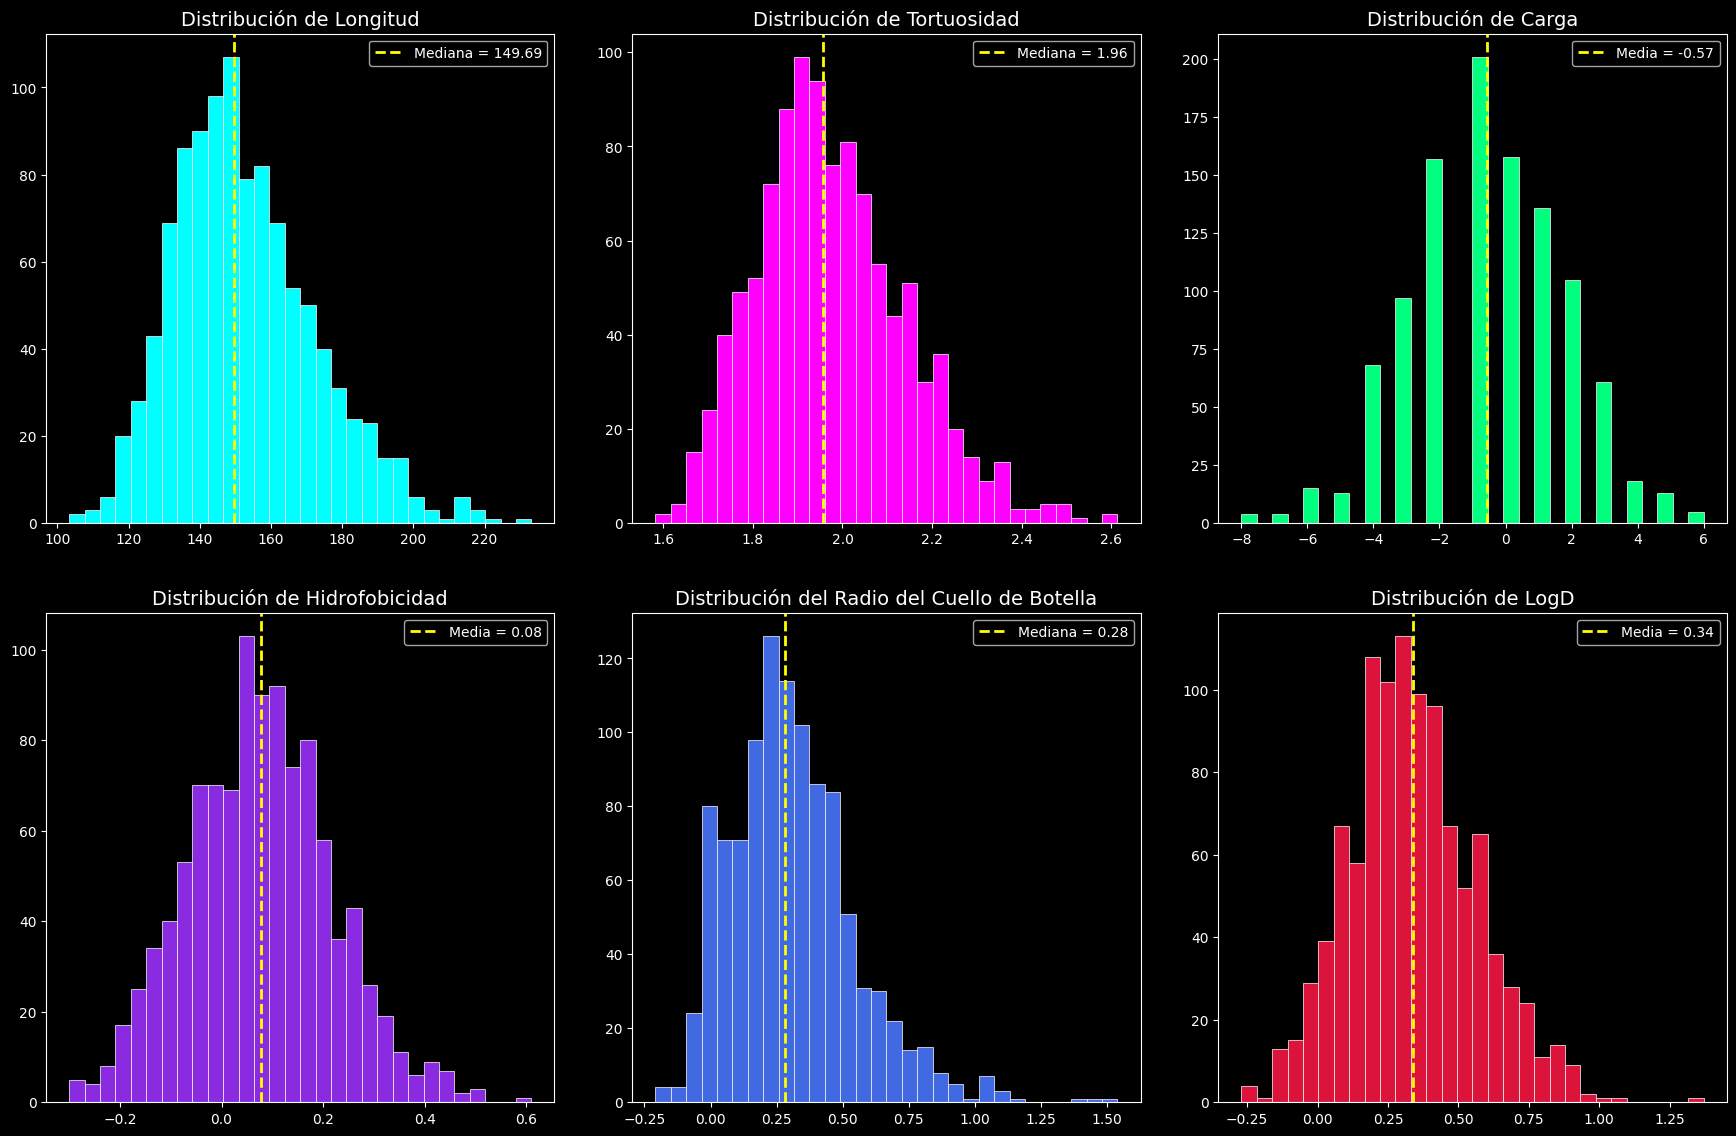

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns # Usado para mejores paletas de color si es necesario, aunque se usarán colores directos.

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

# Definir una paleta de colores fríos, casi neón
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C'] # Cian, Magenta, Verde Primavera, Azul Violeta, Azul Real, Carmesí (como un 'frío' rojo contrastante)

# Organizar cada histograma como subtrama:
fig, axs = plt.subplots(2, 3, figsize=(18, 12)) # Aumentar el tamaño de la figura para una mejor visibilidad
fig.patch.set_facecolor('black') # Establecer el fondo de la figura en negro

# Trazar cada histograma con colores personalizados y títulos minimalistas
axs[0, 0].hist(df_results['length'], bins=30, color=neon_colors[0], edgecolor='white', linewidth=0.5) # Añadir bins y color de borde para definición
axs[0, 0].set_title('Distribución de Longitud', color='white', fontsize=14) # Título minimalista
axs[0, 0].tick_params(colors='white') # Establecer el color de las marcas a blanco
axs[0, 0].set_facecolor('black') # Establecer el fondo de los ejes a negro
axs[0, 0].spines['left'].set_color('white') # Establecer el color de las líneas del gráfico
axs[0, 0].spines['bottom'].set_color('white')

mediana_longitud = df_results['length'].median()

axs[0, 0].axvline(
    mediana_longitud,
    color='yellow',
    linestyle='--',
    linewidth=2,
    label=f'Mediana = {mediana_longitud:.2f}'
)

axs[0, 0].legend()

axs[0, 1].hist(df_results['tortuosity'], bins=30, color=neon_colors[1], edgecolor='white', linewidth=0.5)
axs[0, 1].set_title('Distribución de Tortuosidad', color='white', fontsize=14)
axs[0, 1].tick_params(colors='white')
axs[0, 1].set_facecolor('black')
axs[0, 1].spines['left'].set_color('white')
axs[0, 1].spines['bottom'].set_color('white')

mediana_tortuosidad = df_results['tortuosity'].median()

axs[0, 1].axvline(
    mediana_tortuosidad,
    color='yellow',
    linestyle='--',
    linewidth=2,
    label=f'Mediana = {mediana_tortuosidad:.2f}'
)

axs[0, 1].legend()

axs[0, 2].hist(df_results['charge'], bins=30, color=neon_colors[2], edgecolor='white', linewidth=0.5)
axs[0, 2].set_title('Distribución de Carga', color='white', fontsize=14)
axs[0, 2].tick_params(colors='white')
axs[0, 2].set_facecolor('black')
axs[0, 2].spines['left'].set_color('white')
axs[0, 2].spines['bottom'].set_color('white')

media_carga = df_results['charge'].mean()

axs[0, 2].axvline(
    media_carga,
    color='yellow',
    linestyle='--',
    linewidth=2,
    label=f'Media = {media_carga:.2f}'
)

axs[0, 2].legend()

axs[1, 0].hist(df_results['hydrophobicity'], bins=30, color=neon_colors[3], edgecolor='white', linewidth=0.5)
axs[1, 0].set_title('Distribución de Hidrofobicidad', color='white', fontsize=14)
axs[1, 0].tick_params(colors='white')
axs[1, 0].set_facecolor('black')
axs[1, 0].spines['left'].set_color('white')
axs[1, 0].spines['bottom'].set_color('white')

media_hidrofobicidad = df_results['hydrophobicity'].mean()

axs[1, 0].axvline(
    media_hidrofobicidad,
    color='yellow',
    linestyle='--',
    linewidth=2,
    label=f'Media = {media_hidrofobicidad:.2f}'
)

axs[1, 0].legend()

axs[1, 1].hist(df_results['bottleneck_radius'], bins=30, color=neon_colors[4], edgecolor='white', linewidth=0.5)
axs[1, 1].set_title('Distribución del Radio del Cuello de Botella', color='white', fontsize=14)
axs[1, 1].tick_params(colors='white')
axs[1, 1].set_facecolor('black')
axs[1, 1].spines['left'].set_color('white')
axs[1, 1].spines['bottom'].set_color('white')

mediana_bottleneck = df_results['bottleneck_radius'].median()

axs[1, 1].axvline(
    mediana_bottleneck,
    color='yellow',
    linestyle='--',
    linewidth=2,
    label=f'Mediana = {mediana_bottleneck:.2f}'
)

axs[1, 1].legend()


axs[1, 2].hist(df_results['logd'], bins=30, color=neon_colors[5], edgecolor='white', linewidth=0.5)
axs[1, 2].set_title('Distribución de LogD', color='white', fontsize=14)
axs[1, 2].tick_params(colors='white')
axs[1, 2].set_facecolor('black')
axs[1, 2].spines['left'].set_color('white')
axs[1, 2].spines['bottom'].set_color('white')

media_logD = df_results['logd'].mean()

axs[1, 2].axvline(
    media_logD,
    color='yellow',
    linestyle='--',
    linewidth=2,
    label=f'Media = {media_logD:.2f}'
)

axs[1, 2].legend()

# Ajustar el diseño y mostrar
plt.tight_layout(pad=3.0) # Añadir relleno entre subtramas
plt.show()

# Restablecer el estilo predeterminado de matplotlib si no se pretenden más gráficos oscuros
plt.style.use('default')

In [ ]:
variables = [
    'length',
    'tortuosity',
    'charge',
    'hydrophobicity',
    'bottleneck_radius',
    'logd'
]

resumen = []

for var in variables:
    x = df_results[var].dropna()

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = x[(x < limite_inferior) | (x > limite_superior)]

    resumen.append({
        'Variable': var,
        'Media': x.mean(),
        'Mediana': x.median(),
        'Desv. estándar': x.std(),
        'Skewness': x.skew(),
        'Mínimo': x.min(),
        'Máximo': x.max(),
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'N outliers': len(outliers),
        'CV%': abs(x.std() / x.mean()) * 100,
        'Outliers': outliers.tolist()
    })

resumen_df = pd.DataFrame(resumen)

display(resumen_df)

,Variable,Media,Mediana,Desv. estándar,Skewness,Mínimo,Máximo,Q1,Q3,IQR,N outliers,CV%,Outliers
0,length,152.722837,149.694000,19.918530,0.631646,103.345000,233.132000,138.816500,164.543500,25.727000,15,13.042273,"[216.057, 213.512, 220.806, 219.369, 215.474, ..."
1,tortuosity,1.976032,1.956543,0.166906,0.540797,1.582569,2.613294,1.860193,2.076321,0.216128,15,8.446526,"[2.4528276735428407, 2.5399925896764928, 2.407..."
2,charge,-0.565877,-1.000000,2.318798,-0.032103,-8.000000,6.000000,-2.000000,1.000000,3.000000,13,409.770796,"[-8, -7, 6, -8, 6, 6, 6, -8, -8, -7, 6, -7, -7]"
3,hydrophobicity,0.076986,0.070000,0.140683,0.185524,-0.300000,0.610000,-0.020000,0.170000,0.190000,6,182.738745,"[0.49, 0.5, 0.61, 0.5, 0.47, 0.46]"
4,bottleneck_radius,0.309042,0.282000,0.235527,0.938136,-0.209000,1.539000,0.147000,0.440000,0.293000,23,76.211924,"[1.06, 1.075, 0.975, 1.043, 1.061, 1.146, 0.90..."
5,logd,0.338389,0.320000,0.224689,0.332895,-0.270000,1.370000,0.190000,0.480000,0.290000,11,66.399638,"[1.04, -0.26, 1.05, 0.93, 1.37, 0.96, -0.25, -..."


In [ ]:
def interpretar_skewness(skew):
    if abs(skew) < 0.5:
        return 'aproximadamente simétrica'
    elif skew >= 0.5 and skew < 1:
        return 'moderadamente asimétrica hacia la derecha'
    elif skew >= 1:
        return 'marcadamente asimétrica hacia la derecha'
    elif skew <= -0.5 and skew > -1:
        return 'moderadamente asimétrica hacia la izquierda'
    else:
        return 'marcadamente asimétrica hacia la izquierda'

for var in variables:
    skew = df_results[var].skew()
    print(var, ':', interpretar_skewness(skew))

length : moderadamente asimétrica hacia la derecha
tortuosity : moderadamente asimétrica hacia la derecha
charge : aproximadamente simétrica
hydrophobicity : aproximadamente simétrica
bottleneck_radius : moderadamente asimétrica hacia la derecha
logd : aproximadamente simétrica


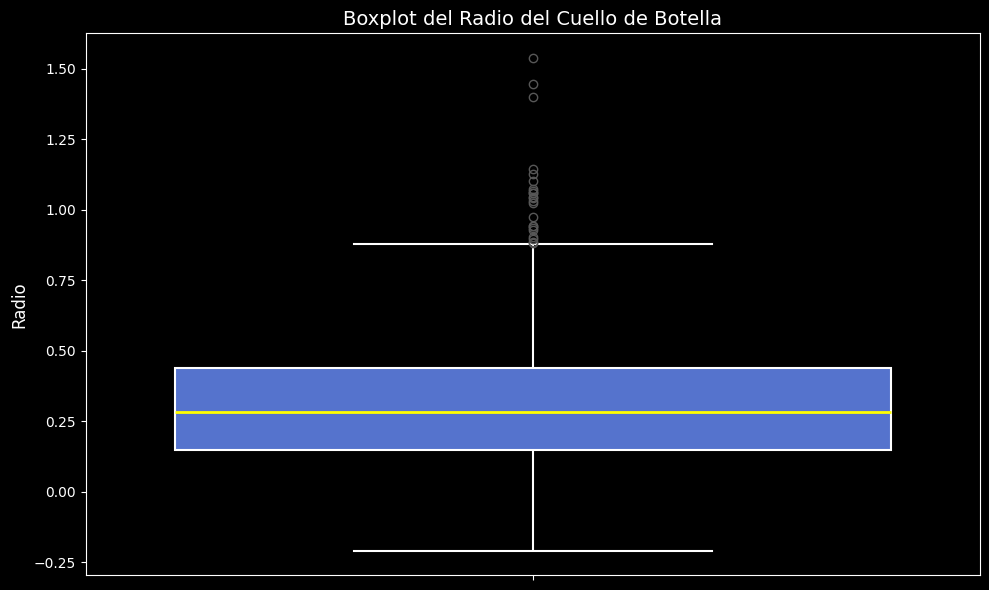

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(10, 6))

# Definir una paleta de colores fríos, casi neón (usando el mismo índice que en los histogramas)
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C']

sns.boxplot(
    data=df_results,
    y='bottleneck_radius',
    ax=ax, # Especificar el eje para el boxplot
    color=neon_colors[4], # Usar el color para bottleneck_radius
    boxprops=dict(edgecolor='white', linewidth=1.5),
    whiskerprops=dict(color='white', linewidth=1.5),
    capprops=dict(color='white', linewidth=1.5),
    medianprops=dict(color='yellow', linewidth=2)
)

# Configurar el fondo de la figura y los ejes a negro
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Configurar el color del título y las etiquetas a blanco
ax.set_title('Boxplot del Radio del Cuello de Botella', color='white', fontsize=14)
ax.set_ylabel('Radio', color='white', fontsize=12)
ax.set_xlabel('', color='white') # Eliminar la etiqueta del eje x si no es necesaria

# Configurar el color de los ticks y las espinas a blanco
ax.tick_params(colors='white', which='both')
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')
ax.spines['right'].set_color('white')
ax.spines['top'].set_color('white')

plt.tight_layout()
plt.show()

# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')

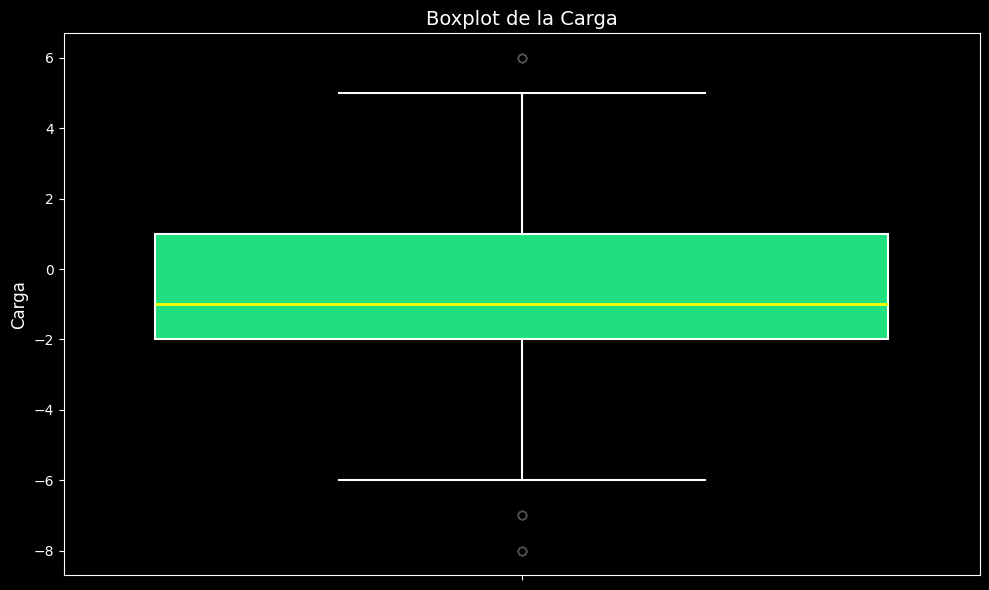

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(10, 6))

# Definir una paleta de colores fríos, casi neón (usando el mismo índice que en los histogramas)
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C']

sns.boxplot(
    data=df_results,
    y='charge',
    ax=ax, # Especificar el eje para el boxplot
    color=neon_colors[2], # Usar el color para charge
    boxprops=dict(edgecolor='white', linewidth=1.5),
    whiskerprops=dict(color='white', linewidth=1.5),
    capprops=dict(color='white', linewidth=1.5),
    medianprops=dict(color='yellow', linewidth=2)
)

# Configurar el fondo de la figura y los ejes a negro
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Configurar el color del título y las etiquetas a blanco
ax.set_title('Boxplot de la Carga', color='white', fontsize=14)
ax.set_ylabel('Carga', color='white', fontsize=12)
ax.set_xlabel('', color='white') # Eliminar la etiqueta del eje x si no es necesaria

# Configurar el color de los ticks y las espinas a blanco
ax.tick_params(colors='white', which='both')
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')
ax.spines['right'].set_color('white')
ax.spines['top'].set_color('white')

plt.tight_layout()
plt.show()

# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')


# Respuestas
1. ¿Qué variables presentan mayor variabilidad?
- De las elegidas, dada sus desviaciones estándar, IQR, mínimo y máximo, y habiendo estimado el CV% : *bottleneck_radius* y el logD. Todas las anteriores cumplen con tener CV% > 30 % y una desviación entandar de la misma magnitud a la mediana o media. El CV% de carga e hidrofobicidad son artificialmente elevados dado que sus medias son cercanas a 0 : en el caso de la carga, es de elevada variabilidad al tener una desviación estandar absoluta en un orden mayor a la media. Luego, la longitud y la tortuosidad al tener < 30 % de CV y una desviacion estandar en un orden menor a la mediana o media, son de baja variabilidad en comparación.

2. ¿Existen distribuciones claramente asimétricas?
- Si, de hecho por la medición del skewness y la observación del histograma se tienen algunas fuertemente asimétricas  como el radio de *bottleneck* (skewness = 0,938) y otras moderadas como  la longitud  (skewness = 0,632) o la tortuosidad (skewness = 0,541). Mientras que charge (skewness = −0,032) e hydrophobicity (skewness = 0,186) presentan distribuciones aproximadamente simétricas.

3. ¿Los valores extremos deben eliminarse automáticamente?
-No,  alguno outliers son parte de la distribución dada la asimetría de la misma como aprece ocurrir en el radio de *bottleneck* y no se han analizado aún si estos son artefactos de la dinámica o si son valores válidos de la misma. En este caso, dado que algunas variables presentan asimetría y una cantidad considerable de valores extremos, primero debería determinarse si estos valores corresponden a errores/artefactos o si representan observaciones válidas de la dinámica estudiada. Por lo tanto, los outliers deben investigarse antes de decidir eliminarlos.

---

# PARTE II — DINÁMICA TEMPORAL

## Actividad 3. El tiempo importa

Graficar en función de `frame`:

* `length`;
* `tortuosity`;
* `bottleneck_radius`;
* una variable fisicoquímica a elección.

### Preguntas

1. ¿Se observan tendencias temporales?
2. ¿Se observan períodos de estabilidad?
3. ¿Existen fluctuaciones?
4. ¿Se observan cambios abruptos?
5. ¿Las observaciones consecutivas parecen independientes?

Esta última pregunta será retomada al final del trabajo.


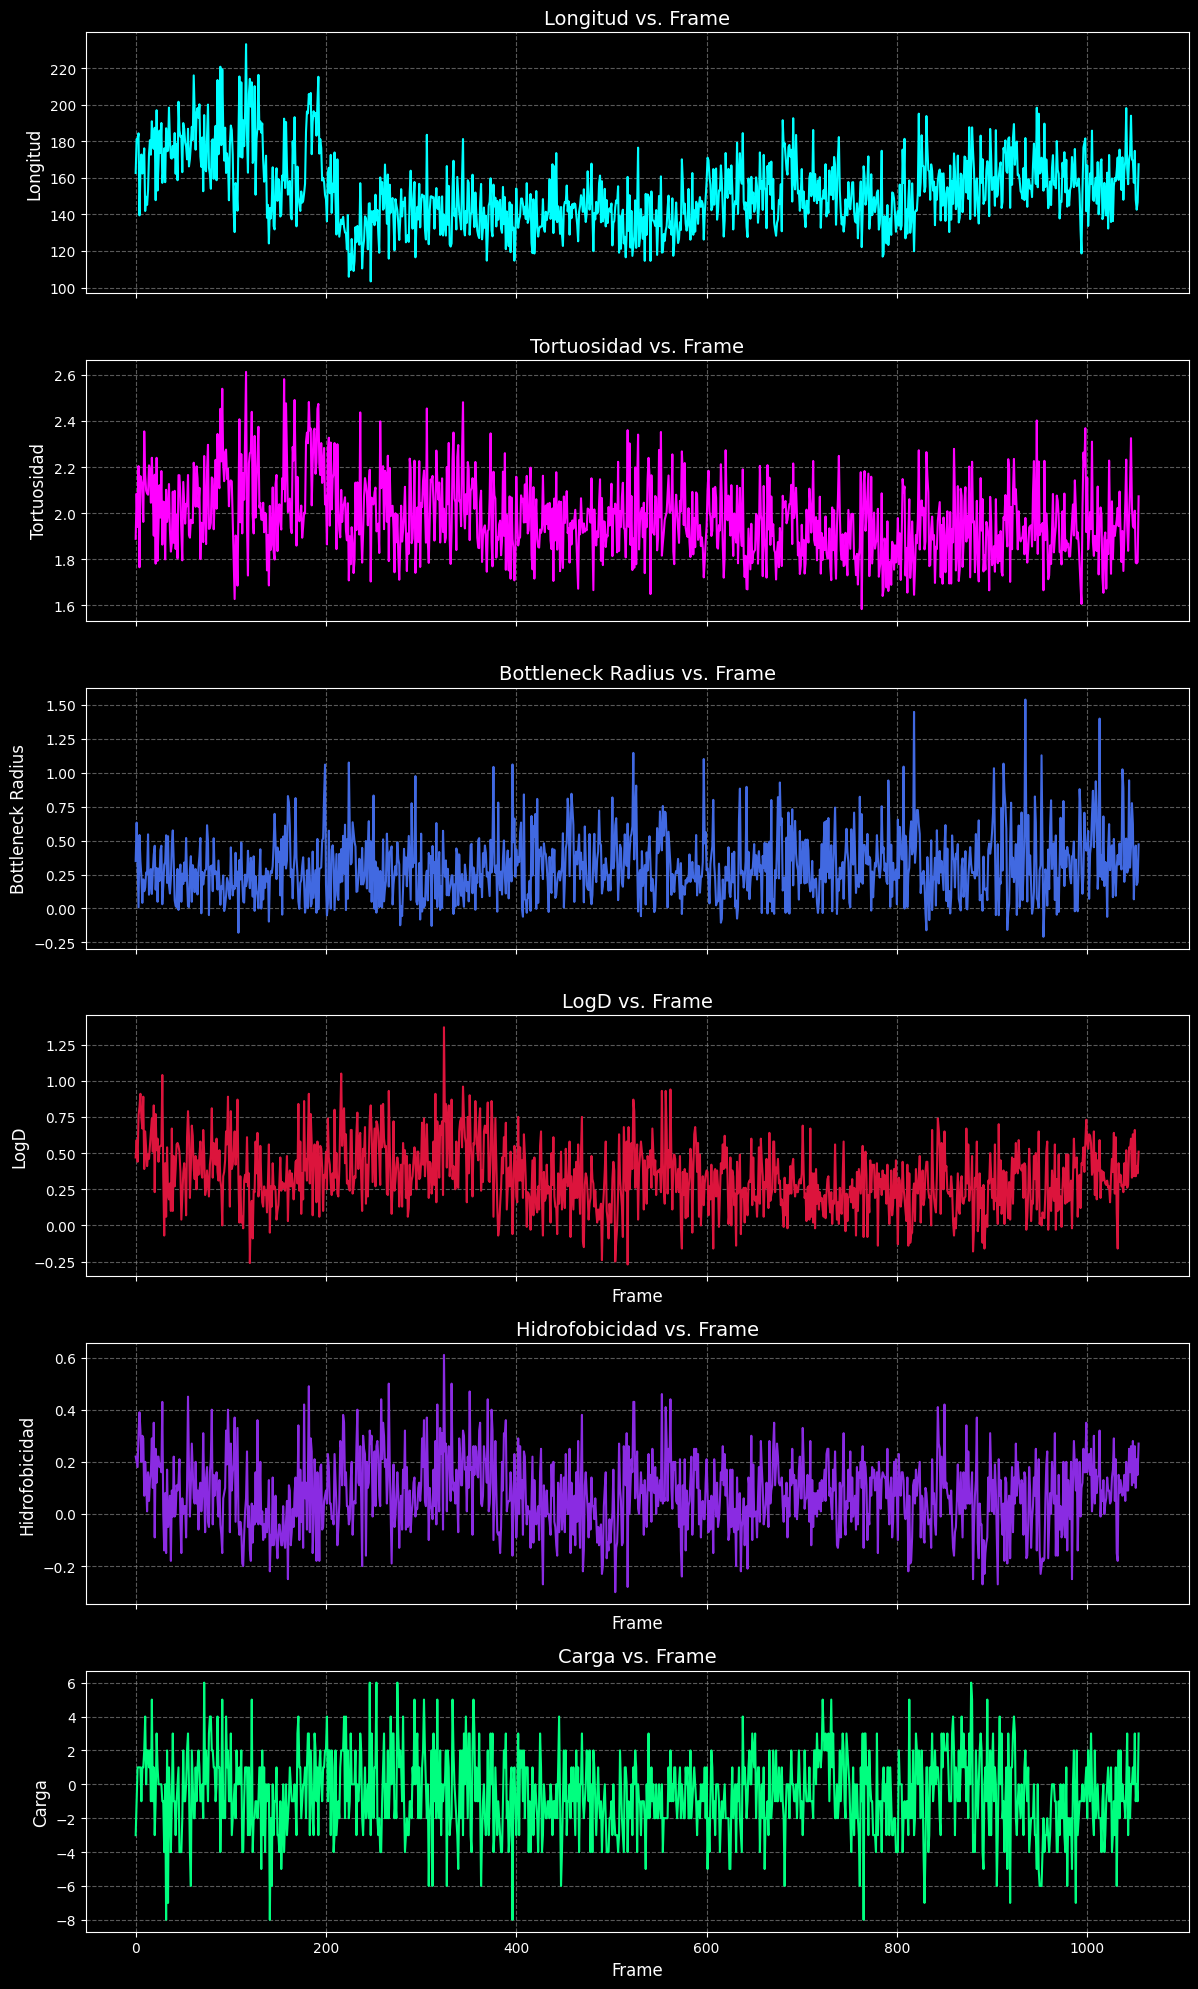

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(6, 1, figsize=(12, 20), sharex=True)
fig.patch.set_facecolor('black')

neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C']

# Gráfico length vs frame
axs[0].plot(df_results['frame'], df_results['length'], color=neon_colors[0], linewidth=1.5)
axs[0].set_title('Longitud vs. Frame', color='white', fontsize=14)
axs[0].set_ylabel('Longitud', color='white', fontsize=12)
axs[0].tick_params(colors='white', which='both')
axs[0].set_facecolor('black')
axs[0].spines['left'].set_color('white')
axs[0].spines['bottom'].set_color('white')
axs[0].spines['right'].set_color('white')
axs[0].spines['top'].set_color('white')
axs[0].grid(True, linestyle='--', alpha=0.7, color='gray')

# Gráfico Tortuosidad vs frame
axs[1].plot(df_results['frame'], df_results['tortuosity'], color=neon_colors[1], linewidth=1.5)
axs[1].set_title('Tortuosidad vs. Frame', color='white', fontsize=14)
axs[1].set_ylabel('Tortuosidad', color='white', fontsize=12)
axs[1].tick_params(colors='white', which='both')
axs[1].set_facecolor('black')
axs[1].spines['left'].set_color('white')
axs[1].spines['bottom'].set_color('white')
axs[1].spines['right'].set_color('white')
axs[1].spines['top'].set_color('white')
axs[1].grid(True, linestyle='--', alpha=0.7, color='gray')

# Gráfico bottleneck_radius vs frame
axs[2].plot(df_results['frame'], df_results['bottleneck_radius'], color=neon_colors[4], linewidth=1.5)
axs[2].set_title('Bottleneck Radius vs. Frame', color='white', fontsize=14)
axs[2].set_ylabel('Bottleneck Radius', color='white', fontsize=12)
axs[2].tick_params(colors='white', which='both')
axs[2].set_facecolor('black')
axs[2].spines['left'].set_color('white')
axs[2].spines['bottom'].set_color('white')
axs[2].spines['right'].set_color('white')
axs[2].spines['top'].set_color('white')
axs[2].grid(True, linestyle='--', alpha=0.7, color='gray')

# Gráfico logd vs frame
axs[3].plot(df_results['frame'], df_results['logd'], color=neon_colors[5], linewidth=1.5)
axs[3].set_title('LogD vs. Frame', color='white', fontsize=14)
axs[3].set_xlabel('Frame', color='white', fontsize=12)
axs[3].set_ylabel('LogD', color='white', fontsize=12)
axs[3].tick_params(colors='white', which='both')
axs[3].set_facecolor('black')
axs[3].spines['left'].set_color('white')
axs[3].spines['bottom'].set_color('white')
axs[3].spines['right'].set_color('white')
axs[3].spines['top'].set_color('white')
axs[3].grid(True, linestyle='--', alpha=0.7, color='gray')

# Gráfico hidrofobicidad vs frame
axs[4].plot(df_results['frame'], df_results['hydrophobicity'], color=neon_colors[3], linewidth=1.5)
axs[4].set_title('Hidrofobicidad vs. Frame', color='white', fontsize=14)
axs[4].set_xlabel('Frame', color='white', fontsize=12)
axs[4].set_ylabel('Hidrofobicidad', color='white', fontsize=12)
axs[4].tick_params(colors='white', which='both')
axs[4].set_facecolor('black')
axs[4].spines['left'].set_color('white')
axs[4].spines['bottom'].set_color('white')
axs[4].spines['right'].set_color('white')
axs[4].spines['top'].set_color('white')
axs[4].grid(True, linestyle='--', alpha=0.7, color='gray')

# Gráfico Carga vs frame
axs[5].plot(df_results['frame'], df_results['charge'], color=neon_colors[2], linewidth=1.5)
axs[5].set_title('Carga vs. Frame', color='white', fontsize=14)
axs[5].set_xlabel('Frame', color='white', fontsize=12)
axs[5].set_ylabel('Carga', color='white', fontsize=12)
axs[5].tick_params(colors='white', which='both')
axs[5].set_facecolor('black')
axs[5].spines['left'].set_color('white')
axs[5].spines['bottom'].set_color('white')
axs[5].spines['right'].set_color('white')
axs[5].spines['top'].set_color('white')
axs[5].grid(True, linestyle='--', alpha=0.7, color='gray')


plt.tight_layout()
plt.show()

# Reset default style for future plots
plt.style.use('default')

# Respuestas

1. ¿Se observan tendencias temporales?

- En general, no se observan tendencias temporales sostenidas en las variables analizadas: *bottleneck_radius*, carga y las variable fisicoquímicas como logD o hidrofobicidad presentan principalmente fluctuaciones alrededor de un valor aproximadamente constante. En el caso de longitud y un poco en la tortuosidad, sí se observa un comportamiento diferente: al comienzo presenta valores más elevados que posteriormente disminuyen progresivamente, hasta alcanzar una región donde las fluctuaciones se producen alrededor de un valor aproximadamente constante. Esto podría interpretarse como un comportamiento transitorio o de relajación inicial, seguido de un régimen más estable.

2. ¿Se observan períodos de estabilidad?

- Sí. Principalmente después del comportamiento inicial de length, las variables parecen entrar en un régimen donde fluctúan alrededor de una línea aproximadamente horizontal, sin una tendencia temporal evidente. Por lo tanto, puede hablarse de un período de estabilidad estadística, aunque no de ausencia de variaciones.

3. ¿Existen fluctuaciones?
- Sí. Las variables presentan variaciones alrededor de un valor medio, con algunos picos puntuales de valor elevado en algunos frames específicos según la variable: tortuosidad, longitud, logD e hidrofobicidad tienen sus mayores fluctuaciones al principio. En cambio, el radio de cuello de botella, los tienen a posterior o más al final o la carga tiene a lo largo de toda la dinamica picos de valores negativos.

4. ¿Se observan cambios abruptos?
- Se observan picos o valores puntuales alejados del comportamiento habitual, pero no necesariamente cambios abruptos sostenidos en el nivel de la variable. Es decir, hay fluctuaciones de gran amplitud en algunas observaciones, pero no parece haber un cambio permanente de régimen.

5. ¿Las observaciones consecutivas parecen independientes?
-No necesariamente. El comportamiento de length, especialmente su descenso progresivo inicial, sugiere que existe cierta dependencia entre observaciones consecutivas. Además, visualmente, una serie que presenta fluctuaciones alrededor de una línea no implica automáticamente independencia. En particular, si los puntos consecutivos tienden a permanecer cerca entre sí o a moverse en la misma dirección durante varios frames, existiría autocorrelación temporal. No obstante, a simple vista, hidrofobicidad y logD poseen un mismo perfil de oscilaciones, similar a como longitud y tortuosidad parecen tenerlo : habría que demostrar que entre estos dos pares hay correlación y que uno solo es un verdadero grado de libertad, mientras que el otro es una variable dependiente.


---

# PARTE III — CORRELACIÓN

## Actividad 4. Matriz de correlación

Construir una matriz de correlación para las variables cuantitativas seleccionadas.

Utilizar inicialmente la correlación de Pearson.

Representar la matriz mediante un heatmap.

Analizar especialmente las relaciones con: `bottleneck_radius`

### Preguntas

Seleccionar **tres asociaciones** que consideren interesantes.

Para cada una:

1. informar el coeficiente de correlación;
2. informar el intervalo de confianza;
3. realizar el contraste de hipótesis correspondiente;
4. representar gráficamente la relación;
5. interpretar la magnitud del efecto;
6. discutir su posible significado biológico.

### Atención

No basta con indicar:

> “La correlación es significativa.”

Deberán indicar también **qué tan fuerte es la asociación**.

Por ejemplo:

> Una asociación puede presentar un p-value pequeño pero representar una relación débil.

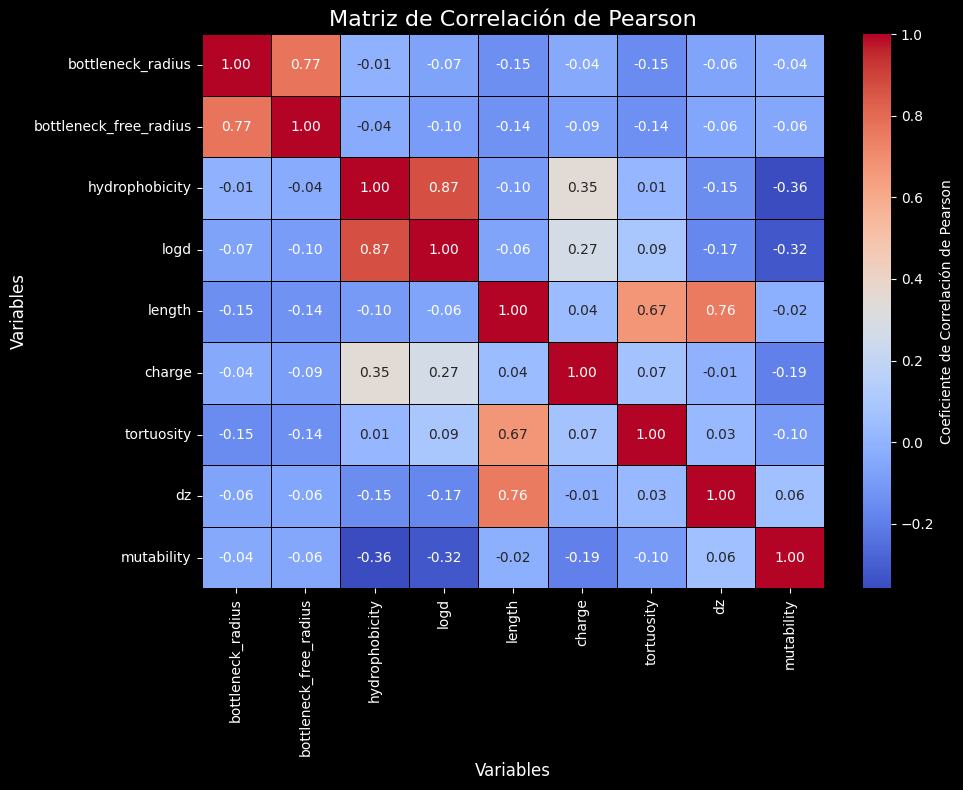

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

# Definir una paleta de colores fríos, casi neón
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C', '#FFFF00', '#FF6600']
# Cian, Magenta, Verde Primavera, Azul Violeta, Azul Real, Carmesí, Amarillo Neón, Naranja Neón

# Seleccionar las variables cuantitativas de interés
quantitative_vars = ['bottleneck_radius', 'bottleneck_free_radius', 'hydrophobicity', 'logd', 'length', 'charge', 'tortuosity', 'dz', 'mutability']
df_quantitative = df_results[quantitative_vars]

# Calcular la matriz de correlación de Pearson
correlation_matrix = df_quantitative.corr(method='pearson')

# Crear el heatmap
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('black')

sns.heatmap(correlation_matrix,
            annot=True, # Mostrar los valores de correlación en el mapa
            cmap='coolwarm', # Elegir un mapa de color que resalte los valores positivos y negativos
            fmt=".2f", # Formatear los números a dos decimales
            linewidths=.5, # Líneas entre celdas para mayor claridad
            linecolor='black', # Color de las líneas
            cbar_kws={'label': 'Coeficiente de Correlación de Pearson'})

# Personalizar el texto y ticks para que coincidan con la estética oscura
ax.set_title('Matriz de Correlación de Pearson', color='white', fontsize=16)
ax.tick_params(colors='white', which='both')
ax.set_xlabel('Variables', color='white', fontsize=12)
ax.set_ylabel('Variables', color='white', fontsize=12)

# Personalizar la barra de color
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.yaxis, 'ticklabels'), color='white')
cbar.set_label('Coeficiente de Correlación de Pearson', color='white')

plt.tight_layout()
plt.show()

# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')


--- Asociación 1: LogD vs Hidrofobicidad ---
Coeficiente de Correlación de Pearson (r): 0.870
Intervalo de Confianza del 95% para r: [0.855, 0.884]
Valor p: 0.00000000000000000000


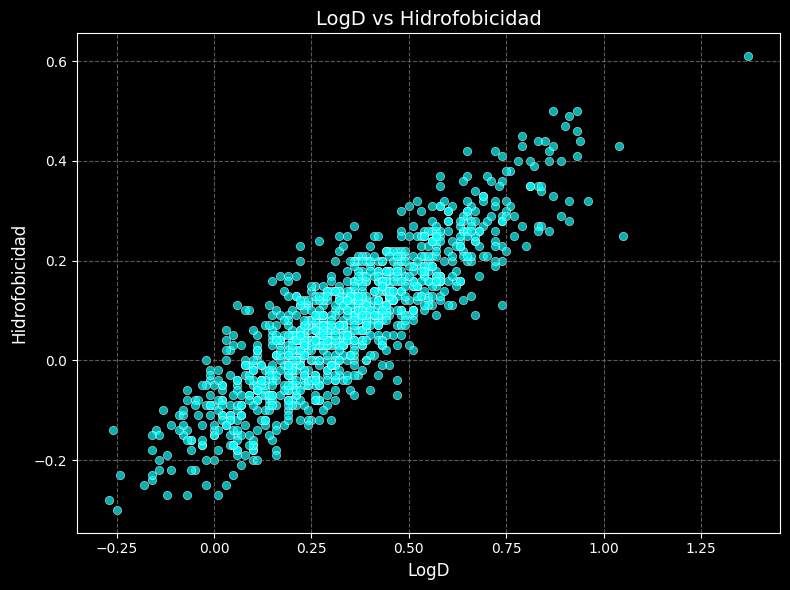


--- Asociación 2: Bottleneck Radius vs Length ---
Coeficiente de Correlación de Pearson (r): -0.146
Intervalo de Confianza del 95% para r: [-0.205, -0.086]
Valor p: 0.00000192667656473818


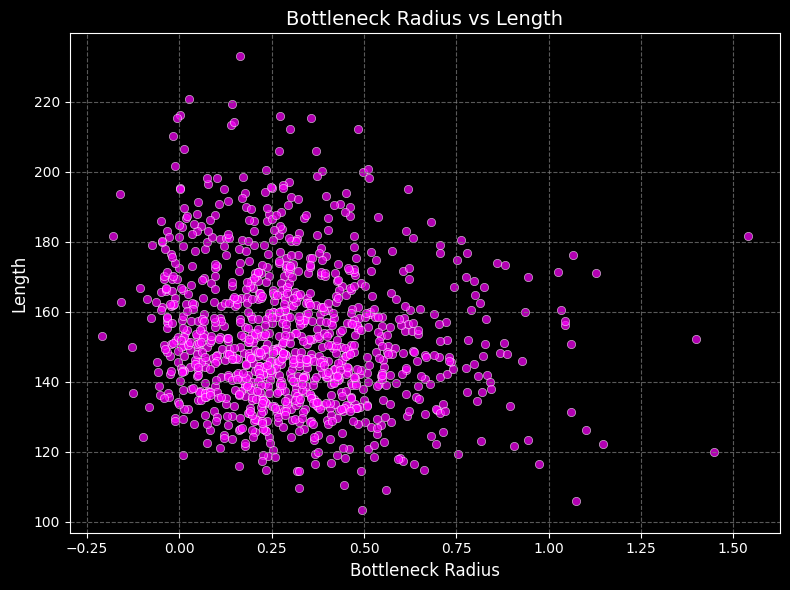


--- Asociación 3: Tortuosidad vs Longitud ---
Coeficiente de Correlación de Pearson (r): 0.674
Intervalo de Confianza del 95% para r: [0.639, 0.705]
Valor p: 0.00000000000000000000


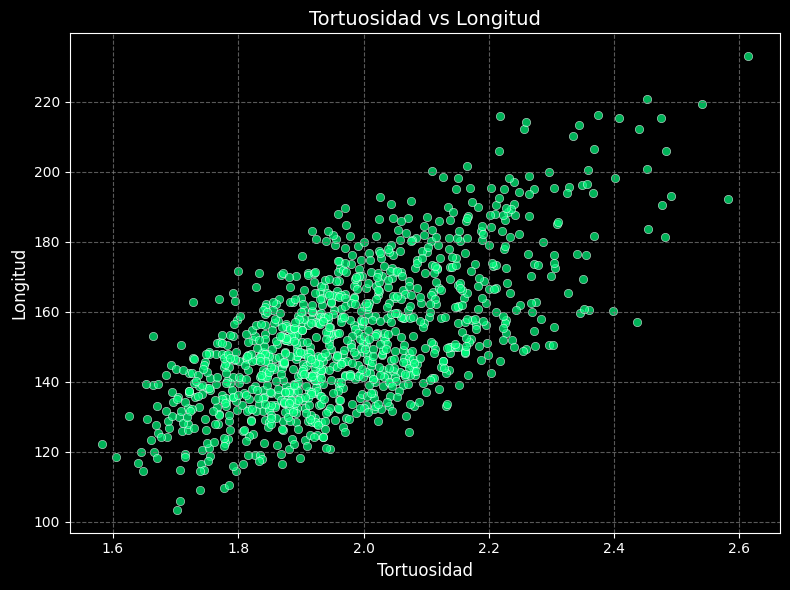


--- Asociación 4: Hidrofobicidad vs Carga ---
Coeficiente de Correlación de Pearson (r): 0.352
Intervalo de Confianza del 95% para r: [0.298, 0.404]
Valor p: 0.00000000000000000000


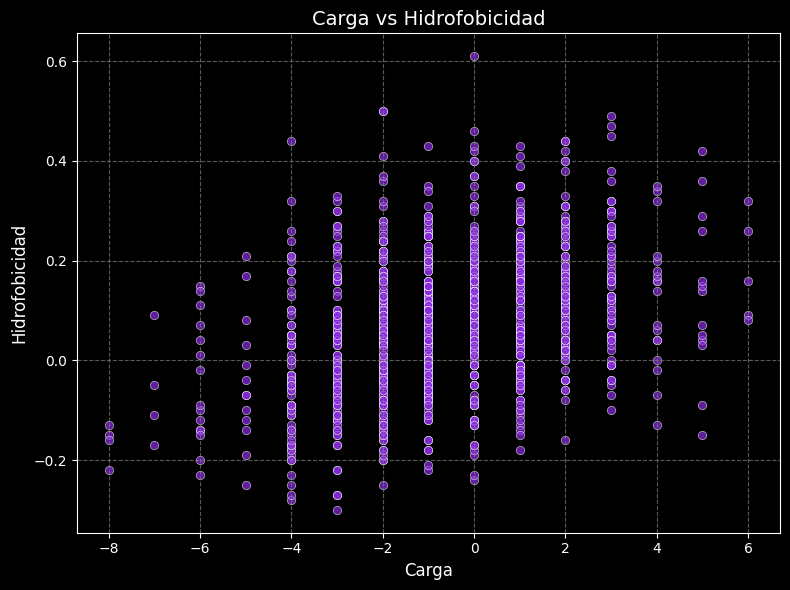


--- Asociación 5: bottleneck_radius vs dz ---
Coeficiente de Correlación de Pearson (r): -0.063
Intervalo de Confianza del 95% para r: [-0.123, -0.002]
Valor p: 0.04143838325090938579


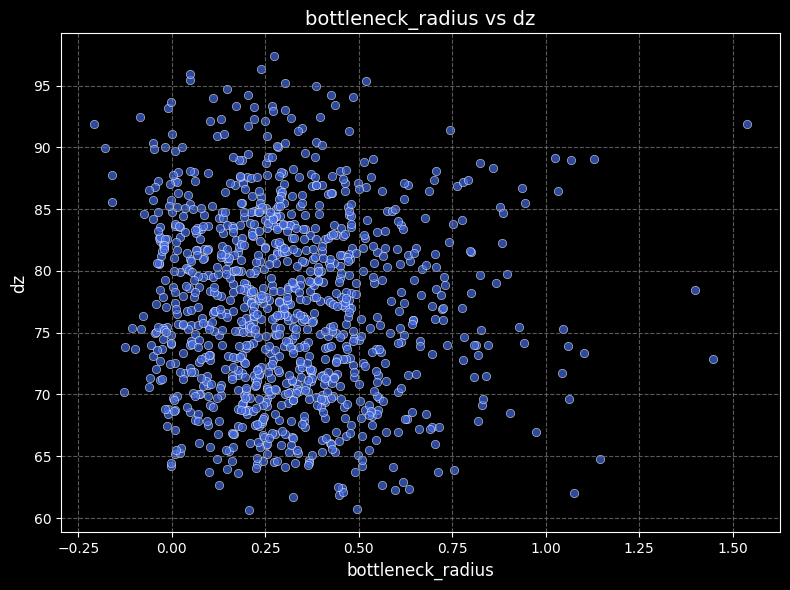


--- Asociación 6: bottleneck_radius vs tortuosity ---
Coeficiente de Correlación de Pearson (r): -0.154
Intervalo de Confianza del 95% para r: [-0.212, -0.094]
Valor p: 0.00000054349077679336


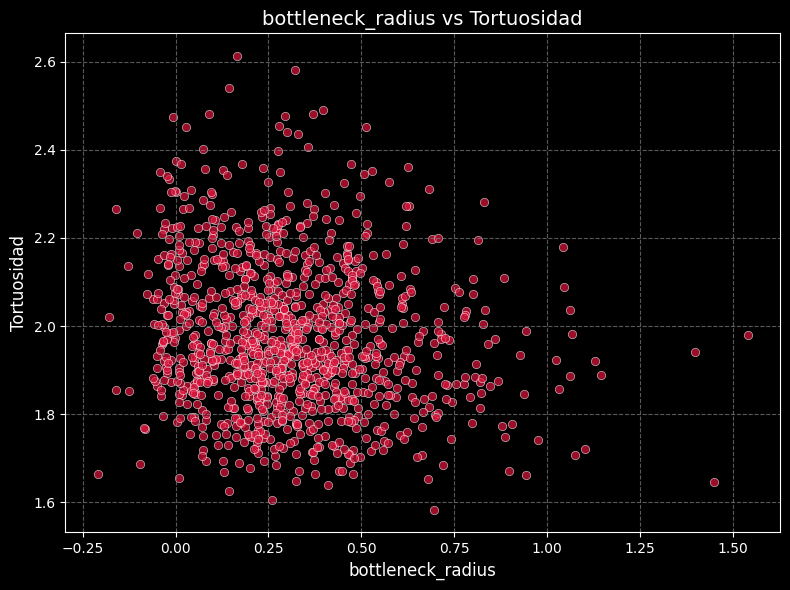


--- Asociación 7: bottleneck_radius vs bottleneck_free_radius ---
Coeficiente de Correlación de Pearson (r): 0.773
Intervalo de Confianza del 95% para r: [0.747, 0.796]
Valor p: 0.00000000000000000000


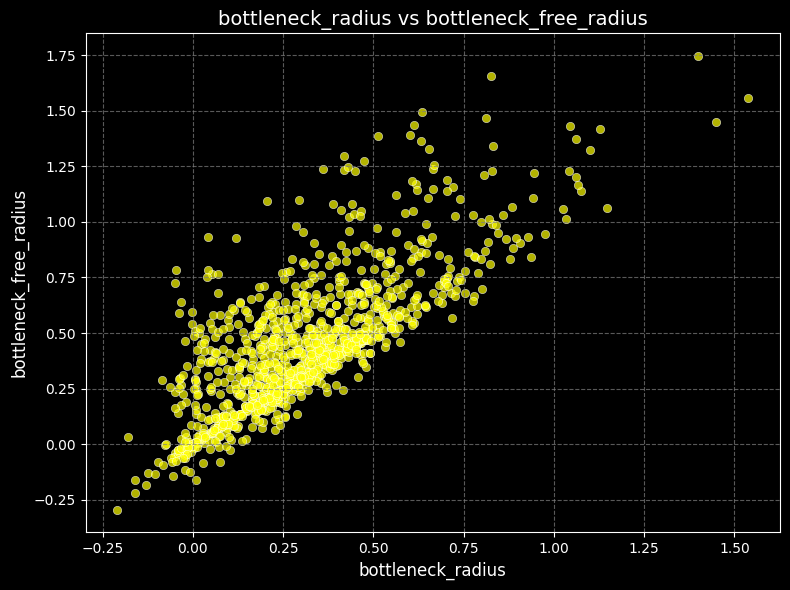

In [ ]:
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

# Definir una paleta de colores fríos, casi neón (ampliada para más opciones)
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C', '#FFFF00', '#FF6600', '#00BFFF', '#FFD700']

# Función para calcular el intervalo de confianza de Pearson r usando la transformación de Fisher
def pearson_r_ci(r, n, alpha=0.05):
    if n < 3: # Fisher's transformation requires n > 3
        return np.nan, np.nan
    z = 0.5 * np.log((1 + r) / (1 - r))
    se_z = 1 / np.sqrt(n - 3)
    z_crit = 1.96  # Para un IC del 95% (aprox. para alpha=0.05)
    z_lower = z - z_crit * se_z
    z_upper = z + z_crit * se_z
    r_lower = np.tanh(z_lower)
    r_upper = np.tanh(z_upper)
    return r_lower, r_upper

# --- Asociación 1: logD vs hydrophobicity ---
x1 = df_results['logd']
y1 = df_results['hydrophobicity']

r1, p1 = pearsonr(x1, y1)
n1 = len(x1)
ci1_lower, ci1_upper = pearson_r_ci(r1, n1)

print(f"\n--- Asociación 1: LogD vs Hidrofobicidad ---")
print(f"Coeficiente de Correlación de Pearson (r): {r1:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci1_lower:.3f}, {ci1_upper:.3f}]")
print(f"Valor p: {p1:.20f}")

# Representación gráfica
fig1, ax1 = plt.subplots(figsize=(8, 6))
fig1.patch.set_facecolor('black')

sns.scatterplot(x=x1, y=y1, ax=ax1, color=neon_colors[0], alpha=0.7)
ax1.set_title('LogD vs Hidrofobicidad', color='white', fontsize=14)
ax1.set_xlabel('LogD', color='white', fontsize=12)
ax1.set_ylabel('Hidrofobicidad', color='white', fontsize=12)
ax1.tick_params(colors='white', which='both')
ax1.set_facecolor('black')
ax1.spines['left'].set_color('white')
ax1.spines['bottom'].set_color('white')
ax1.spines['right'].set_color('white')
ax1.spines['top'].set_color('white')
ax1.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Asociación 2: bottleneck_radius vs length ---
x2 = df_results['bottleneck_radius']
y2 = df_results['length']

r2, p2 = pearsonr(x2, y2)
n2 = len(x2)
ci2_lower, ci2_upper = pearson_r_ci(r2, n2)

print(f"\n--- Asociación 2: Bottleneck Radius vs Length ---")
print(f"Coeficiente de Correlación de Pearson (r): {r2:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci2_lower:.3f}, {ci2_upper:.3f}]")
print(f"Valor p: {p2:.20f}")

# Representación gráfica
fig2, ax2 = plt.subplots(figsize=(8, 6))
fig2.patch.set_facecolor('black')

sns.scatterplot(x=x2, y=y2, ax=ax2, color=neon_colors[1], alpha=0.7)
ax2.set_title('Bottleneck Radius vs Length', color='white', fontsize=14)
ax2.set_xlabel('Bottleneck Radius', color='white', fontsize=12)
ax2.set_ylabel('Length', color='white', fontsize=12)
ax2.tick_params(colors='white', which='both')
ax2.set_facecolor('black')
ax2.spines['left'].set_color('white')
ax2.spines['bottom'].set_color('white')
ax2.spines['right'].set_color('white')
ax2.spines['top'].set_color('white')
ax2.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Asociación 3: tortuosity vs length ---
x3 = df_results['tortuosity']
y3 = df_results['length']

r3, p3 = pearsonr(x3, y3)
n3 = len(x3)
ci3_lower, ci3_upper = pearson_r_ci(r3, n3)

print(f"\n--- Asociación 3: Tortuosidad vs Longitud ---")
print(f"Coeficiente de Correlación de Pearson (r): {r3:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci3_lower:.3f}, {ci3_upper:.3f}]")
print(f"Valor p: {p3:.20f}")

# Representación gráfica
fig3, ax3 = plt.subplots(figsize=(8, 6))
fig3.patch.set_facecolor('black')

sns.scatterplot(x=x3, y=y3, ax=ax3, color=neon_colors[2], alpha=0.7)
ax3.set_title('Tortuosidad vs Longitud', color='white', fontsize=14)
ax3.set_xlabel('Tortuosidad', color='white', fontsize=12)
ax3.set_ylabel('Longitud', color='white', fontsize=12)
ax3.tick_params(colors='white', which='both')
ax3.set_facecolor('black')
ax3.spines['left'].set_color('white')
ax3.spines['bottom'].set_color('white')
ax3.spines['right'].set_color('white')
ax3.spines['top'].set_color('white')
ax3.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Asociación 4: charge vs hydrophobicity ---
x4 = df_results['charge']
y4 = df_results['hydrophobicity']

r4, p4 = pearsonr(x4, y4)
n4 = len(x4)
ci4_lower, ci4_upper = pearson_r_ci(r4, n4)


print(f"\n--- Asociación 4: Hidrofobicidad vs Carga ---")
print(f"Coeficiente de Correlación de Pearson (r): {r4:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci4_lower:.3f}, {ci4_upper:.3f}]")
print(f"Valor p: {p4:.20f}")

# Representación gráfica
fig4, ax4 = plt.subplots(figsize=(8, 6))
fig4.patch.set_facecolor('black')

sns.scatterplot(x=x4, y=y4, ax=ax4, color=neon_colors[3], alpha=0.7)
ax4.set_title('Carga vs Hidrofobicidad', color='white', fontsize=14)
ax4.set_xlabel('Carga', color='white', fontsize=12)
ax4.set_ylabel('Hidrofobicidad', color='white', fontsize=12)
ax4.tick_params(colors='white', which='both')
ax4.set_facecolor('black')
ax4.spines['left'].set_color('white')
ax4.spines['bottom'].set_color('white')
ax4.spines['right'].set_color('white')
ax4.spines['top'].set_color('white')
ax4.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Asociación 5: dz vs bottleneck_radius ---
x5 = df_results['bottleneck_radius']
y5 = df_results['dz']

r5, p5 = pearsonr(x5, y5)
n5 = len(x5)
ci5_lower, ci5_upper = pearson_r_ci(r5, n5)


print(f"\n--- Asociación 5: bottleneck_radius vs dz ---")
print(f"Coeficiente de Correlación de Pearson (r): {r5:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci5_lower:.3f}, {ci5_upper:.3f}]")
print(f"Valor p: {p5:.20f}")

# Representación gráfica
fig5, ax5 = plt.subplots(figsize=(8, 6))
fig5.patch.set_facecolor('black')

sns.scatterplot(x=x5, y=y5, ax=ax5, color=neon_colors[4], alpha=0.7)
ax5.set_title('bottleneck_radius vs dz', color='white', fontsize=14)
ax5.set_xlabel('bottleneck_radius', color='white', fontsize=12)
ax5.set_ylabel('dz', color='white', fontsize=12)
ax5.tick_params(colors='white', which='both')
ax5.set_facecolor('black')
ax5.spines['left'].set_color('white')
ax5.spines['bottom'].set_color('white')
ax5.spines['right'].set_color('white')
ax5.spines['top'].set_color('white')
ax5.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Asociación 6: Tortuosidad vs bottleneck_radius ---
x6 = df_results['bottleneck_radius']
y6 = df_results['tortuosity']

r6, p6 = pearsonr(x6, y6)
n6 = len(x6)
ci6_lower, ci6_upper = pearson_r_ci(r6, n6)


print(f"\n--- Asociación 6: bottleneck_radius vs tortuosity ---")
print(f"Coeficiente de Correlación de Pearson (r): {r6:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci6_lower:.3f}, {ci6_upper:.3f}]")
print(f"Valor p: {p6:.20f}")

# Representación gráfica
fig6, ax6 = plt.subplots(figsize=(8, 6))
fig6.patch.set_facecolor('black')

sns.scatterplot(x=x6, y=y6, ax=ax6, color=neon_colors[5], alpha=0.7)
ax6.set_title('bottleneck_radius vs Tortuosidad', color='white', fontsize=14)
ax6.set_xlabel('bottleneck_radius', color='white', fontsize=12)
ax6.set_ylabel('Tortuosidad', color='white', fontsize=12)
ax6.tick_params(colors='white', which='both')
ax6.set_facecolor('black')
ax6.spines['left'].set_color('white')
ax6.spines['bottom'].set_color('white')
ax6.spines['right'].set_color('white')
ax6.spines['top'].set_color('white')
ax6.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Asociación 7: bottleneck_free_radius vs bottleneck_radius ---
x7 = df_results['bottleneck_radius']
y7 = df_results['bottleneck_free_radius']

r7, p7 = pearsonr(x7, y7)
n7 = len(x7)
ci7_lower, ci7_upper = pearson_r_ci(r7, n7)


print(f"\n--- Asociación 7: bottleneck_radius vs bottleneck_free_radius ---")
print(f"Coeficiente de Correlación de Pearson (r): {r7:.3f}")
print(f"Intervalo de Confianza del 95% para r: [{ci7_lower:.3f}, {ci7_upper:.3f}]")
print(f"Valor p: {p7:.20f}")

# Representación gráfica
fig7, ax7 = plt.subplots(figsize=(8, 6))
fig7.patch.set_facecolor('black')

sns.scatterplot(x=x7, y=y7, ax=ax7, color=neon_colors[6], alpha=0.7)
ax7.set_title('bottleneck_radius vs bottleneck_free_radius', color='white', fontsize=14)
ax7.set_xlabel('bottleneck_radius', color='white', fontsize=12)
ax7.set_ylabel('bottleneck_free_radius', color='white', fontsize=12)
ax7.tick_params(colors='white', which='both')
ax7.set_facecolor('black')
ax7.spines['left'].set_color('white')
ax7.spines['bottom'].set_color('white')
ax7.spines['right'].set_color('white')
ax7.spines['top'].set_color('white')
ax7.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')

# Respuestas


### Asociación LogD vs. Hidrofobicidad
El coeficiente de correlación de Pearson es de 0,87 indica una asociación positiva fuerte entre el LogD y la hidrofobicidad. El p-valor es de 0 < 0,05, lo que confirma que esta correlación es significativa estadísticamente. Esto sugiere que a medida que aumenta el valor de LogD (mayor lipofilia), la hidrofobicidad del túnel también tiende a ser mayor, lo cual tiene sentido bioquímica, es decir, esta fuerte asociación tiene sentido biológicamente ya que ambas variables son medidas relacionadas con las propiedades de interacción de la molécula con entornos lipídicos/acuosos.

### Asociación Bottleneck_radius vs. longitud
El coeficiente de correlación de Pearson es de -0,146 que indica una asociación negativa muy débil entre el radio del cuello de botella y la longitud, y es significativa (p-value : 1,93E-6 < 0,05). Esto sugiere que, en general, un túnel más largo tiende a tener un cuello de botella ligeramente más estrecho, pero la magnitud del efecto es pequeña, lo que implica que la longitud explica solo una pequeña porción de la variabilidad del radio del cuello de botella.

### Asociación Tortuosidad vs. longitud
El coeficiente de correlación de Pearson es de 0,674 lo que indica una asociación positiva (no muy fuerte) entre la tortuosidad y la longitud y con una  significancia estadística (p-value : 0 < 0,05). Esto implica que la tortuosidad y la longitud del túnel son dependientes, es decir, un túnel más tortuoso puede ser más largo en este contexto: bioquímicamente, esto podría indicar que la complejidad del camino está directamente relacionada parcialmente (no se sabe aún si es la única variable con solo ver esta correlación) con la extensión total del túnel en el rango observado.

### Asociación Carga vs. Hidrofobicidad
El coeficiente de correlación de Pearson es de 0,352 que indica una asociación negativa muy débil entre la carga y la hidrofobicidad, y es significativa (p-value : 0 < 0,05). La carga puede tener un efecto en la lipofilicidad de una proteína, aunque particularmente y de hecho puede observase en el gráfico : la hidrofobicidad tiende a ser mas elevada cuando la carga tiende a 0.

### Asociación Bottleneck_radius vs. dz
El coeficiente de correlación de Pearson es de -0,062 que indica una asociación casi nula entre el radio de cuello de botella y la dz, y es por poco casi no significativa (p-value : 0,0414 < 0,05). No hay relación alguna entre estas dos variables que justifique una interpretación biológica.

### Asociación Bottleneck_radius vs. Tortuosidad
El coeficiente de correlación de Pearson es de -0,154 que indica una asociación negativa muy débil entre el radio del cuello de botella y la longitud, y es significativa (p-value : 5,43E-7 < 0,05). Junto con la anterior : o no hay realmente un efecto biológico y son independientes, o este efecto es muy bajo y podría despreciarse dada la baja correlación.

### Asociación Bottleneck_radius vs. bottleneck_free_radius
El coeficiente de correlación de Pearson es de 0,773 que indica una asociación positiva fuerte entre el radio del cuello de botella y el radio de cuello de botella libre, y es significativa (p-value : 5,43E-7 < 0,05). Esto tiene sentido al ser dos parametros de la misma magnitud de la proteína (son dos estimaciones con algoritmos difernetes: uno considera el readio de van der Waals y otro no, o bien, ignora la ocupación rígida de los átomos adyacentes).

---

# PARTE IV — REGRESIÓN LINEAL

## Actividad 5. Regresión lineal simple

Utilizar:

```text
bottleneck_radius
```

como variable respuesta.

Construir un modelo de regresión lineal simple utilizando como predictor una variable que, según el análisis anterior, pueda estar relacionada con el radio del cuello de botella.

Una opción posible es:

```text
bottleneck_radius ~ tortuosity
```

pero deberán justificar su elección.

### Informar

* ecuación del modelo;
* intercepto;
* pendiente;
* error estándar;
* intervalo de confianza;
* p-value;
* R²;
* interpretación de la pendiente.

Realizar un gráfico con:

* observaciones;
* recta de regresión;
* intervalo de confianza.

### Pregunta

¿Qué significa biológicamente una pendiente negativa o positiva?

¿Podemos afirmar que el predictor **causa** cambios en el radio?

Justificar.



--- Modelo de Regresión Lineal Simple: bottleneck_radius ~ tortuosity ---
                            OLS Regression Results                            
Dep. Variable:      bottleneck_radius   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     25.42
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           5.43e-07
Time:                        19:19:23   Log-Likelihood:                 41.559
No. Observations:                1055   AIC:                            -79.12
Df Residuals:                    1053   BIC:                            -69.20
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

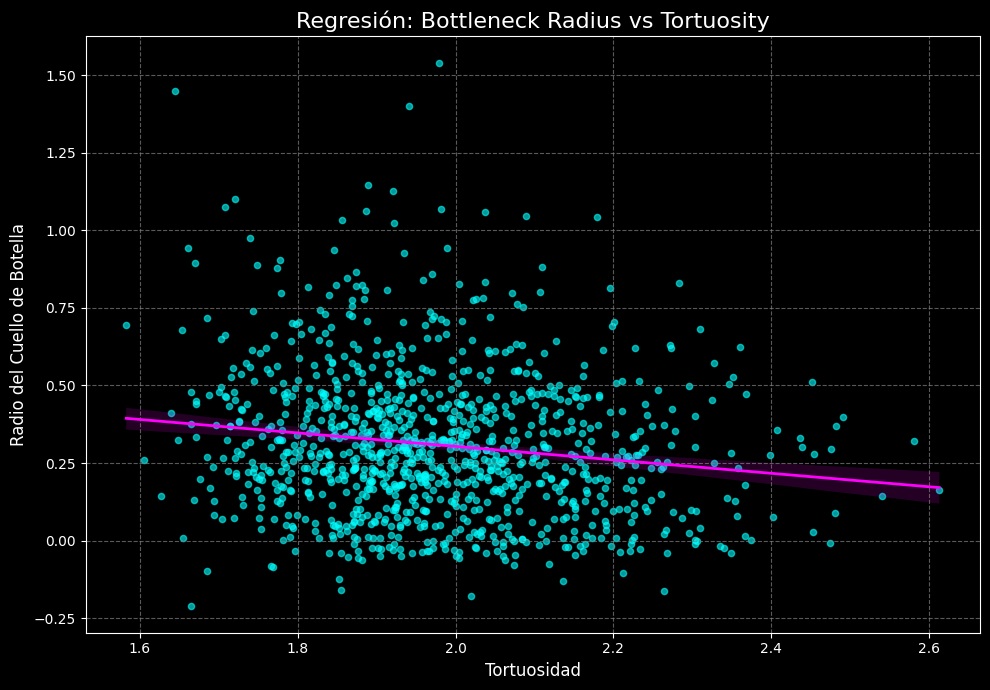


--- Modelo de Regresión Lineal Simple: bottleneck_radius ~ length ---
                            OLS Regression Results                            
Dep. Variable:      bottleneck_radius   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     22.92
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.93e-06
Time:                        19:19:23   Log-Likelihood:                 40.338
No. Observations:                1055   AIC:                            -76.68
Df Residuals:                    1053   BIC:                            -66.75
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------

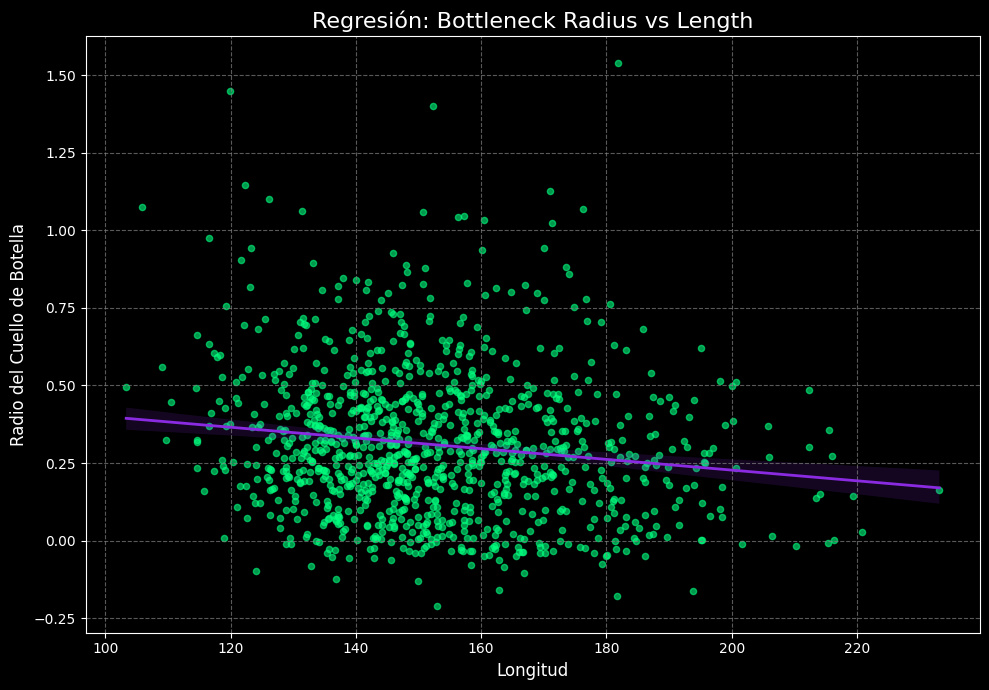


--- Modelo de Regresión Lineal Simple: bottleneck_radius ~ bottleneck_free_radius ---
                            OLS Regression Results                            
Dep. Variable:      bottleneck_radius   R-squared:                       0.597
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     1562.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):          3.32e-210
Time:                        19:19:23   Log-Likelihood:                 508.78
No. Observations:                1055   AIC:                            -1014.
Df Residuals:                    1053   BIC:                            -1004.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

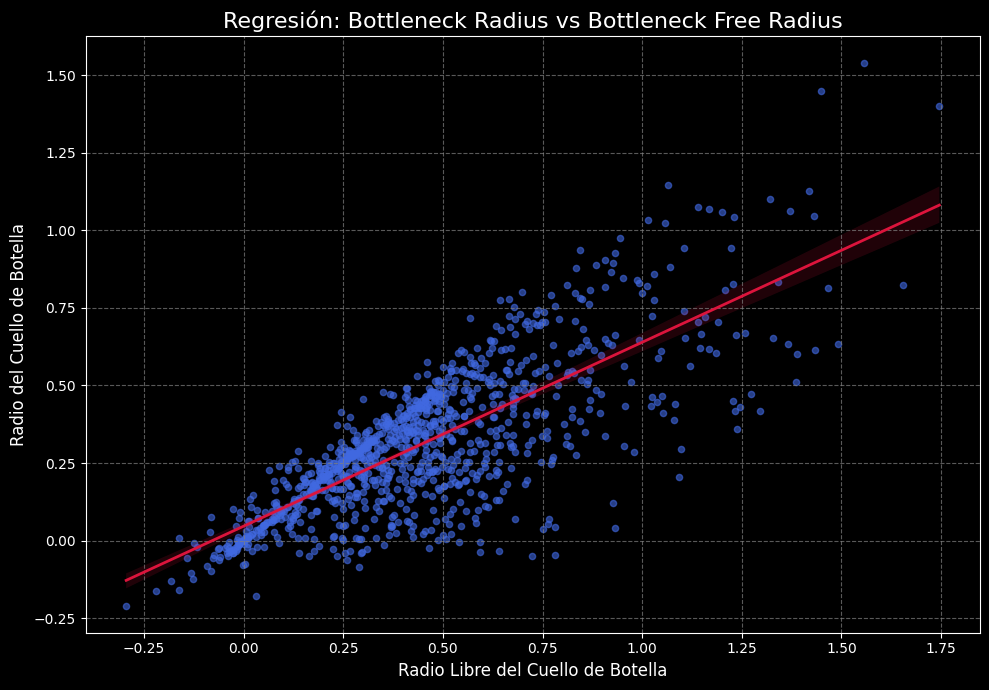

In [ ]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

# Definir una paleta de colores fríos, casi neón
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C', '#FFFF00', '#FF6600', '#00BFFF', '#FFD700']

# --- Regresión 1: bottleneck_radius ~ tortuosity ---
print("\n--- Modelo de Regresión Lineal Simple: bottleneck_radius ~ tortuosity ---")
model1 = smf.ols('bottleneck_radius ~ tortuosity', data=df_results).fit()
print(model1.summary())

# Obtener los parámetros del modelo para la interpretación
intercept1 = model1.params['Intercept']
slope1 = model1.params['tortuosity']

# Representación gráfica
fig1, ax1 = plt.subplots(figsize=(10, 7))
fig1.patch.set_facecolor('black')

sns.regplot(x='tortuosity', y='bottleneck_radius', data=df_results, ax=ax1,
            scatter_kws={'color': neon_colors[0], 'alpha': 0.6, 's': 20},
            line_kws={'color': neon_colors[1], 'linewidth': 2},
            ci=95) # Intervalo de confianza del 95%

ax1.set_title('Regresión: Bottleneck Radius vs Tortuosity', color='white', fontsize=16)
ax1.set_xlabel('Tortuosidad', color='white', fontsize=12)
ax1.set_ylabel('Radio del Cuello de Botella', color='white', fontsize=12)
ax1.tick_params(colors='white', which='both')
ax1.set_facecolor('black')
ax1.spines['left'].set_color('white')
ax1.spines['bottom'].set_color('white')
ax1.spines['right'].set_color('white')
ax1.spines['top'].set_color('white')
ax1.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()



# --- Regresión 2: bottleneck_radius ~ length ---
print("\n--- Modelo de Regresión Lineal Simple: bottleneck_radius ~ length ---")
model2 = smf.ols('bottleneck_radius ~ length', data=df_results).fit()
print(model2.summary())

# Obtener los parámetros del modelo para la interpretación
intercept2 = model2.params['Intercept']
slope2 = model2.params['length']

# Representación gráfica
fig2, ax2 = plt.subplots(figsize=(10, 7))
fig2.patch.set_facecolor('black')

sns.regplot(x='length', y='bottleneck_radius', data=df_results, ax=ax2,
            scatter_kws={'color': neon_colors[2], 'alpha': 0.6, 's': 20},
            line_kws={'color': neon_colors[3], 'linewidth': 2},
            ci=95) # Intervalo de confianza del 95%

ax2.set_title('Regresión: Bottleneck Radius vs Length', color='white', fontsize=16)
ax2.set_xlabel('Longitud', color='white', fontsize=12)
ax2.set_ylabel('Radio del Cuello de Botella', color='white', fontsize=12)
ax2.tick_params(colors='white', which='both')
ax2.set_facecolor('black')
ax2.spines['left'].set_color('white')
ax2.spines['bottom'].set_color('white')
ax2.spines['right'].set_color('white')
ax2.spines['top'].set_color('white')
ax2.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- Regresión 3: bottleneck_radius ~ bottleneck_free_radius ---
print("\n--- Modelo de Regresión Lineal Simple: bottleneck_radius ~ bottleneck_free_radius ---")
model3 = smf.ols('bottleneck_radius ~ bottleneck_free_radius', data=df_results).fit()
print(model3.summary())

# Obtener los parámetros del modelo para la interpretación
intercept3 = model3.params['Intercept']
slope3 = model3.params['bottleneck_free_radius']

# Representación gráfica
fig3, ax3 = plt.subplots(figsize=(10, 7))
fig3.patch.set_facecolor('black')

sns.regplot(x='bottleneck_free_radius', y='bottleneck_radius', data=df_results, ax=ax3,
            scatter_kws={'color': neon_colors[4], 'alpha': 0.6, 's': 20},
            line_kws={'color': neon_colors[5], 'linewidth': 2},
            ci=95) # Intervalo de confianza del 95%

ax3.set_title('Regresión: Bottleneck Radius vs Bottleneck Free Radius', color='white', fontsize=16)
ax3.set_xlabel('Radio Libre del Cuello de Botella', color='white', fontsize=12)
ax3.set_ylabel('Radio del Cuello de Botella', color='white', fontsize=12)
ax3.tick_params(colors='white', which='both')
ax3.set_facecolor('black')
ax3.spines['left'].set_color('white')
ax3.spines['bottom'].set_color('white')
ax3.spines['right'].set_color('white')
ax3.spines['top'].set_color('white')
ax3.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()


# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')

# Respuestas

bottleneck_radius = b_r
tortuosity = tor
length = l

### Regresión 1: bottleneck_radius ~ tortuosity

- La ecuación es b_r = -0,216 * tor + 0,737, con errores estandar de 0,085 y 0,043 respectivamente e intervalos de confianza al 95% de [0,57, 0,94] y [-0,301, -0,132] respectivamente. Interpretación de la pendiente: Por cada unidad de aumento en la tortuosidad, el radio del cuello de botella disminuye en -0,216 unidades. La relación es estadísticamente significativa (p-valor: 5,43E-7 < 0,05) pero la R² es muy baja (0,023), indicando que la tortuosidad explica muy poca de la variabilidad en el radio del cuello de botella.

### Regresión 2: bottleneck_radius ~ length

- La ecuación es b_r = 0,573 * l + 0,047, con errores estandar de 0,056 y 0,008 respectivamente e intervalos de confianza al 95% de [0,464, 0,682] y [-0,002, -0,001] respectivamente. Interpretación de la pendiente: Por cada unidad de aumento en la tortuosidad, el radio del cuello de botella aumenta en 0,573 unidades. La relación es estadísticamente significativa (p-valor: 1,93E-6 < 0,05) pero la R² es de nuevo muy baja (0,020), lo que significa que la longitud tiene un impacto muy limitado en la predicción del radio del cuello de botella.


### Regresión 3: bottleneck_radius ~ bottleneck_free_radius

- La ecuación es b_r = 0,592 * b_f_r - 0,002, con errores estandar de 0,015 y 0,0 respectivamente e intervalos de confianza al 95% de [0,563, 0,622] y [0,031, 0,063] respectivamente. Interpretación de la pendiente: Por cada unidad de aumento en la tortuosidad, el radio del cuello de botella aumenta en 0,592 unidades. La relación es estadísticamente significativa (p-valor: 3,32E-210 < 0,05) y ek R² es ahora signficativo o intersante (0,597), lo que significa que ambas variables claramente aumentan linealmente una respecto de la otra.



1.  ¿Qué significa biológicamente una pendiente negativa o positiva?

- La pendiente representa la dirección y magnitud de la asociación entre el predictor y bottleneck_radius, dentro del modelo lineal. Una pendiente positiva indica que, cuando aumenta el predictor, también tiende a aumentar el bottleneck_radius, mientras que una pendiente negativa indica que, cuando aumenta el predictor, el bottleneck_radius tiende a disminuir.En este caso:

  *  Para tortuosity, la pendiente es −0,216. Esto indica una asociación negativa: valores mayores de tortuosidad están asociados con valores menores de bottleneck_radius.

  *  Para length, la pendiente es +0,573, indicando una asociación positiva entre ambas variables.

  * Para bottleneck_free_radius, la pendiente es +0,592, indicando una asociación positiva fuerte entre ambas medidas.

  Sin embargo, estas pendientes describen asociaciones estadísticas y no necesariamente relaciones biológicas causales. Además, en los dos primeros modelos los R² son muy bajos (0,023 y 0,020), por lo que, aunque las asociaciones sean estadísticamente significativas, explican una proporción muy pequeña de la variabilidad observada en bottleneck_radius.


2. ¿Podemos afirmar que el predictor causa cambios en el radio?

- No. La significancia estadística y una correlación elevada no permiten establecer causalidad por sí solas. Esto es particularmente importante en el tercer modelo. bottleneck_radius y bottleneck_free_radius representan medidas relacionadas de una misma propiedad obtenidas mediante diferentes procedimientos algorítmicos. Por lo tanto, es esperable que exista una asociación entre ellas. El hecho de que presenten una relación lineal fuerte (R² = 0,597) indica que ambas medidas están relacionadas, pero no demuestra que una provoque cambios en la otra. Del mismo modo, que tortuosity y length tengan pendientes estadísticamente significativas no permite concluir que cambios en estas variables causen cambios en el radio.

---

# PARTE V — REGRESIÓN MÚLTIPLE

## Actividad 6. Construcción del modelo

Construir un modelo de regresión múltiple para explicar:

```text
bottleneck_radius
```

Utilizar varios predictores.

Como punto de partida puede utilizarse:

```text
bottleneck_radius ~ tortuosity +
                    length +
                    polarity +
                    hydrophobicity +
                    charge
```

También podrán proponer otro modelo, pero deberán justificar la selección de las variables.

### Analizar

1. coeficientes;
2. errores estándar;
3. intervalos de confianza;
4. p-values;
5. R²;
6. R² ajustado.

### Preguntas

**a.** ¿Qué predictor parece tener mayor asociación con la respuesta?

**b.** ¿Todos los predictores significativos en modelos simples permanecen significativos en el modelo múltiple?

**c.** ¿Por qué podría cambiar el coeficiente de una variable al agregar otros predictores?


In [ ]:
import statsmodels.formula.api as smf

print("\n--- Modelo de Regresión Lineal Múltiple: bottleneck_radius ~ tortuosity + length + polarity + hydrophobicity + charge ---")
model_multiple = smf.ols('bottleneck_radius ~ tortuosity + length + polarity + hydrophobicity + charge', data=df_results).fit()
print(model_multiple.summary())



--- Modelo de Regresión Lineal Múltiple: bottleneck_radius ~ tortuosity + length + polarity + hydrophobicity + charge ---
                            OLS Regression Results                            
Dep. Variable:      bottleneck_radius   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     8.684
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           4.44e-08
Time:                        19:19:30   Log-Likelihood:                 50.371
No. Observations:                1055   AIC:                            -88.74
Df Residuals:                    1049   BIC:                            -58.97
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----

# Respuestas

El modelo es:
  
   b_r = 0,5376 - 0,1267 tor -0,0008 l + 0,0128 polarity+0,0961 hydrophobicity - 0,0035 charge

   Los valores de errores estandar son bajos para cada coeficiente y cada uno entra en su respectivo intervalo de confianza. De nuevo, el R² resulta bajo (es de 0,040) y ajustado aún más (0,035), aunque todo el modelo sea significativo estadísticamente (p-valor : 4,44E-8 < 0,05).

a. ¿Qué predictor parece tener mayor asociación con la respuesta?

- La variable de polaridad presenta la asociación estadísticamente más clara con bottleneck_radius en el modelo múltiple, con un coeficiente positivo de 0,0128 y un p-value < 0,001. Sin embargo, para comparar la magnitud de los efectos entre predictores sería necesario utilizar coeficientes estandarizados, ya que las variables se encuentran en escalas diferentes. Del mismo modo, ocurre con la tortuosidad siendo de coeficiente -0,1267 y p-valor de 0,030.

b. ¿Todos los predictores significativos en modelos simples permanecen significativos en el modelo múltiple?

- No necesariamente. De hecho, la longitud y la tortuosidad tenian significante elevadísima por sí solos y en este caso, la tortuosidad sigue siendo significativa (p-valor : 0,030 < 0,05), mientras que la longitud no lo es (p-valor : 0,088 > 0,05). Mientras que la hidrofobicidad y la carga son completamente no significativos (p-valor > 0,05).

c. ¿Por qué podría cambiar el coeficiente de una variable al agregar otros predictores?

- Porque en una regresión simple se analiza la asociación entre un predictor y la respuesta sin controlar por las demás variables. Cuando se agregan otros predictores, el coeficiente pasa a representar la asociación entre ese predictor y bottleneck_radius manteniendo constantes los demás predictores del modelo.Si dos predictores están relacionados entre sí, como la tortuosidad y la longitud, parte de la asociación que inicialmente parecía corresponder a uno puede estar compartida con el otro. Por eso, al introducir nuevas variables: el coeficiente puede aumentar o disminuir, cambiar de signo o perder significancia.


**Observación extra:** el Durbin-Watson = 1,756 sugiere que podría existir cierta autocorrelación residual.


---

# PARTE VI — MULTICOLINEALIDAD

## Actividad 7. ¿Estamos midiendo lo mismo varias veces?

Calcular una matriz de correlación entre los predictores.

Calcular posteriormente el **Variance Inflation Factor (VIF)**.

### Preguntas

1. ¿Existen predictores fuertemente correlacionados?
2. ¿Hay evidencia de multicolinealidad?
3. ¿Qué consecuencias puede tener para la interpretación de los coeficientes?
4. ¿Eliminarían alguna variable?

Justificar.

### Reflexión

Si dos variables representan aspectos muy similares de la geometría del túnel:

> ¿Tiene sentido incluir ambas como predictores independientes?


--- Matriz de Correlación entre los Predictores ---


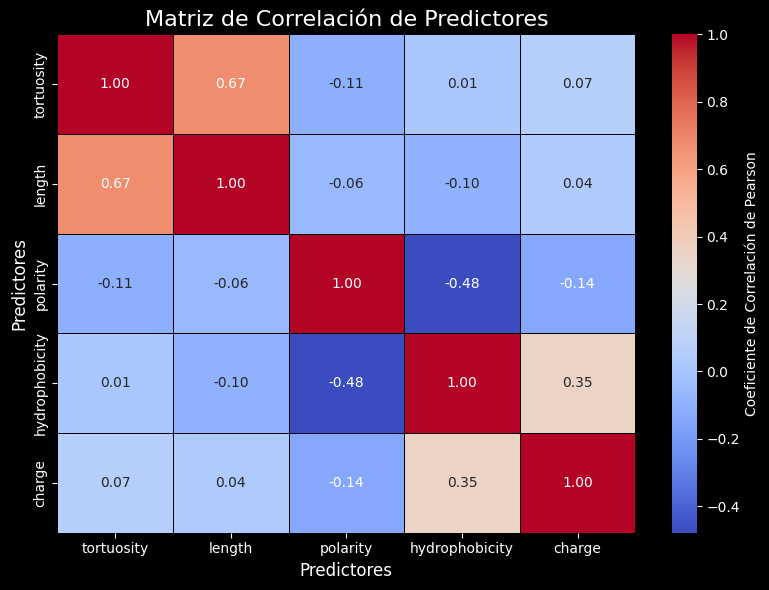


--- Cálculo del Variance Inflation Factor (VIF) ---
         variable       VIF
0           const  1.000000
1      tortuosity  1.859480
2          length  1.880965
3        polarity  1.323462
4  hydrophobicity  1.499674
5          charge  1.151825


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

# Definir una paleta de colores fríos, casi neón
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C', '#FFFF00', '#FF6600', '#00BFFF', '#FFD700']

# Predictores del modelo
predictors = ['tortuosity', 'length', 'polarity', 'hydrophobicity', 'charge']

df_predictors = df_results[predictors]

# --- Matriz de correlación entre predictores ---
print("\n--- Matriz de Correlación entre los Predictores ---")
correlation_matrix_predictors = df_predictors.corr(method='pearson')

# Crear el heatmap
fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('black')

sns.heatmap(correlation_matrix_predictors,
            annot=True, # Mostrar los valores de correlación en el mapa
            cmap='coolwarm', # Elegir un mapa de color que resalte los valores positivos y negativos
            fmt=".2f", # Formatear los números a dos decimales
            linewidths=.5, # Líneas entre celdas para mayor claridad
            linecolor='black') # Color de las líneas

ax.set_title('Matriz de Correlación de Predictores', color='white', fontsize=16)
ax.tick_params(colors='white', which='both')
ax.set_xlabel('Predictores', color='white', fontsize=12)
ax.set_ylabel('Predictores', color='white', fontsize=12)

# Personalizar la barra de color
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.yaxis, 'ticklabels'), color='white')
cbar.set_label('Coeficiente de Correlación de Pearson', color='white')

plt.tight_layout()
plt.show()

# --- Cálculo del VIF ---
print("\n--- Cálculo del Variance Inflation Factor (VIF) ---")

# Es necesario añadir una constante para el cálculo del VIF si el modelo no la incluye implícitamente
# statsmodels.OLS ya añade una constante por defecto, pero para VIF directo de los predictores se puede añadir explícitamente
# o usar un método que no requiera añadirla si se pasa el modelo fitado.

for_vif = df_results[['tortuosity',
                'length',
                'polarity',
                'hydrophobicity',
                'charge']].copy()

for_vif = sm.add_constant(for_vif)

vif_data = pd.DataFrame()
vif_data["variable"] = for_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(for_vif.values, i)
    for i in range(for_vif.shape[1])
]

print(vif_data)

# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')

# Respuesta

1. ¿Existen predictores fuertemente correlacionados?

- Como se venía discutiendo anteriormente : tortuosidad y longitud tienen una correlación fuerte (r_Pearson : 0,67).  También existe una correlación moderada negativa entre polaridad e hidrofobicidad (r_Pearson = -0,48) o entre carga e hidrofobicidad (r_Pearson = 0,35). Sin embargo, ninguna de estas correlaciones alcanza valores que por sí solas indiquen una colinealidad severa.

2. ¿Hay evidencia de multicolinealidad?

- No. Los VIF son todos inferiores a 2, lo que indica una baja redundancia entre los predictores. Esto también respalda el hecho de que la longitud haya dejado de ser significativo en el modelo múltiple no parece explicarse por una multicolinealidad severa, dado que su VIF es solamente ≈ 1,88.

3. ¿Qué consecuencias puede tener para la interpretación de los coeficientes?

- Si hubiera multicolinealidad fuerte, podría producir:
  * Errores estándar más grandes.
  * intervalos de confianza más amplios.
  * coeficientes inestables.
  * pérdida de significancia estadística.
  * dificultad para separar el efecto individual de predictores relacionados.

  Pero estos problemas no parecen ser importantes en el modelo, dado que los VIF son bajos.

4. ¿Eliminarían alguna variable?

- No eliminaría ninguna variable por razones de multicolinealidad. Aunque tortuosidad y longitud tienen r=0,67, sus VIF son bajos. Por lo tanto, no hay evidencia suficiente para eliminar una de ellas por este motivo. Quizás puedan eliminarse alguna por cuestiones biológicas bajo otro criterio.

In [ ]:
# De hecho, usando como criterio para eliminar variables, el p-valor no significativo del modelo anterior:

print("\n--- Modelo de Regresión Lineal Múltiple: bottleneck_radius ~ tortuosity + polarity  ---")
model_multiple_2 = smf.ols('bottleneck_radius ~ tortuosity + polarity', data=df_results).fit()
print(model_multiple_2.summary())


--- Modelo de Regresión Lineal Múltiple: bottleneck_radius ~ tortuosity + polarity  ---
                            OLS Regression Results                            
Dep. Variable:      bottleneck_radius   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.032
Method:                 Least Squares   F-statistic:                     18.31
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.53e-08
Time:                        19:19:42   Log-Likelihood:                 47.026
No. Observations:                1055   AIC:                            -88.05
Df Residuals:                    1052   BIC:                            -73.17
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------

En este caso, se construyo el modelo únicamente con tortuosidad y polaridad y se obtuvo valores correctos significacitvamente, valores de errores estándar bajos. Pero el R2 sigue siendo bajo (0,032).


---

# PARTE VII — DIAGNÓSTICO DEL MODELO

## Actividad 8. ¿Podemos confiar en nuestra regresión?

Analizar los residuos del modelo múltiple.

Realizar al menos:

1. residuos vs valores ajustados;
2. Q-Q plot;
3. distribución de residuos;
4. leverage;
5. Cook's distance.

### Evaluar

* linealidad;
* normalidad de residuos;
* homocedasticidad;
* observaciones influyentes.

### Preguntas

**a.** ¿Se cumplen razonablemente los supuestos del modelo?

**b.** ¿Existen observaciones potencialmente influyentes?

**c.** ¿Eliminarían alguna observación? ¿Por qué?


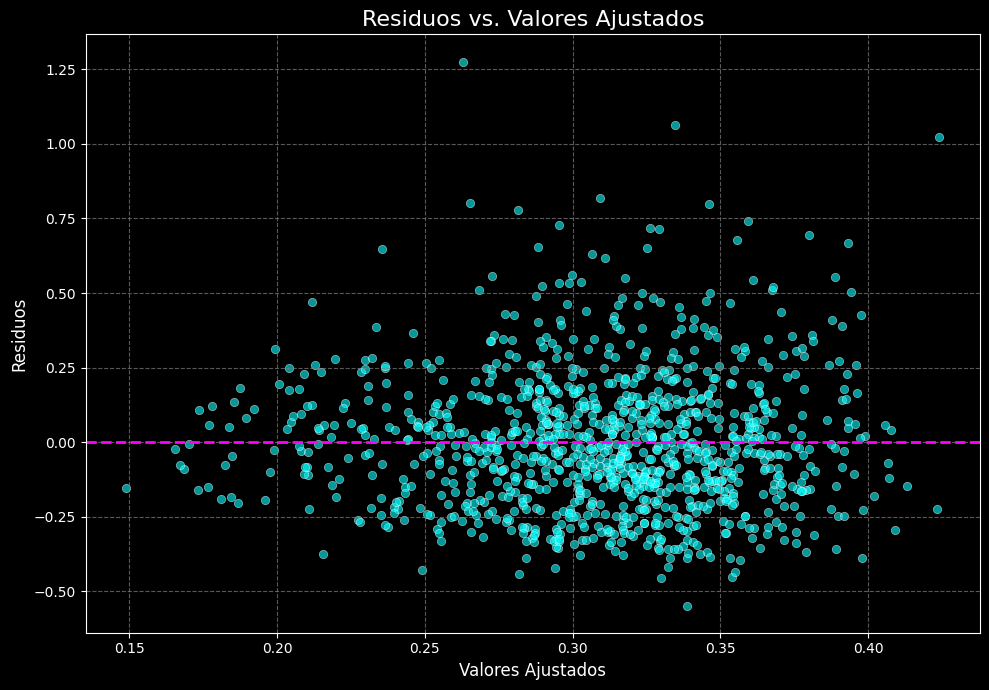

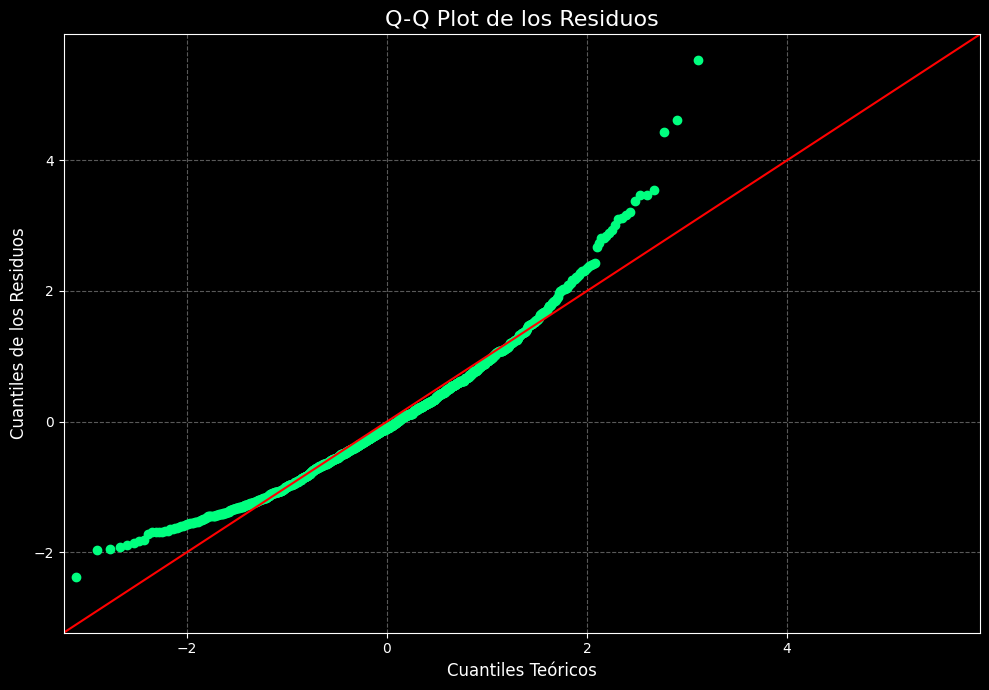

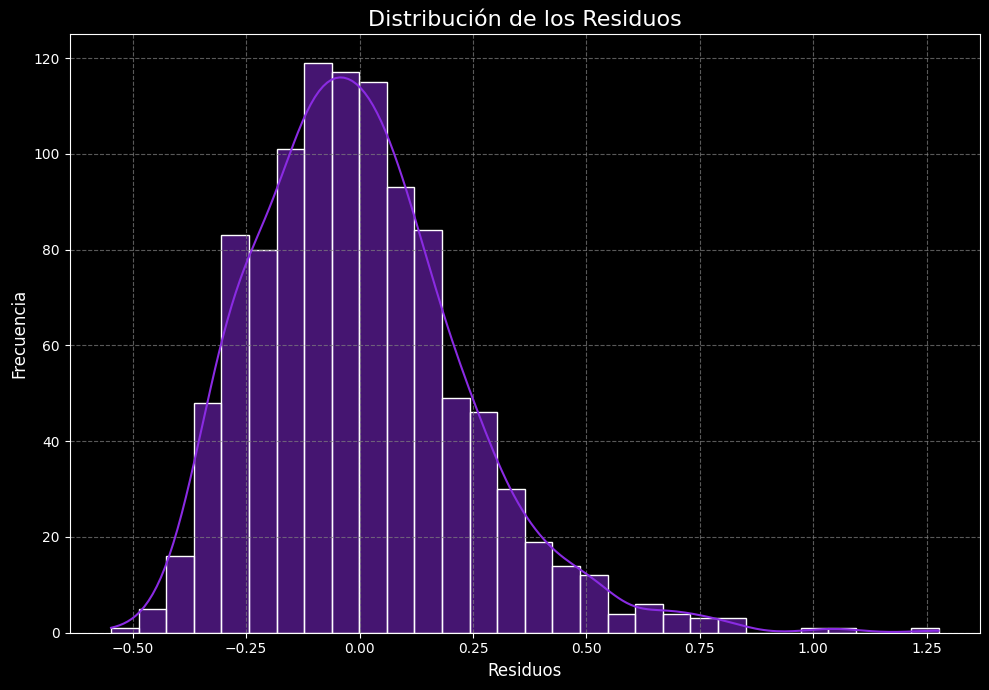

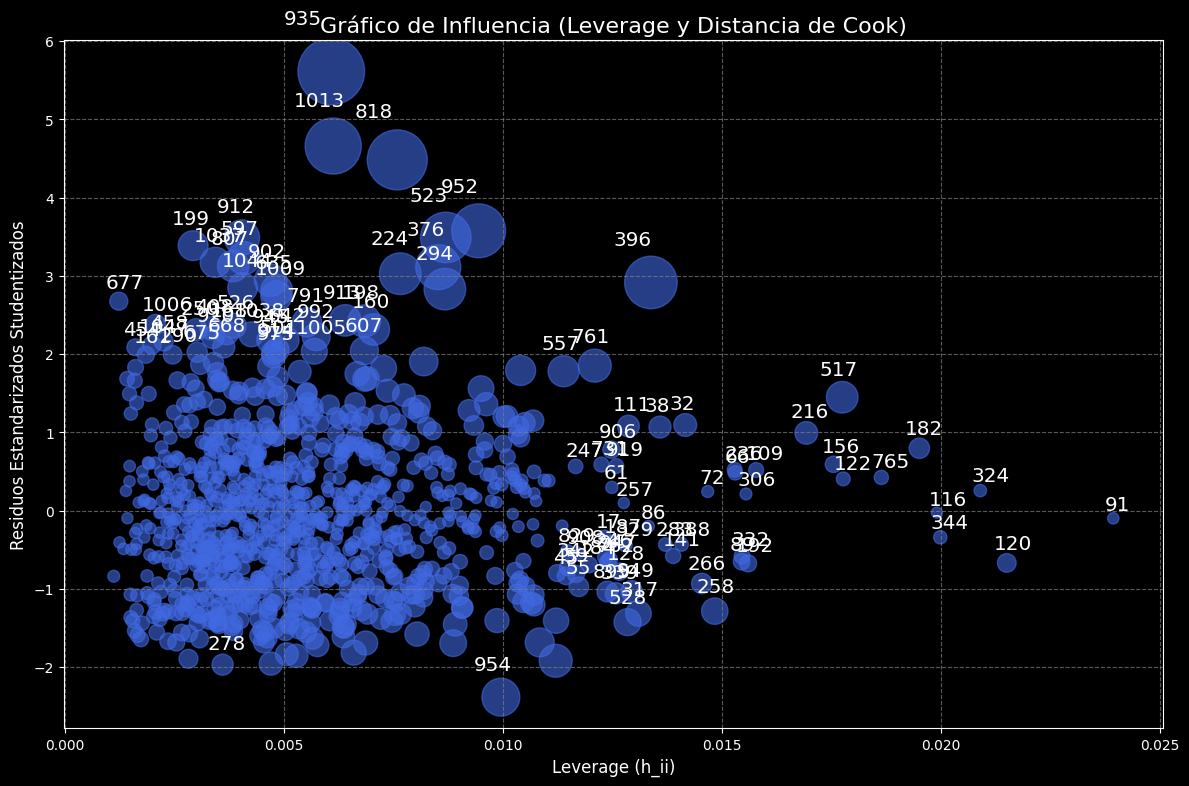

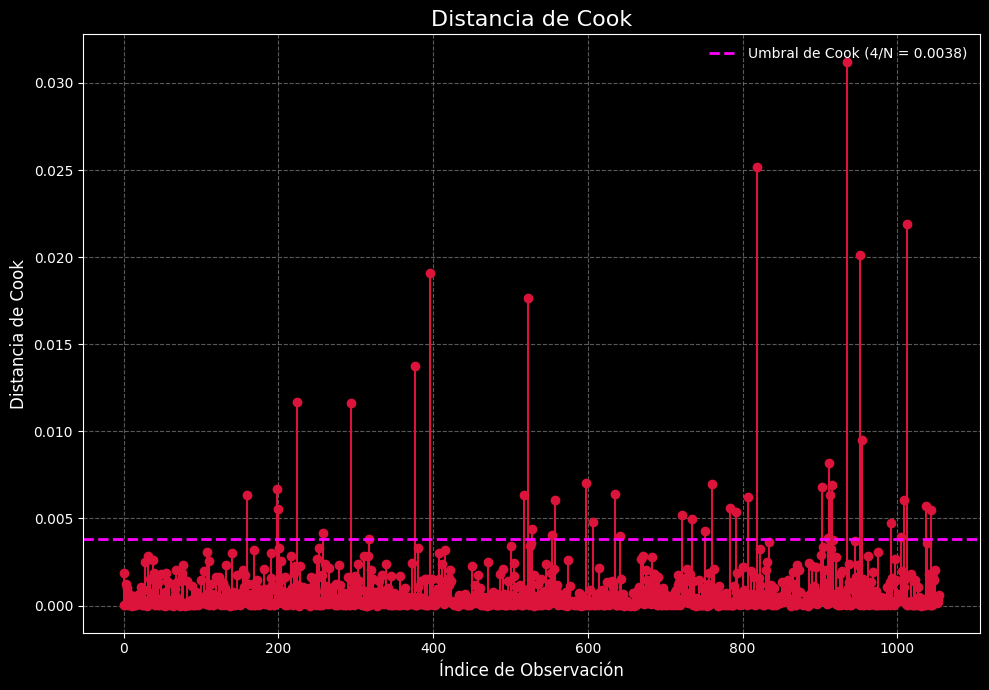

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
import numpy as np

# Establecer el estilo de fondo oscuro
plt.style.use('dark_background')

# Definir una paleta de colores fríos, casi neón
neon_colors = ['#00FFFF', '#FF00FF', '#00FF7F', '#8A2BE2', '#4169E1', '#DC143C', '#FFFF00', '#FF6600', '#00BFFF', '#FFD700']

# Obtener los residuos y los valores ajustados del modelo múltiple
residuals = model_multiple.resid
fitted_values = model_multiple.fittedvalues

# --- 1. Residuos vs Valores Ajustados ---
fig1, ax1 = plt.subplots(figsize=(10, 7))
fig1.patch.set_facecolor('black')

sns.scatterplot(x=fitted_values, y=residuals, ax=ax1, color=neon_colors[0], alpha=0.6)
ax1.axhline(y=0, color=neon_colors[1], linestyle='--', linewidth=2)
ax1.set_title('Residuos vs. Valores Ajustados', color='white', fontsize=16)
ax1.set_xlabel('Valores Ajustados', color='white', fontsize=12)
ax1.set_ylabel('Residuos', color='white', fontsize=12)
ax1.tick_params(colors='white', which='both')
ax1.set_facecolor('black')
ax1.spines['left'].set_color('white')
ax1.spines['bottom'].set_color('white')
ax1.spines['right'].set_color('white')
ax1.spines['top'].set_color('white')
ax1.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- 2. Q-Q Plot (Normalidad de Residuos) ---
fig2, ax2 = plt.subplots(figsize=(10, 7))
fig2.patch.set_facecolor('black')

sm.qqplot(residuals, line='45', ax=ax2, fit=True, markerfacecolor=neon_colors[2], markeredgecolor=neon_colors[2]) # Cambiado 'c' por 'markerfacecolor'
ax2.set_title('Q-Q Plot de los Residuos', color='white', fontsize=16)
ax2.set_xlabel('Cuantiles Teóricos', color='white', fontsize=12)
ax2.set_ylabel('Cuantiles de los Residuos', color='white', fontsize=12)
ax2.tick_params(colors='white', which='both')
ax2.set_facecolor('black')
ax2.spines['left'].set_color('white')
ax2.spines['bottom'].set_color('white')
ax2.spines['right'].set_color('white')
ax2.spines['top'].set_color('white')
ax2.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- 3. Distribución de Residuos (Histograma) ---
fig3, ax3 = plt.subplots(figsize=(10, 7))
fig3.patch.set_facecolor('black')

sns.histplot(residuals, kde=True, ax=ax3, color=neon_colors[3], bins=30, edgecolor='white')
ax3.set_title('Distribución de los Residuos', color='white', fontsize=16)
ax3.set_xlabel('Residuos', color='white', fontsize=12)
ax3.set_ylabel('Frecuencia', color='white', fontsize=12)
ax3.tick_params(colors='white', which='both')
ax3.set_facecolor('black')
ax3.spines['left'].set_color('white')
ax3.spines['bottom'].set_color('white')
ax3.spines['right'].set_color('white')
ax3.spines['top'].set_color('white')
ax3.grid(True, linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()

# --- 4. Leverage y 5. Distancia de Cook ---
# statsmodels.graphics.regressionplots.influence_plot combina leverage y Cook's distance
fig4 = plt.figure(figsize=(12, 8))
fig4.patch.set_facecolor('black')

plot_leverage_resid = sm.graphics.influence_plot(model_multiple, ax=plt.gca(), criterion='cooks')
plot_leverage_resid.set_facecolor('black')

# Personalizar el gráfico generado por statsmodels
ax = plt.gca()
ax.set_title("Gráfico de Influencia (Leverage y Distancia de Cook)", color='white', fontsize=16)
ax.set_xlabel("Leverage (h_ii)", color='white', fontsize=12)
ax.set_ylabel("Residuos Estandarizados Studentizados", color='white', fontsize=12)
ax.tick_params(colors='white', which='both')
ax.set_facecolor('black')
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')
ax.spines['right'].set_color('white')
ax.spines['top'].set_color('white')
ax.grid(True, linestyle='--', alpha=0.7, color='gray')

# Cambiar el color de los puntos en el gráfico de influencia
for collection in ax.collections:
    collection.set_color(neon_colors[4])
    collection.set_alpha(0.6)

plt.tight_layout()
plt.show()

# --- Distancia de Cook por separado (más explícita) ---
cooks_distance = model_multiple.get_influence().cooks_distance[0]
n_obs = len(model_multiple.resid)
threshold = 4 / n_obs # Un umbral común para identificar puntos influyentes

fig5, ax5 = plt.subplots(figsize=(10, 7))
fig5.patch.set_facecolor('black')

ax5.stem(np.arange(n_obs), cooks_distance, basefmt=' ', linefmt=neon_colors[5], markerfmt='o')
ax5.axhline(y=threshold, color=neon_colors[1], linestyle='--', linewidth=2, label=f'Umbral de Cook (4/N = {threshold:.4f})')

ax5.set_title("Distancia de Cook", color='white', fontsize=16)
ax5.set_xlabel("Índice de Observación", color='white', fontsize=12)
ax5.set_ylabel("Distancia de Cook", color='white', fontsize=12)
ax5.tick_params(colors='white', which='both')
ax5.set_facecolor('black')
ax5.spines['left'].set_color('white')
ax5.spines['bottom'].set_color('white')
ax5.spines['right'].set_color('white')
ax5.spines['top'].set_color('white')
ax5.grid(True, linestyle='--', alpha=0.7, color='gray')
ax5.legend(loc='upper right', frameon=False, labelcolor='white')
plt.tight_layout()
plt.show()

# Restablecer el estilo predeterminado de matplotlib
plt.style.use('default')


In [ ]:
# Prueba de Breusch-Pagan de homocedasticidad:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(
    model_multiple.resid,
    model_multiple.model.exog
)

print("Estadístico LM:", bp[0])
print("p-valor:", bp[1])

if (bp[1] < 0.05):
  print("Se rechaza la hipótesis nula de homocedasticidad. Hay heterocedasticidad")
else:
  print("No se rechaza la hipótesis nula de homocedasticidad.")

Estadístico LM: 12.514033024722448
p-valor: 0.028384339216342744
Se rechaza la hipótesis nula de homocedasticidad. Hay heterocedasticidad


**Nota sobre el Leverage:**

Leverage: observaciones con valores atípicos en los predictores

El leverage mide cuánto se aleja una observación del centro de los valores de las variables explicativas.

En tu modelo hay cinco predictores y un intercepto, por lo que p=6
p=6. Una referencia habitual para detectar leverage elevado es:

hii>2p/n=12/n

donde n
n es el número de observaciones.

Un leverage alto no implica necesariamente que la observación sea problemática: también hay que analizar su residuo y su influencia.


In [ ]:
# Obtener leverage de cada observación
influence = model_multiple.get_influence()
leverage = influence.hat_matrix_diag

# Obtener n y p directamente del modelo
n = int(model_multiple.nobs)
p = model_multiple.model.exog.shape[1]  # Incluye el intercepto

# Calcular el umbral de leverage
threshold_leverage = 2 * p / n

# Contar los puntos que superan el umbral
puntos_leverage = np.sum(leverage > threshold_leverage)

# Mostrar resultados
print(f"Número de observaciones (n): {n}")
print(f"Número de parámetros (p): {p}")
print(f"Umbral de leverage (2p/n): {threshold_leverage:.4f}")
print(f"Cantidad de puntos que superan el umbral: {puntos_leverage}")

# Identificar las observaciones
indices_leverage = np.where(leverage > threshold_leverage)[0]

print("Índices de observaciones:", indices_leverage)
print("Numeración desde 1:", indices_leverage + 1)

Número de observaciones (n): 1055
Número de parámetros (p): 6
Umbral de leverage (2p/n): 0.0114
Cantidad de puntos que superan el umbral: 56
Índices de observaciones: [ 17  32  38  45  55  59  61  66  72  86  89  91 109 111 116 120 122 128
 141 156 182 184 187 192 216 236 246 247 257 258 266 283 306 317 324 329
 332 339 342 344 388 396 517 528 557 731 761 762 765 829 895 906 908 919
 947 949]
Numeración desde 1: [ 18  33  39  46  56  60  62  67  73  87  90  92 110 112 117 121 123 129
 142 157 183 185 188 193 217 237 247 248 258 259 267 284 307 318 325 330
 333 340 343 345 389 397 518 529 558 732 762 763 766 830 896 907 909 920
 948 950]


**Nota sobre Distancia de Cook: observaciones influyentes**

La distancia de Cook mide cuánto puede cambiar el ajuste del modelo si se elimina una observación.

Una referencia exploratoria habitual es:
Di>4/n



*   Si ninguna observación supera el umbral, no se detectan puntos que excedan esa referencia.
*   Si algunas lo superan, conviene identificar esas observaciones y revisar sus datos.
*    Un valor alto no significa automáticamente que haya un error: puede ser una observación válida que ejerce una influencia considerable sobre la regresión.

In [ ]:
# Cantidad de puntos que superan el umbral de Cook
puntos_cook = np.sum(cooks_distance > threshold)

print(f"Umbral de Cook (4/n): {threshold:.4f}")
print(f"Cantidad de puntos que superan el umbral: {puntos_cook}")

# Índices de las observaciones que superan el umbral
indices_cook = np.where(cooks_distance > threshold)[0]

print("Observaciones Cook:", indices_cook + 1)

Umbral de Cook (4/n): 0.0038
Cantidad de puntos que superan el umbral: 40
Observaciones Cook: [ 161  199  200  225  259  295  318  377  397  518  524  529  555  558
  598  608  636  643  723  736  752  762  785  792  808  819  903  911
  913  914  917  936  953  955  993 1006 1010 1014 1038 1045]


#Respuestas

Considerando que se utilizó el modelo múltiple:

     b_r = 0,5376 - 0,1267 tor -0,0008 l + 0,0128 polarity + 0,0961 hydrophobicity - 0,0035 charge.
     
se puede analizar los supuestos clave del modelo de regresión lineal. En particular, el error del mismo:

ei​=yi​−y^​i​

yi​: valor observado.

y^​i​: valor predicho por el modelo.

ei​: error o residuo de la observación.

**1. Linealidad:** -> Mediante el **Gráfico de Residuos vs. Valores Ajustados:**, ya que con este gráfico se debería mostrar una dispersión aleatoria de puntos alrededor de la línea horizontal `y=0`, sin patrones discernibles. En el presente caso, se observa una dispersión de los puntos, pero parecen concentrase más en una región de valores ajustados más altos. Esto podría sugerir una muy ligera falta de linealidad perfecta o, más probablemente, un problema de homocedasticidad (o sea, la varianza no es constante).

**2. Normalidad de Residuos:** -> Se puede analizar mediante dos tipos de gráficos los cuales son:

*   **Q-Q Plot de los Residuos:** En este es fácil de leer si hay o no normalidad: para que se cumpla el supuesto de normalidad, los puntos deberían seguir de cerca la línea de 45 grados. En el Q-Q plot realizado, los puntos se desvían de la línea recta en las colas (extremos superior e inferior), indicando una desviación de la normalidad en esas regiones. La distribución parece tener colas más pesadas de lo esperado para una distribución normal.
*   **Histograma de Residuos:** El histograma de los residuos muestra una distribución que parece ser asimétrica y no se asemeja a la forma de campana. Hay una asimetría hacia la derecha (cola más larga a la derecha) y no sigue completamente la curva normal ideal. Esto confirma la observación del Q-Q plot.

**3. Homocedasticidad:** -> Para ello, se realizó un   **Gráfico de Residuos vs. Valores Ajustados:**. El patrón de abanico mencionado anteriormente, donde la dispersión de los residuos aumenta o disminuye a medida que los valores ajustados cambian, o sea, hay **heterocedasticidad**. Esto significa que la varianza de los errores no es constante en todos los niveles de las variables predictoras, lo que puede afectar la eficiencia de las estimaciones de los coeficientes y la validez de los intervalos de confianza y p-values.

**4. Observaciones Influyentes (Outliers y Leverage):** -> Se realizaron **Gráficos de Influencia (Leverage y Distancia de Cook):** Estos gráfico ayuda a identificar observaciones con alto leverage (puntos extremos en el espacio de los predictores) y/o alta influencia (puntos que, si se eliminaran, cambiarían significativamente las estimaciones del modelo).

  *   **Leverage:** Se observan algunos puntos con leverage relativamente alto (más a la derecha en el eje X), lo que indica que estos puntos tienen combinaciones inusuales de valores para los predictores.
  *   **Distancia de Cook:** La distancia de Cook mide el impacto general de eliminar una observación sobre el modelo. Los puntos con una distancia de Cook alta son observaciones influyentes. En el gráfico de distancia de Cook y en el gráfico de influencia, identificamos algunas observaciones que superan o se acercan al umbral común de `4/N` (donde N es el número de observaciones). Estos puntos deberían investigarse más a fondo.


**a. ¿Se cumplen razonablemente los supuestos del modelo?**

En general, no se cumplen razonablemente todos los supuestos. Los supuestos de normalidad de los residuos y el de homocedasticidad no se cumplen. La linealidad parece "aceptable" pero afectada por la heterocedasticidad. Además, de que hay 40 puntos que no cumplen el criterio de Cook y varios con Leverage alto.

**b. ¿Existen observaciones potencialmente influyentes?**

Sí, el gráfico de distancia de Cook y el gráfico de influencia muestran algunos puntos que superan el umbral o que tienen un valor de leverage y/o distancia de Cook considerablemente mayor que la mayoría. Estas observaciones pueden estar ejerciendo una influencia indebida en las estimaciones de los coeficientes del modelo.

**c. ¿Eliminarían alguna observación? ¿Por qué?**

Antes de eliminar cualquier dato, se debe investigar la naturaleza de estas observaciones y esto es bajo los criterios de si son errores de medición o entrada de datos (lo cual no es el caso al ser valores de simulación estructural de un canal iónico) o si representan genuinamente eventos o condiciones biológicas inusuales pero válidas (lo cual si parece ser el caso, reflejando la variabilidad biológica real e importante, y su eliminación daría un sesgo al modelo y limitar su capacidad de generalizar). Podría ser más adecuado utilizar otros métodos de regresión más robustos menos sensibles a los valores atípicos e influyentes o quiźas realizar transformación de variables.

---

# PARTE VIII — PCA

## Actividad 9. Reduciendo la dimensionalidad

Realizar un **Principal Component Analysis (PCA)** utilizando las variables cuantitativas apropiadas.

No incluir:

* `frame`;
* `recipe_id`;
* variables constantes.

Deberán justificar si utilizan o no estandarización.

### Realizar

1. scree plot;
2. porcentaje de varianza explicado;
3. varianza acumulada;
4. gráfico PC1 vs PC2;
5. análisis de loadings.

### Preguntas

**a.** ¿Cuántos componentes conservarían?

**b.** ¿Qué variables contribuyen principalmente a PC1?

**c.** ¿Qué variables contribuyen principalmente a PC2?

**d.** ¿Puede interpretarse alguno de estos componentes como una dimensión principalmente geométrica?

**e.** ¿Puede interpretarse alguno como una dimensión fisicoquímica?

Justificar utilizando los loadings.

### Nota sobre los graficos

1. Scree plot

Muestra cuánta varianza explica cada componente. Buscar el punto donde la curva empieza a aplanarse: puede orientar cuántos componentes conservar.

2. Varianza explicada y acumulada

Te indica qué porcentaje de información conserva cada componente y cuánto acumulan los primeros componentes. El 80 % o el 90 % son referencias orientativas, no reglas obligatorias.

3. Gráfico PC1 vs. PC2

Cada punto representa una observación. Los grupos pueden indicar observaciones con perfiles similares; los puntos alejados del resto pueden tener características diferentes.

4. Loadings

Indican la asociación entre las variables originales y los componentes. Los valores positivos y negativos muestran direcciones opuestas; cuanto mayor sea su valor absoluto, mayor será la asociación.

Variables utilizadas: ['length', 'dz', 'tortuosity', 'bottleneck_radius', 'n_layers', 'charge', 'hydrophobicity', 'polarity', 'logd', 'mutability']
Número de observaciones utilizadas: 1055
Número de variables utilizadas: 10

VARIANZA EXPLICADA
Componente  Varianza explicada (%)  Varianza acumulada (%)
       PC1                   29.85                   29.85
       PC2                   26.53                   56.38
       PC3                   10.86                   67.24
       PC4                    9.81                   77.05
       PC5                    9.06                   86.11
       PC6                    7.74                   93.86
       PC7                    3.96                   97.82
       PC8                    1.90                   99.71
       PC9                    0.27                   99.98
      PC10                    0.02                  100.00


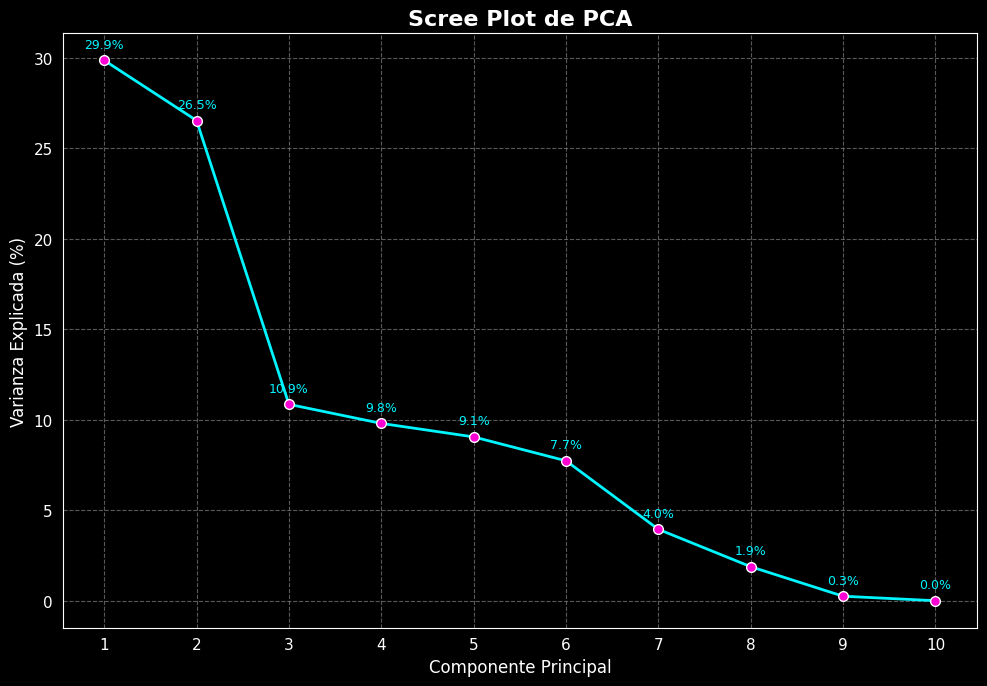

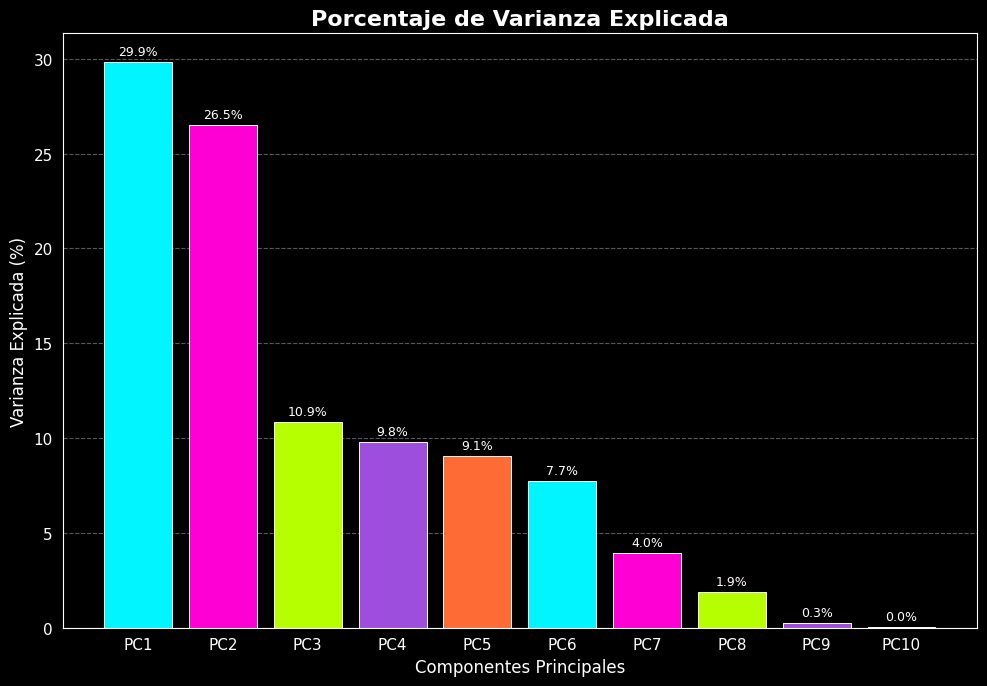

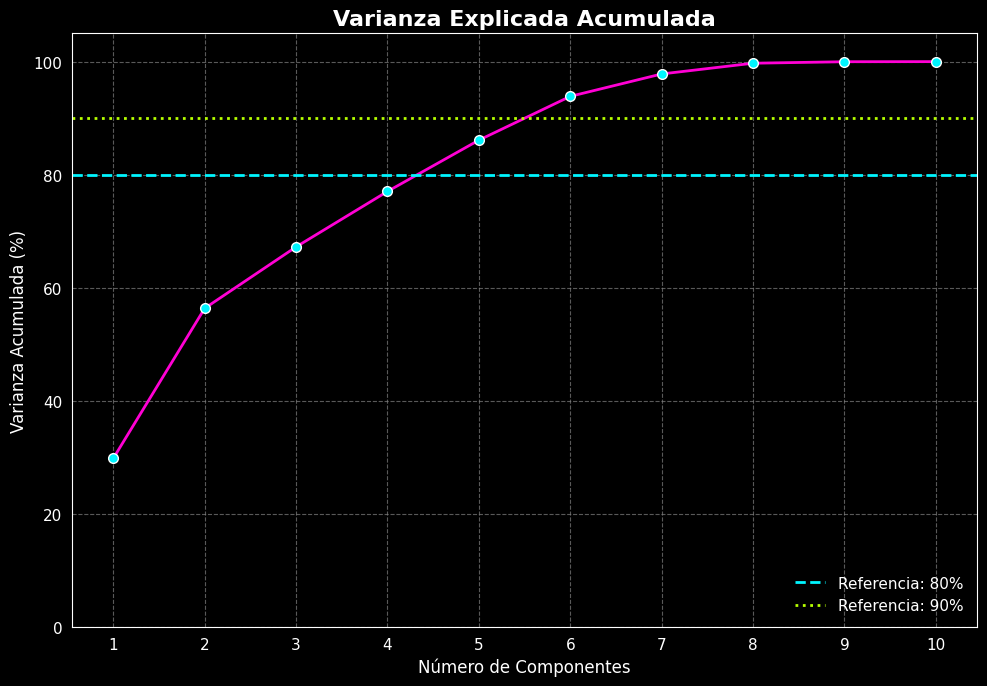

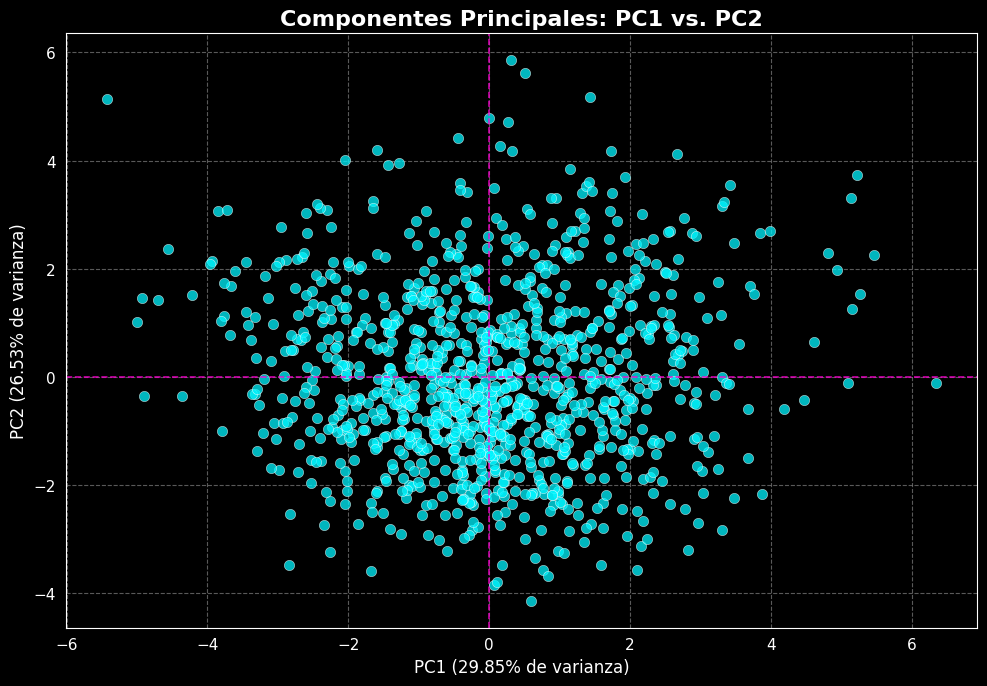


LOADINGS DE LOS COMPONENTES
                     PC1    PC2    PC3    PC4    PC5
length             0.806  0.559 -0.070  0.063 -0.013
dz                 0.679  0.274 -0.089  0.555  0.315
tortuosity         0.467  0.543 -0.006 -0.532 -0.375
bottleneck_radius -0.120 -0.225 -0.572  0.467 -0.529
n_layers           0.818  0.435 -0.017  0.024 -0.093
charge            -0.227  0.390 -0.389 -0.145  0.585
hydrophobicity    -0.605  0.651 -0.092  0.105  0.023
polarity           0.360 -0.671 -0.422 -0.255  0.149
logd              -0.603  0.754  0.140  0.131 -0.108
mutability         0.253 -0.373  0.623  0.233  0.045


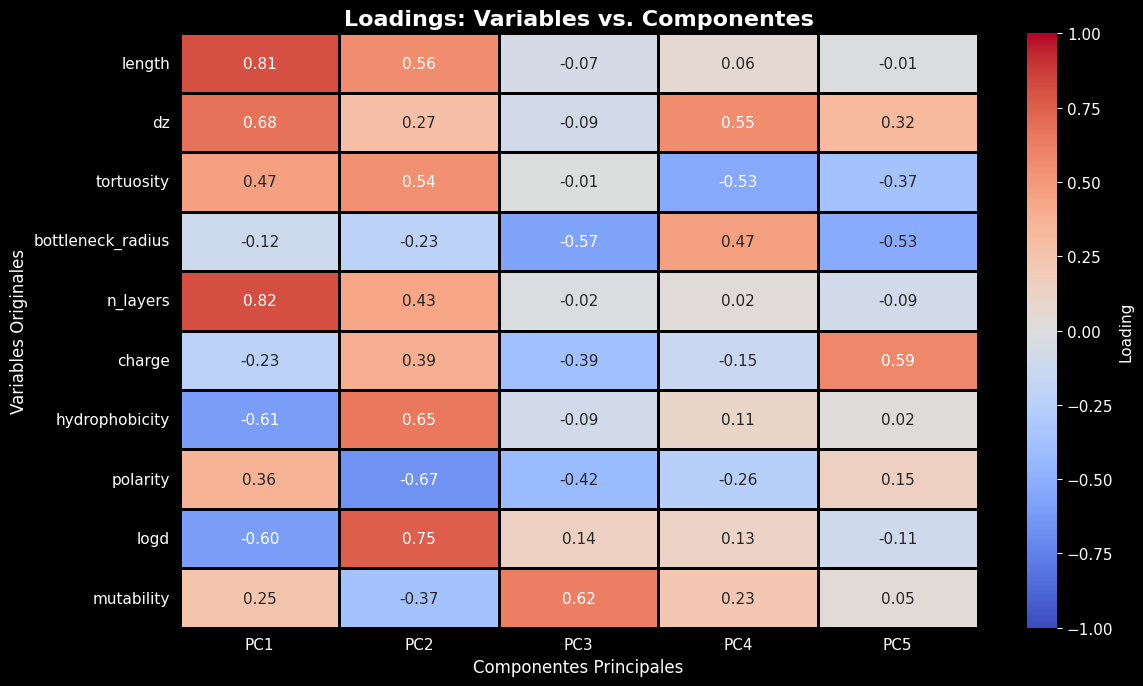


Variables más asociadas a PC1:
n_layers             0.818
length               0.806
dz                   0.679
hydrophobicity      -0.605
logd                -0.603
tortuosity           0.467
polarity             0.360
mutability           0.253
charge              -0.227
bottleneck_radius   -0.120

Variables más asociadas a PC2:
logd                 0.754
polarity            -0.671
hydrophobicity       0.651
length               0.559
tortuosity           0.543
n_layers             0.435
charge               0.390
mutability          -0.373
dz                   0.274
bottleneck_radius   -0.225


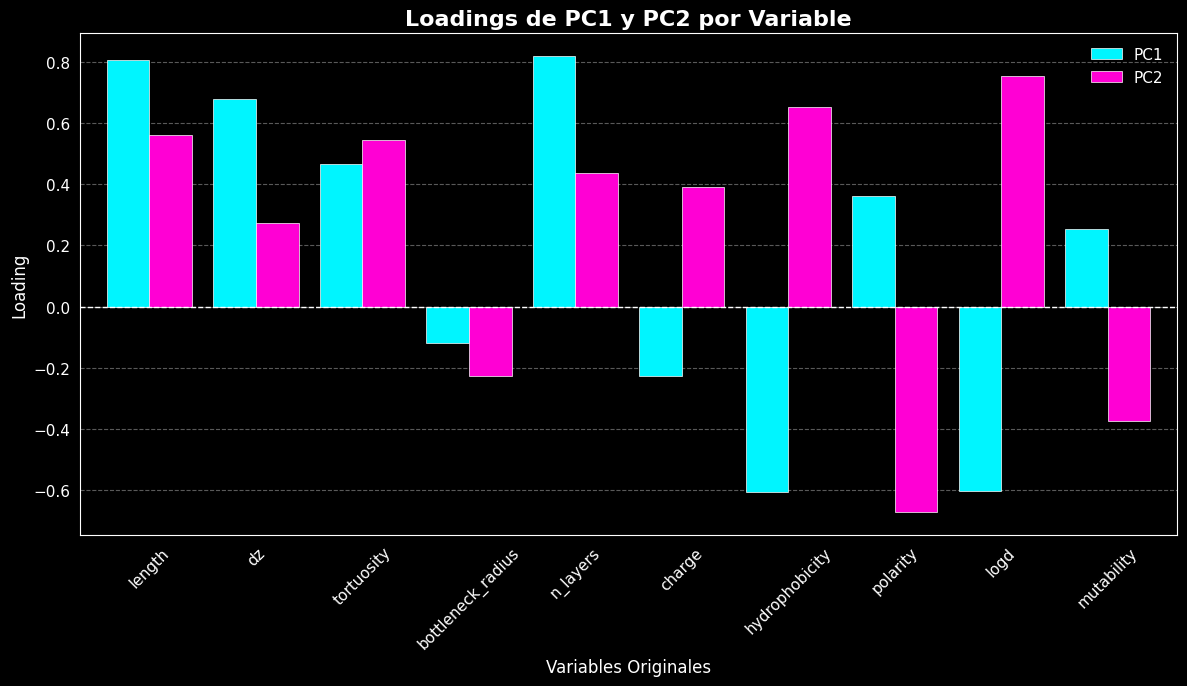


RESUMEN PCA
Componente  Varianza explicada (%)  Varianza acumulada (%)
       PC1                   29.85                   29.85
       PC2                   26.53                   56.38
       PC3                   10.86                   67.24
       PC4                    9.81                   77.05
       PC5                    9.06                   86.11
       PC6                    7.74                   93.86
       PC7                    3.96                   97.82
       PC8                    1.90                   99.71
       PC9                    0.27                   99.98
      PC10                    0.02                  100.00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})

# ============================================================
# 1. SELECCIÓN DE VARIABLES
# ============================================================

# Excluir 'frame', 'recipe_id' y variables constantes o altamente redundantes.
# 'recipe_id' es constante (todas las entradas son 0).
# 'bottleneck_bradius' es idéntico a 'bottleneck_radius'.
# 'bottleneck_free_radius' está altamente correlacionado con 'bottleneck_radius' (0.77).
# 'ionizable', 'num_positives', 'num_negatives' son componentes de 'charge'.
# Para un PCA más conciso y evitar sobre-representación de propiedades muy similares,
# se seleccionan las siguientes variables:

pca_vars = [
    "length",
    "dz",
    "tortuosity",
    "bottleneck_radius",
    "n_layers",
    "charge",
    "hydrophobicity",
    "polarity",
    "logd",
    "mutability"
]

# Seleccionar variables cuantitativas
X_original = df_results[pca_vars].copy()

# Convertir a formato numérico por seguridad
X_original = X_original.apply(pd.to_numeric, errors="coerce")

# Eliminar filas con valores faltantes o infinitos
X_original = X_original.replace([np.inf, -np.inf], np.nan)
X_original = X_original.dropna()

# Eliminar variables constantes, si existieran
variances = X_original.var()
constant_vars = variances[variances == 0].index.tolist()

if constant_vars:
    print("Variables constantes eliminadas:", constant_vars)
    X_original = X_original.drop(columns=constant_vars)

print("Variables utilizadas:", X_original.columns.tolist())
print("Número de observaciones utilizadas:", len(X_original))
print("Número de variables utilizadas:", X_original.shape[1])

# ============================================================
# 2. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_original)

# ============================================================
# 3. PCA
# ============================================================

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

n_components = X_pca.shape[1]
pc_names = [f"PC{i+1}" for i in range(n_components)]

# Varianza explicada y acumulada
explained = pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)

variance_table = pd.DataFrame({
    "Componente": pc_names,
    "Varianza explicada (%)": explained,
    "Varianza acumulada (%)": cumulative
})

print("\nVARIANZA EXPLICADA")
print(variance_table.round(2).to_string(index=False))

# ============================================================
# 4. SCREE PLOT
# ============================================================

fig4, ax4 = plt.subplots(figsize=(10, 7))
fig4.patch.set_facecolor("black")

ax4.plot(
    range(1, n_components + 1),
    explained,
    color=neon_colors[0],
    marker="o",
    markersize=7,
    linewidth=2,
    markerfacecolor=neon_colors[1],
    markeredgecolor="white"
)

ax4.set_title("Scree Plot de PCA", color="white", fontsize=16)
ax4.set_xlabel("Componente Principal", color="white", fontsize=12)
ax4.set_ylabel("Varianza Explicada (%)", color="white", fontsize=12)
ax4.set_xticks(range(1, n_components + 1))
ax4.tick_params(colors="white", which="both")
ax4.set_facecolor("black")

for spine in ax4.spines.values():
    spine.set_color("white")

ax4.grid(True, linestyle="--", alpha=0.7, color="gray")

for i, value in enumerate(explained):
    ax4.annotate(
        f"{value:.1f}%",
        (i + 1, value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        color=neon_colors[0],
        fontsize=9
    )

plt.tight_layout()
plt.show()


# ============================================================
# 5. VARIANZA EXPLICADA POR COMPONENTE
# ============================================================

fig5, ax5 = plt.subplots(figsize=(10, 7))
fig5.patch.set_facecolor("black")

bars = ax5.bar(
    pc_names,
    explained,
    color=[
        neon_colors[i % len(neon_colors)]
        for i in range(n_components)
    ],
    edgecolor="white",
    linewidth=0.7
)

ax5.set_title(
    "Porcentaje de Varianza Explicada",
    color="white", fontsize=16
)
ax5.set_xlabel("Componentes Principales", color="white", fontsize=12)
ax5.set_ylabel("Varianza Explicada (%)", color="white", fontsize=12)
ax5.tick_params(colors="white", which="both")
ax5.set_facecolor("black")

for spine in ax5.spines.values():
    spine.set_color("white")

ax5.grid(True, axis="y", linestyle="--", alpha=0.7, color="gray")
ax5.set_axisbelow(True)

for bar, value in zip(bars, explained):
    ax5.annotate(
        f"{value:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        color="white",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# ============================================================
# 6. VARIANZA ACUMULADA
# ============================================================

fig6, ax6 = plt.subplots(figsize=(10, 7))
fig6.patch.set_facecolor("black")

ax6.plot(
    range(1, n_components + 1),
    cumulative,
    color=neon_colors[1],
    marker="o",
    markersize=7,
    linewidth=2,
    markerfacecolor=neon_colors[0],
    markeredgecolor="white"
)

ax6.axhline(
    y=80,
    color=neon_colors[0],
    linestyle="--",
    linewidth=2,
    label="Referencia: 80%"
)

ax6.axhline(
    y=90,
    color=neon_colors[2],
    linestyle=":",
    linewidth=2,
    label="Referencia: 90%"
)

ax6.set_title(
    "Varianza Explicada Acumulada",
    color="white", fontsize=16
)
ax6.set_xlabel("Número de Componentes", color="white", fontsize=12)
ax6.set_ylabel("Varianza Acumulada (%)", color="white", fontsize=12)
ax6.set_xticks(range(1, n_components + 1))
ax6.set_ylim(0, 105)
ax6.tick_params(colors="white", which="both")
ax6.set_facecolor("black")

for spine in ax6.spines.values():
    spine.set_color("white")

ax6.grid(True, linestyle="--", alpha=0.7, color="gray")
ax6.legend(loc="lower right", frameon=False, labelcolor="white")

plt.tight_layout()
plt.show()


# ============================================================
# 7. GRÁFICO PC1 VS PC2
# ============================================================

scores = pd.DataFrame(
    X_pca[:, :2],
    columns=["PC1", "PC2"],
    index=X_original.index
)

fig7, ax7 = plt.subplots(figsize=(10, 7))
fig7.patch.set_facecolor("black")

sns.scatterplot(
    x=scores["PC1"],
    y=scores["PC2"],
    ax=ax7,
    color=neon_colors[0],
    edgecolor="white",
    linewidth=0.4,
    alpha=0.75,
    s=55
)

ax7.axhline(
    y=0, color=neon_colors[1],
    linestyle="--", linewidth=1.2, alpha=0.8
)

ax7.axvline(
    x=0, color=neon_colors[1],
    linestyle="--", linewidth=1.2, alpha=0.8
)

ax7.set_title(
    "Componentes Principales: PC1 vs. PC2",
    color="white", fontsize=16
)
ax7.set_xlabel(
    f"PC1 ({explained[0]:.2f}% de varianza)",
    color="white", fontsize=12
)
ax7.set_ylabel(
    f"PC2 ({explained[1]:.2f}% de varianza)",
    color="white", fontsize=12
)
ax7.tick_params(colors="white", which="both")
ax7.set_facecolor("black")

for spine in ax7.spines.values():
    spine.set_color("white")

ax7.grid(True, linestyle="--", alpha=0.7, color="gray")

plt.tight_layout()
plt.show()


# ============================================================
# 8. LOADINGS
# ============================================================

# Loadings como correlaciones entre las variables
# estandarizadas y los componentes principales

loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=X_original.columns,
    columns=pc_names
)

print("\nLOADINGS DE LOS COMPONENTES")
print(loadings.iloc[:, :min(5, n_components)].round(3))

# --- Heatmap de loadings ---

n_show = min(5, n_components)

fig8, ax8 = plt.subplots(figsize=(12, 7))
fig8.patch.set_facecolor("black")

heatmap = sns.heatmap(
    loadings.iloc[:, :n_show],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.8,
    linecolor="black",
    cbar_kws={"label": "Loading"},
    ax=ax8
)

ax8.set_title(
    "Loadings: Variables vs. Componentes",
    color="white", fontsize=16
)
ax8.set_xlabel("Componentes Principales", color="white", fontsize=12)
ax8.set_ylabel("Variables Originales", color="white", fontsize=12)
ax8.tick_params(colors="white", which="both")
ax8.set_facecolor("black")

# Personalizar la barra de color
cbar = heatmap.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color="white")
cbar.set_label("Loading", color="white")
plt.setp(cbar.ax.get_yticklabels(), color="white")

plt.tight_layout()
plt.show()


# ============================================================
# 9. VARIABLES MÁS ASOCIADAS A PC1 Y PC2
# ============================================================

for pc in ["PC1", "PC2"]:
    print(f"\nVariables más asociadas a {pc}:")

    ranked = loadings[pc].reindex(
        loadings[pc].abs().sort_values(ascending=False).index
    )

    print(ranked.round(3).to_string())

# --- Gráfico comparativo de loadings PC1 y PC2 ---

fig9, ax9 = plt.subplots(figsize=(12, 7))
fig9.patch.set_facecolor("black")

loadings_pc12 = loadings[["PC1", "PC2"]]

loadings_pc12.plot(
    kind="bar",
    ax=ax9,
    color=[neon_colors[0], neon_colors[1]],
    edgecolor="white",
    linewidth=0.5,
    width=0.8
)

ax9.axhline(
    y=0, color="white",
    linestyle="--", linewidth=1
)

ax9.set_title(
    "Loadings de PC1 y PC2 por Variable",
    color="white", fontsize=16
)
ax9.set_xlabel("Variables Originales", color="white", fontsize=12)
ax9.set_ylabel("Loading", color="white", fontsize=12)
ax9.tick_params(colors="white", which="both")
ax9.tick_params(axis="x", rotation=45)
ax9.set_facecolor("black")

for spine in ax9.spines.values():
    spine.set_color("white")

ax9.grid(True, axis="y", linestyle="--", alpha=0.7, color="gray")
ax9.set_axisbelow(True)
ax9.legend(frameon=False, labelcolor="white")

plt.tight_layout()
plt.show()

# ============================================================
# TABLA FINAL DE VARIANZA
# ============================================================

print("\nRESUMEN PCA")
print(variance_table.round(2).to_string(index=False))

# Restablecer el estilo predeterminado
plt.style.use("default")


## Respuesta

**a. ¿Cuántos componentes conservarían?**

  Analizando el gráfico de scree plot se podría conservar hasta 6 o 7 componentes basado en la varianza de estos (el septimo tiene 4% de varianza).  Entre la componente 3 a 6 no es mucha diferencia (10,9% a 7,7%). Un análisis de la varianza acumulada, con la PC5 se acumula entre el 80 al 90 % de la varianza total del sistema: asi que para reducir dimensionalidad se podría elegir hasta 5 componentes principales.

**b. ¿Qué variables contribuyen principalmente a PC1?**

  Para PC1 contribuyen n_layers, longitud, dz, hidrofobicidad, logD, tortuosidad, polaridad, mutabilidad, carga, y radio_cuello_botella.

**c. ¿Qué variables contribuyen principalmente a PC2?**

  Para PC2 contribuyen logD, polaridad, hidrofobicidad, longitud, tortuosidad,
  n_layers, carga, mutabilidad y dz.

**d. ¿Puede interpretarse alguno de estos componentes como una dimensión principalmente geométrica?**

  A priori tanto PC1 como PC2 tienen loadings de longitud, dz, tortuosidad y bottleneck_radius. Asi que no hay unico PC que pueda interpretarse como una dimensión geométrica.

**e. ¿Puede interpretarse alguno como una dimensión fisicoquímica?**

  PC2 acumula más loadings de carga, hidrofobicidad, polaridd y logD, así que la PC2 puede interpretarse como una dimensión fisicoquímica.


---

# PARTE IX — CLUSTERING

## Actividad 10. ¿Existen diferentes estados del túnel?

Utilizar las variables seleccionadas para realizar clustering.

Aplicar al menos uno de los siguientes métodos:

* k-means;
* clustering jerárquico.

Si es posible, comparar ambos.

### Determinación del número de clusters

No elegir arbitrariamente el número de grupos.

Utilizar alguna estrategia estadística, por ejemplo:

* silhouette;
* elbow method;
* dendrograma.

### Preguntas

1. ¿Cuántos clusters parecen razonables?
2. ¿Los clusters están claramente separados?
3. ¿Qué características diferencian los grupos?
4. ¿Los clusters pueden interpretarse como diferentes estados estructurales?

### Importante

**No es obligatorio encontrar estados discretos.**

Si los datos sugieren una variación continua, esa también es una conclusión válida.


### Consideraciones

1. Método del codo (Elbow)

  La inercia siempre disminuye al aumentar el número de clusters. Busca un cambio claro en la pendiente de la curva: ese punto indica que crear más grupos aporta mejoras progresivamente menores.

2. Coeficiente silhouette

Mide si las observaciones están más cerca de su propio cluster que de los demás. Sus valores oscilan entre −1 y 1.

* Cerca de 1: grupos bien separados.

* Cerca de 0: grupos solapados.

* Negativo: algunas observaciones podrían estar asignadas a un grupo inadecuado.


3. Dendrograma

  Representa las fusiones sucesivas entre observaciones y grupos. Las uniones a mayor altura indican que se están fusionando grupos más diferentes.

  Se puede explorar un corte horizontal antes de un salto importante en la distancia de fusión y comprobar cuántos grupos genera.


El Adjusted Rand Index (ARI) del código mide el acuerdo entre ambas particiones sin depender de los números asignados a las etiquetas. Un ARI cercano a 1 indica gran concordancia; un valor cercano a 0 indica un acuerdo similar al esperado por azar.

K-Means : Optimiza la asignación a centroides. El numero de clusters se especifica antes, la forma de los grupos favorece a los compactos alrededor del centroide, y su resultado es una partición para cada k . La comparación es Silhouette e inercia.

Jerárquico (Ward): Fusiona grupos minimizando el incremento de varianza intragrupo. Los clusters se pueden explorar mediante el dendrograma. La forma de estos grupos favorece a aquellos que sean compactos con Ward. Y el resultado es una jerarquía de fusiones. La comparación es Silhouette y dendrograma.

### Ver si hay estados de tune

- No basta con observar las diferencia en el PCA, habría que ver
* Separación de los clusters : Muestren un silhouette razonable y sin solapamiento excesivo.
* Consistencia : k-means o jerárquico identifican estructuras similares o la diferencia puede explicarse.
* Interpretabilidad: Los grupos difieren en propiedades con sentido biológico o fisicoquímico.
* Tamaño de ls grupos :  No se obtiene grupos minúsculos sin justificación física.
* Robustez : Los resultados no dependen excesivamente de una pocas observaciones o de una elección concreta de parámetros.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})

# ============================================================
# 1. SELECCIÓN DE VARIABLES
# ============================================================

cluster_vars = [
    "length",
    "dz",
    "tortuosity",
    "bottleneck_radius",
    "n_layers",
    "charge",
    "hydrophobicity",
    "polarity",
    "logd",
    "mutability"
]

X_original = df_results[cluster_vars].copy()

X_original = X_original.apply(
    pd.to_numeric, errors="coerce"
)

X_original = X_original.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Eliminar variables constantes
constant_vars = X_original.columns[
    X_original.nunique() <= 1
].tolist()

if constant_vars:
    print("Variables constantes eliminadas:", constant_vars)
    X_original = X_original.drop(columns=constant_vars)

if len(X_original) < 4 or X_original.shape[1] < 2:
    raise ValueError(
        "Se necesitan al menos 4 observaciones y "
        "2 variables no constantes."
    )

print("Variables utilizadas:", X_original.columns.tolist())
print("Número de observaciones:", len(X_original))
print("Número de variables:", X_original.shape[1])
print(
    "Observaciones excluidas:",
    len(df_results) - len(X_original)
)

# ============================================================
# 2. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_original)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X_original.columns,
    index=X_original.index
)

# ============================================================
# 3. PCA PARA VISUALIZACIÓN
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

scores = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=X_original.index
)

explained = pca.explained_variance_ratio_ * 100

print("\nVARIANZA EXPLICADA POR PCA")
print(f"PC1: {explained[0]:.2f}%")
print(f"PC2: {explained[1]:.2f}%")
print(f"Acumulada: {explained.sum():.2f}%")

# Paleta para los clusters
cluster_palette = {
    0: CYAN,
    1: MAGENTA,
    2: LIME
}

Variables utilizadas: ['length', 'dz', 'tortuosity', 'bottleneck_radius', 'n_layers', 'charge', 'hydrophobicity', 'polarity', 'logd', 'mutability']
Número de observaciones: 1055
Número de variables: 10
Observaciones excluidas: 0

VARIANZA EXPLICADA POR PCA
PC1: 29.85%
PC2: 26.53%
Acumulada: 56.38%



MÉTRICAS K-MEANS
 k   Inercia  Silhouette
 2 8566.7494      0.1779
 3 7210.3713      0.1700
 4 6622.5326      0.1433
 5 6264.1765      0.1285
 6 5939.2323      0.1266


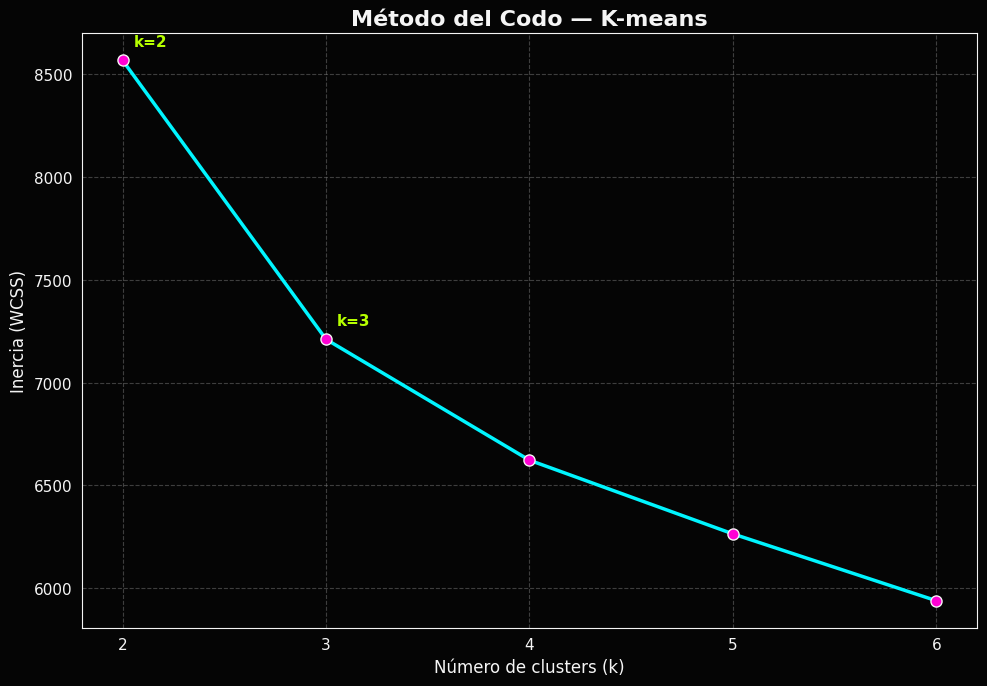

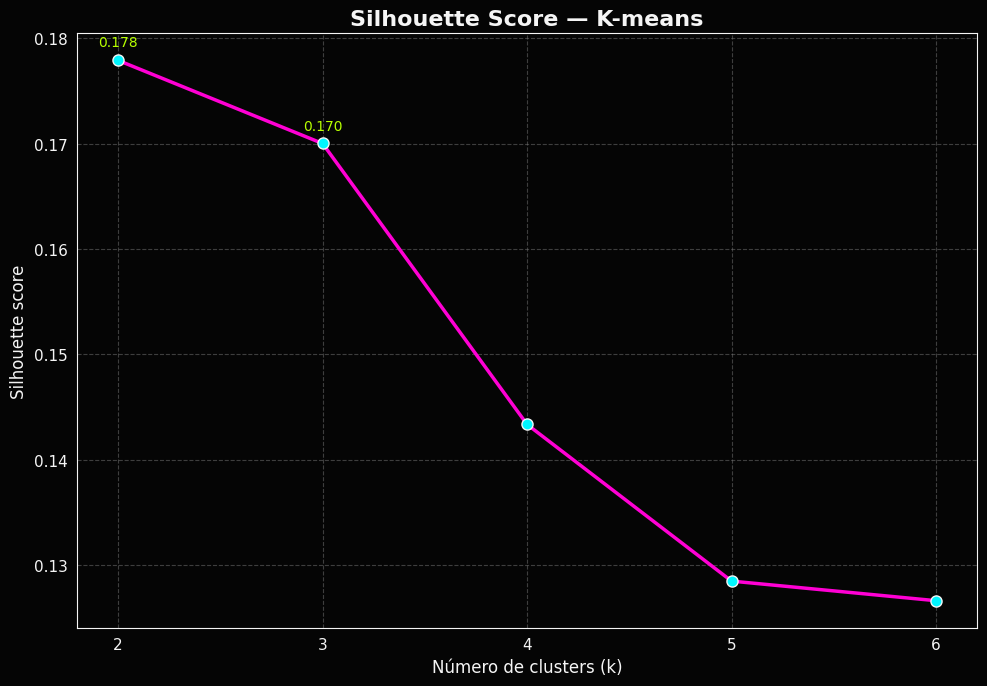

In [ ]:
# ============================================================
# 4. K-MEANS: ELBOW Y SILHOUETTE
# ============================================================

k_values_kmeans = list(range(2, min(7, len(X_scaled))))

inertias_kmeans = []
silhouettes_kmeans = []

for k in k_values_kmeans:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertias_kmeans.append(model.inertia_)

    silhouettes_kmeans.append(
        silhouette_score(X_scaled, labels)
    )

metrics_kmeans = pd.DataFrame({
    "k": k_values_kmeans,
    "Inercia": inertias_kmeans,
    "Silhouette": silhouettes_kmeans
})

print("\nMÉTRICAS K-MEANS")
print(metrics_kmeans.round(4).to_string(index=False))

# ============================================================
# 5. MÉTODO DEL CODO
# ============================================================

fig1, ax1 = plt.subplots(figsize=(10, 7))
fig1.patch.set_facecolor(BLACK)

ax1.plot(
    k_values_kmeans,
    inertias_kmeans,
    color=CYAN,
    marker="o",
    markersize=8,
    linewidth=2.5,
    markerfacecolor=MAGENTA,
    markeredgecolor=WHITE
)

# Destacar k = 2 y k = 3
for k in [2, 3]:
    idx = k_values_kmeans.index(k)

    ax1.annotate(
        f"k={k}",
        (k, inertias_kmeans[idx]),
        xytext=(8, 10),
        textcoords="offset points",
        color=LIME,
        fontsize=11,
        fontweight="bold"
    )

ax1.set_title(
    "Método del Codo — K-means",
    color=WHITE,
    fontsize=16
)
ax1.set_xlabel("Número de clusters (k)", fontsize=12)
ax1.set_ylabel("Inercia (WCSS)", fontsize=12)
ax1.set_xticks(k_values_kmeans)
ax1.grid(True, linestyle="--", alpha=0.5)

for spine in ax1.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 6. SILHOUETTE SCORE
# ============================================================

fig2, ax2 = plt.subplots(figsize=(10, 7))
fig2.patch.set_facecolor(BLACK)

ax2.plot(
    k_values_kmeans,
    silhouettes_kmeans,
    color=MAGENTA,
    marker="o",
    markersize=8,
    linewidth=2.5,
    markerfacecolor=CYAN,
    markeredgecolor=WHITE
)

ax2.set_title(
    "Silhouette Score — K-means",
    color=WHITE,
    fontsize=16
)
ax2.set_xlabel("Número de clusters (k)", fontsize=12)
ax2.set_ylabel("Silhouette score", fontsize=12)
ax2.set_xticks(k_values_kmeans)
ax2.grid(True, linestyle="--", alpha=0.5)

for k in [2, 3]:
    idx = k_values_kmeans.index(k)

    ax2.annotate(
        f"{silhouettes_kmeans[idx]:.3f}",
        (k, silhouettes_kmeans[idx]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color=LIME,
        fontsize=10
    )

for spine in ax2.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()


K-MEANS CON k = 2
Inercia: 8566.7494
Silhouette: 0.1779
0    428
1    627

K-MEANS CON k = 3
Inercia: 7210.3713
Silhouette: 0.1700
0    336
1    453
2    266


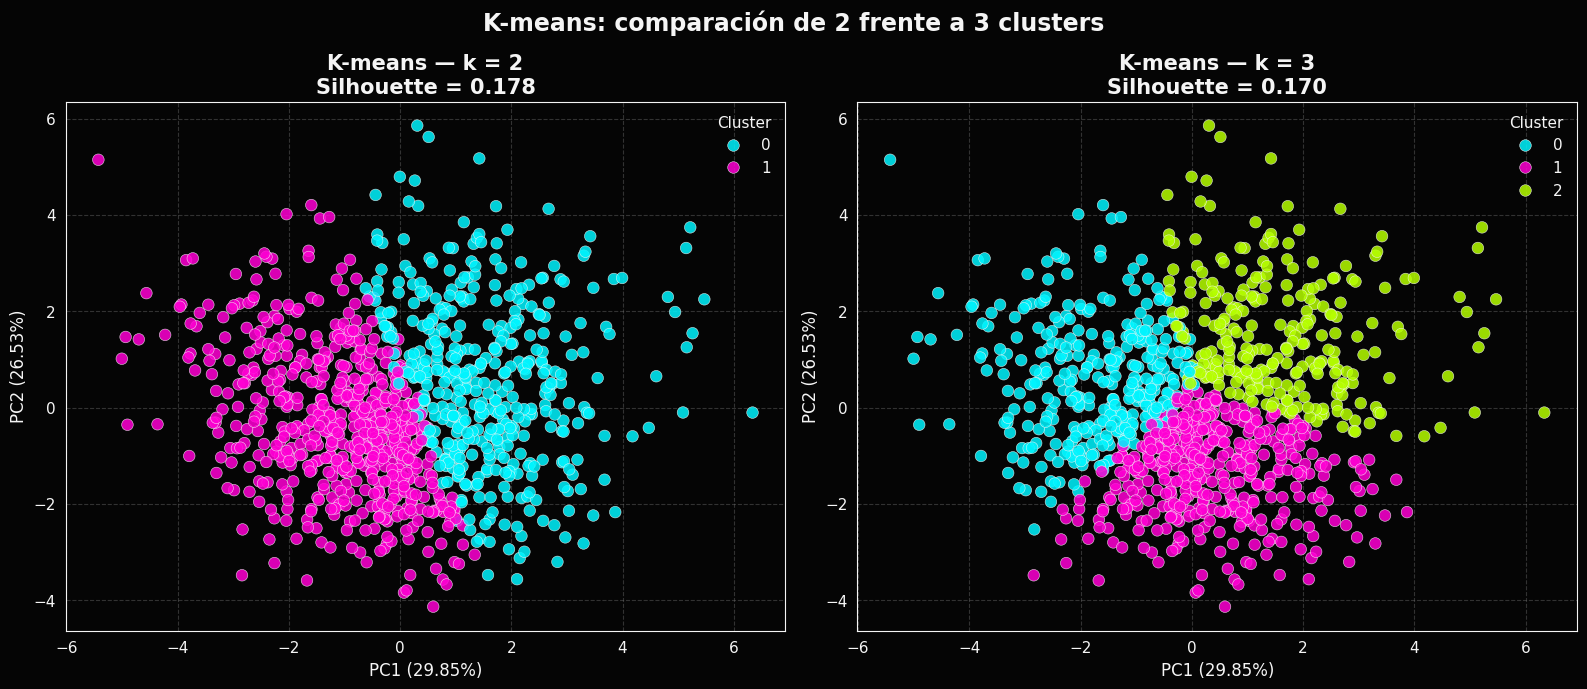


PERFIL MEDIO K-MEANS — k = 2
          length      dz  tortuosity  bottleneck_radius  n_layers  charge  hydrophobicity  polarity   logd  mutability
Cluster                                                                                                               
0        170.927  82.850       2.066              0.272   146.944  -1.042           0.032    11.055  0.281      78.783
1        140.296  73.462       1.914              0.335   119.191  -0.241           0.108    10.865  0.378      78.394


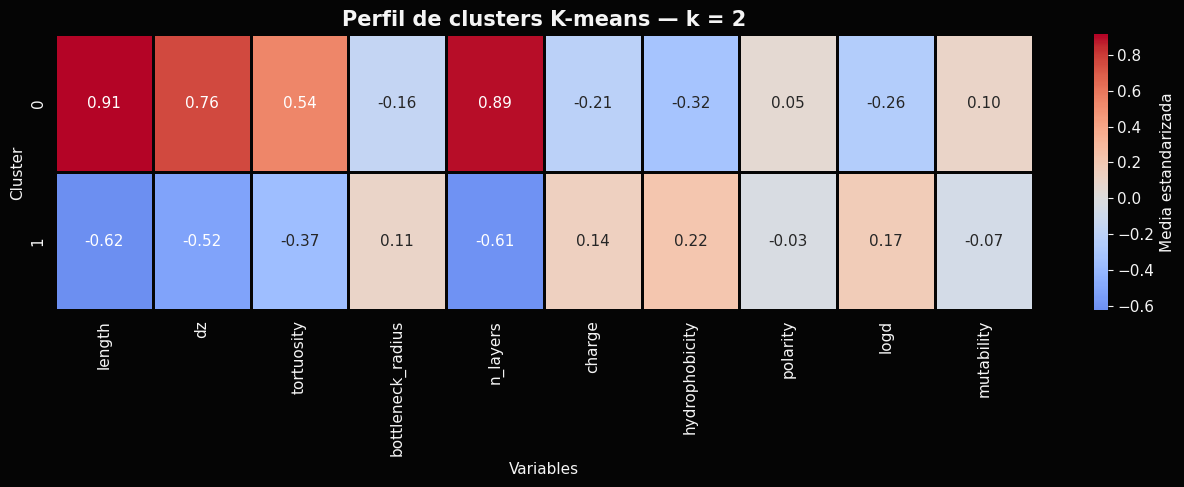


PERFIL MEDIO K-MEANS — k = 3
          length      dz  tortuosity  bottleneck_radius  n_layers  charge  hydrophobicity  polarity   logd  mutability
Cluster                                                                                                               
0        140.343  72.171       1.948              0.292   118.268   0.161           0.197     9.525  0.540      77.833
1        146.796  76.922       1.912              0.348   126.775  -1.243          -0.015    12.465  0.168      79.205
2        178.454  84.305       2.121              0.265   152.098  -0.331           0.083    10.137  0.375      78.346


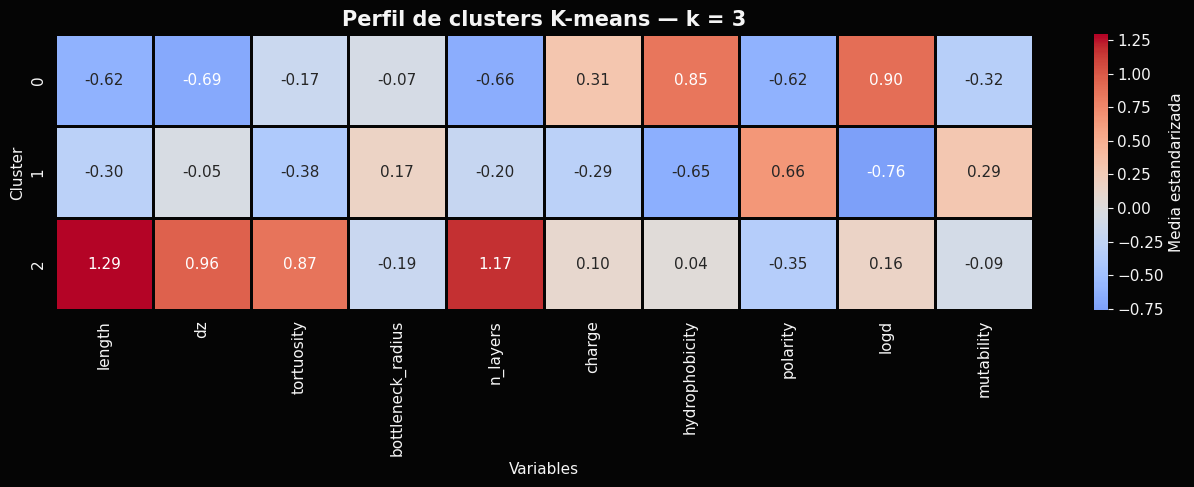

In [ ]:
# ============================================================
# 7. MODELOS K-MEANS: K = 2 Y K = 3
# ============================================================

kmeans_models = {}
kmeans_labels = {}
kmeans_scores = {}

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    kmeans_models[k] = model
    kmeans_labels[k] = labels

    kmeans_scores[k] = silhouette_score(
        X_scaled, labels
    )

    print(f"\nK-MEANS CON k = {k}")
    print(f"Inercia: {model.inertia_:.4f}")
    print(f"Silhouette: {kmeans_scores[k]:.4f}")

    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .rename("Número de observaciones")
        .to_string()
    )

# ============================================================
# 8. PCA: COMPARACIÓN K-MEANS K=2 VS K=3
# ============================================================

fig3, axes = plt.subplots(1, 2, figsize=(16, 7))
fig3.patch.set_facecolor(BLACK)

for ax, k in zip(axes, [2, 3]):

    sns.scatterplot(
        x=scores["PC1"],
        y=scores["PC2"],
        hue=kmeans_labels[k],
        palette={
            i: cluster_palette[i]
            for i in range(k)
        },
        s=70,
        edgecolor=WHITE,
        linewidth=0.4,
        alpha=0.85,
        ax=ax
    )

    ax.set_title(
        f"K-means — k = {k}\n"
        f"Silhouette = {kmeans_scores[k]:.3f}",
        color=WHITE,
        fontsize=15
    )

    ax.set_xlabel(
        f"PC1 ({explained[0]:.2f}%)",
        fontsize=12
    )

    ax.set_ylabel(
        f"PC2 ({explained[1]:.2f}%)",
        fontsize=12
    )

    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(
        title="Cluster",
        frameon=False,
        labelcolor=WHITE
    )

    for spine in ax.spines.values():
        spine.set_color(WHITE)

plt.suptitle(
    "K-means: comparación de 2 frente a 3 clusters",
    color=WHITE,
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ============================================================
# 9. PERFILES DE LOS CLUSTERS K-MEANS
# ============================================================

for k in [2, 3]:

    profile = X_original.copy()
    profile["Cluster"] = kmeans_labels[k]

    print(f"\nPERFIL MEDIO K-MEANS — k = {k}")

    print(
        profile.groupby("Cluster")
        .mean(numeric_only=True)
        .round(3)
        .to_string()
    )

    # Heatmap de medias estandarizadas
    profile_scaled = X_scaled_df.copy()
    profile_scaled["Cluster"] = kmeans_labels[k]

    means_scaled = profile_scaled.groupby(
        "Cluster"
    ).mean(numeric_only=True)

    fig, ax = plt.subplots(figsize=(13, 5))
    fig.patch.set_facecolor(BLACK)

    sns.heatmap(
        means_scaled,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.8,
        linecolor=BLACK,
        cbar_kws={"label": "Media estandarizada"},
        ax=ax
    )

    ax.set_title(
        f"Perfil de clusters K-means — k = {k}",
        color=WHITE,
        fontsize=15
    )
    ax.set_xlabel("Variables")
    ax.set_ylabel("Cluster")

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.set_tick_params(color=WHITE)
    cbar.set_label("Media estandarizada", color=WHITE)
    plt.setp(cbar.ax.get_yticklabels(), color=WHITE)

    plt.tight_layout()
    plt.show()

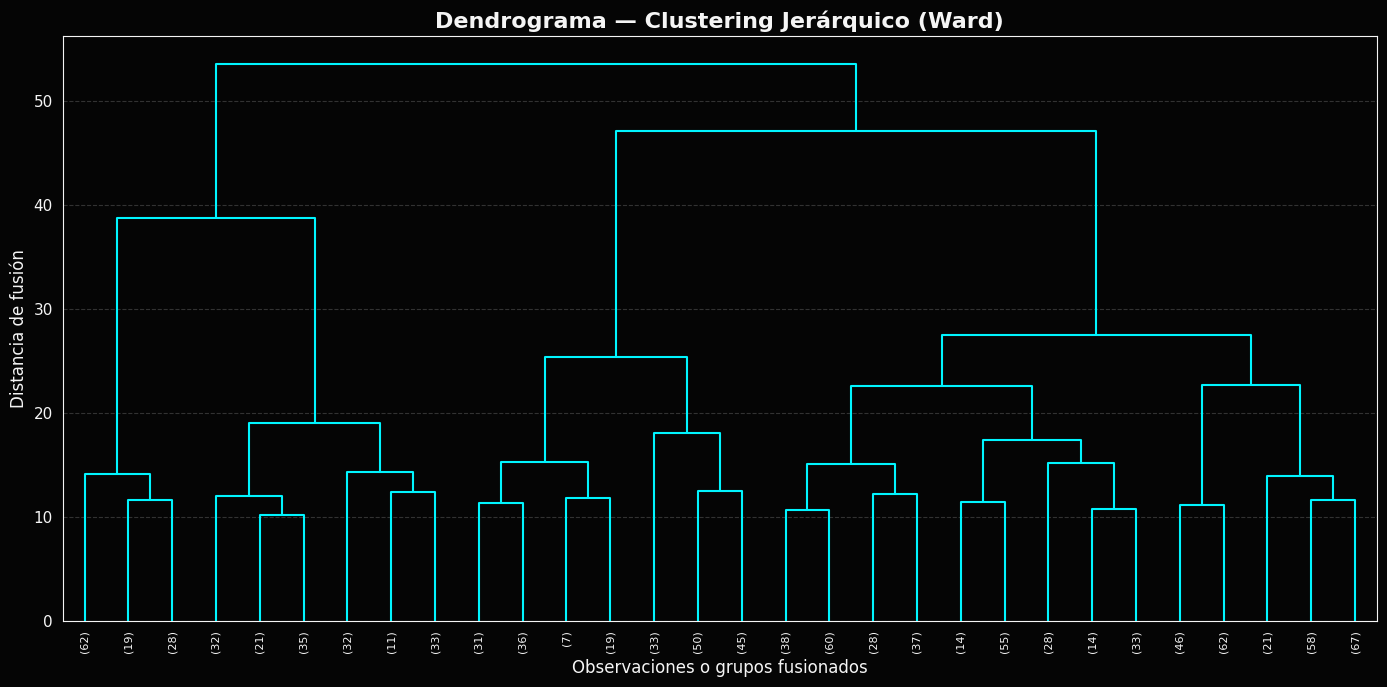


MÉTRICAS CLUSTERING JERÁRQUICO
 k  Silhouette
 2      0.1644
 3      0.1307
 4      0.1275
 5      0.0864
 6      0.0822


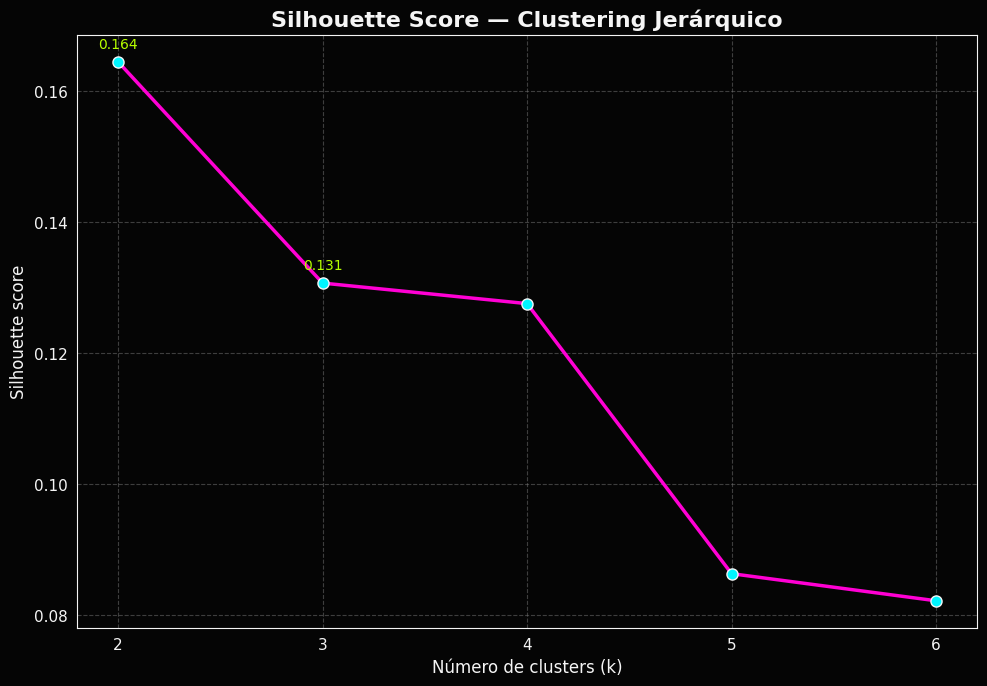

In [ ]:
# ============================================================
# 10. CLUSTERING JERÁRQUICO: DENDROGRAMA
# ============================================================

Z = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

fig4, ax4 = plt.subplots(figsize=(14, 7))
fig4.patch.set_facecolor(BLACK)

if len(X_scaled) > 100:

    dendrogram(
        Z,
        ax=ax4,
        truncate_mode="lastp",
        p=30,
        leaf_rotation=90,
        leaf_font_size=8,
        color_threshold=0,
        above_threshold_color=CYAN
    )

else:

    dendrogram(
        Z,
        ax=ax4,
        leaf_rotation=90,
        leaf_font_size=8,
        color_threshold=0,
        above_threshold_color=CYAN
    )

ax4.set_title(
    "Dendrograma — Clustering Jerárquico (Ward)",
    color=WHITE,
    fontsize=16
)
ax4.set_xlabel(
    "Observaciones o grupos fusionados",
    fontsize=12
)
ax4.set_ylabel("Distancia de fusión", fontsize=12)
ax4.grid(True, axis="y", linestyle="--", alpha=0.4)

for spine in ax4.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 11. SILHOUETTE PARA CLUSTERING JERÁRQUICO
# ============================================================

k_values_hierarchical = list(
    range(2, min(7, len(X_scaled)))
)

silhouettes_hierarchical = []

for k in k_values_hierarchical:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    silhouettes_hierarchical.append(
        silhouette_score(X_scaled, labels)
    )

metrics_hierarchical = pd.DataFrame({
    "k": k_values_hierarchical,
    "Silhouette": silhouettes_hierarchical
})

print("\nMÉTRICAS CLUSTERING JERÁRQUICO")
print(
    metrics_hierarchical.round(4).to_string(index=False)
)

fig5, ax5 = plt.subplots(figsize=(10, 7))
fig5.patch.set_facecolor(BLACK)

ax5.plot(
    k_values_hierarchical,
    silhouettes_hierarchical,
    color=MAGENTA,
    marker="o",
    markersize=8,
    linewidth=2.5,
    markerfacecolor=CYAN,
    markeredgecolor=WHITE
)

ax5.set_title(
    "Silhouette Score — Clustering Jerárquico",
    color=WHITE,
    fontsize=16
)
ax5.set_xlabel("Número de clusters (k)", fontsize=12)
ax5.set_ylabel("Silhouette score", fontsize=12)
ax5.set_xticks(k_values_hierarchical)
ax5.grid(True, linestyle="--", alpha=0.5)

for k in [2, 3]:
    idx = k_values_hierarchical.index(k)

    ax5.annotate(
        f"{silhouettes_hierarchical[idx]:.3f}",
        (k, silhouettes_hierarchical[idx]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color=LIME,
        fontsize=10
    )

for spine in ax5.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()


CLUSTERING JERÁRQUICO CON k = 2
Silhouette: 0.1644
0    782
1    273

CLUSTERING JERÁRQUICO CON k = 3
Silhouette: 0.1307
0    273
1    561
2    221


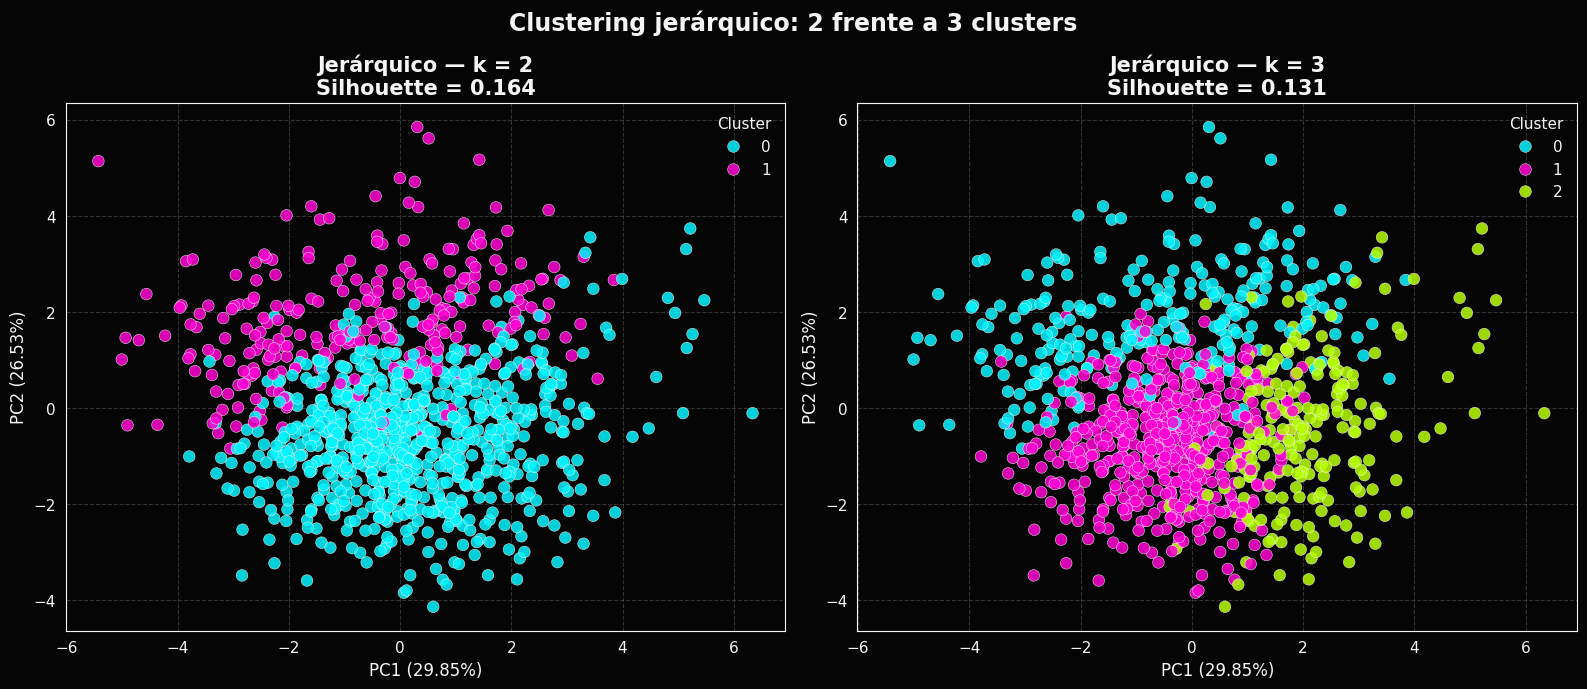


PERFIL MEDIO JERÁRQUICO — k = 2
          length      dz  tortuosity  bottleneck_radius  n_layers  charge  hydrophobicity  polarity   logd  mutability
Cluster                                                                                                               
0        150.565  77.231       1.950              0.332   129.391  -0.880           0.031    11.735  0.250      78.919
1        158.903  77.383       2.051              0.244   133.484   0.333           0.208     8.668  0.592      77.498


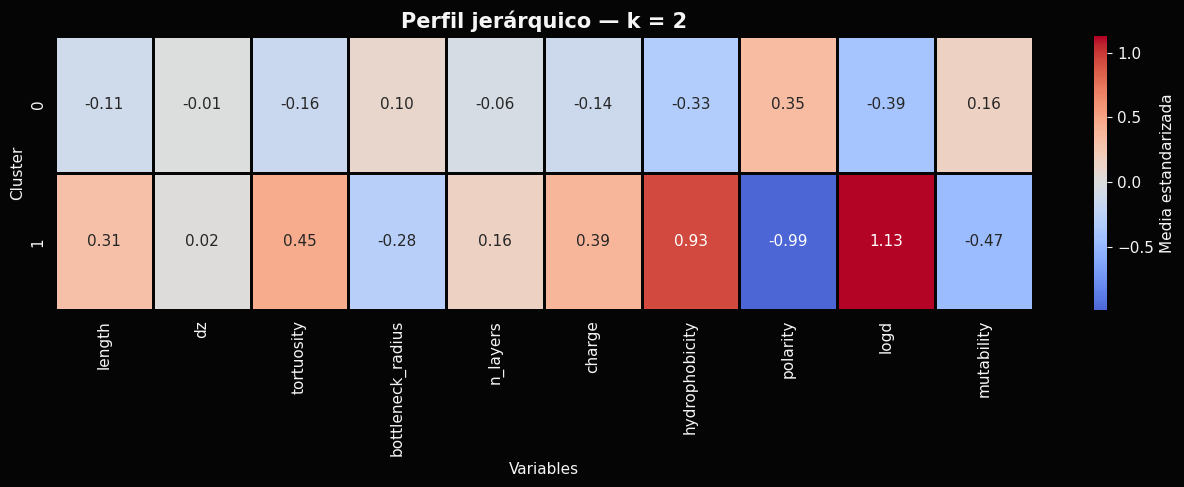


PERFIL MEDIO JERÁRQUICO — k = 3
          length      dz  tortuosity  bottleneck_radius  n_layers  charge  hydrophobicity  polarity   logd  mutability
Cluster                                                                                                               
0        158.903  77.383       2.051              0.244   133.484   0.333           0.208     8.668  0.592      77.498
1        143.555  75.373       1.908              0.354   122.346  -0.381           0.065    11.484  0.294      78.831
2        168.360  81.947       2.055              0.276   147.276  -2.145          -0.053    12.373  0.138      79.145


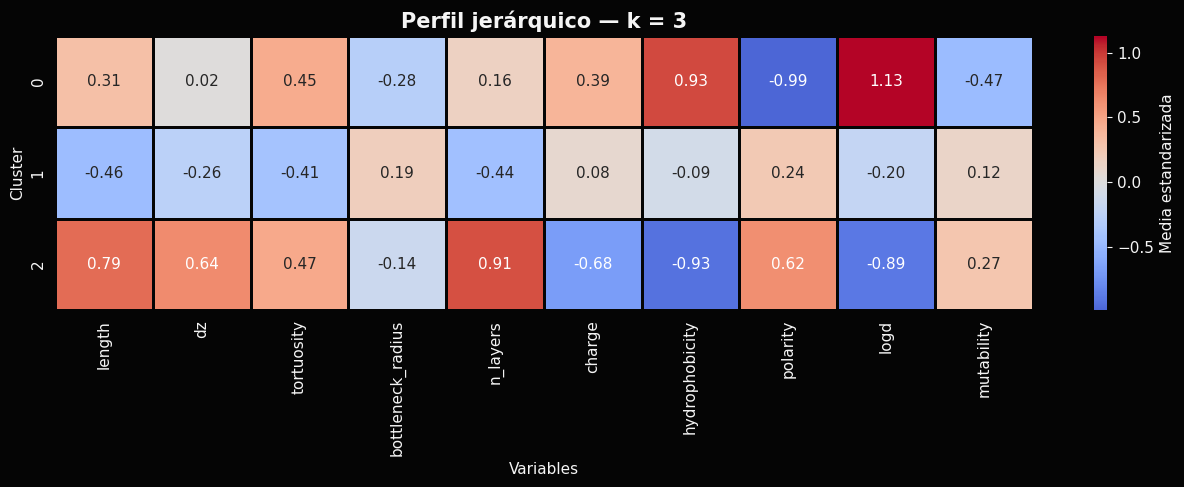

In [ ]:

# ============================================================
# 12. MODELOS JERÁRQUICOS: K = 2 Y K = 3
# ============================================================

hierarchical_models = {}
hierarchical_labels = {}
hierarchical_scores = {}

for k in [2, 3]:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_models[k] = model
    hierarchical_labels[k] = labels

    hierarchical_scores[k] = silhouette_score(
        X_scaled, labels
    )

    print(f"\nCLUSTERING JERÁRQUICO CON k = {k}")
    print(
        f"Silhouette: {hierarchical_scores[k]:.4f}"
    )

    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .rename("Número de observaciones")
        .to_string()
    )

# ============================================================
# 13. PCA: COMPARACIÓN JERÁRQUICA K=2 VS K=3
# ============================================================

fig6, axes = plt.subplots(1, 2, figsize=(16, 7))
fig6.patch.set_facecolor(BLACK)

for ax, k in zip(axes, [2, 3]):

    sns.scatterplot(
        x=scores["PC1"],
        y=scores["PC2"],
        hue=hierarchical_labels[k],
        palette={
            i: cluster_palette[i]
            for i in range(k)
        },
        s=70,
        edgecolor=WHITE,
        linewidth=0.4,
        alpha=0.85,
        ax=ax
    )

    ax.set_title(
        f"Jerárquico — k = {k}\n"
        f"Silhouette = {hierarchical_scores[k]:.3f}",
        color=WHITE,
        fontsize=15
    )

    ax.set_xlabel(
        f"PC1 ({explained[0]:.2f}%)",
        fontsize=12
    )

    ax.set_ylabel(
        f"PC2 ({explained[1]:.2f}%)",
        fontsize=12
    )

    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(
        title="Cluster",
        frameon=False,
        labelcolor=WHITE
    )

    for spine in ax.spines.values():
        spine.set_color(WHITE)

plt.suptitle(
    "Clustering jerárquico: 2 frente a 3 clusters",
    color=WHITE,
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ============================================================
# 14. PERFILES DE LOS CLUSTERS JERÁRQUICOS
# ============================================================

for k in [2, 3]:

    profile = X_original.copy()
    profile["Cluster"] = hierarchical_labels[k]

    print(f"\nPERFIL MEDIO JERÁRQUICO — k = {k}")

    print(
        profile.groupby("Cluster")
        .mean(numeric_only=True)
        .round(3)
        .to_string()
    )

    profile_scaled = X_scaled_df.copy()
    profile_scaled["Cluster"] = hierarchical_labels[k]

    means_scaled = profile_scaled.groupby(
        "Cluster"
    ).mean(numeric_only=True)

    fig, ax = plt.subplots(figsize=(13, 5))
    fig.patch.set_facecolor(BLACK)

    sns.heatmap(
        means_scaled,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.8,
        linecolor=BLACK,
        cbar_kws={"label": "Media estandarizada"},
        ax=ax
    )

    ax.set_title(
        f"Perfil jerárquico — k = {k}",
        color=WHITE,
        fontsize=15
    )
    ax.set_xlabel("Variables")
    ax.set_ylabel("Cluster")

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.set_tick_params(color=WHITE)
    cbar.set_label("Media estandarizada", color=WHITE)
    plt.setp(cbar.ax.get_yticklabels(), color=WHITE)

    plt.tight_layout()
    plt.show()


COMPARACIÓN FINAL
    Método  Número de clusters  Silhouette
   K-means                   2      0.1779
   K-means                   3      0.1700
Jerárquico                   2      0.1644
Jerárquico                   3      0.1307


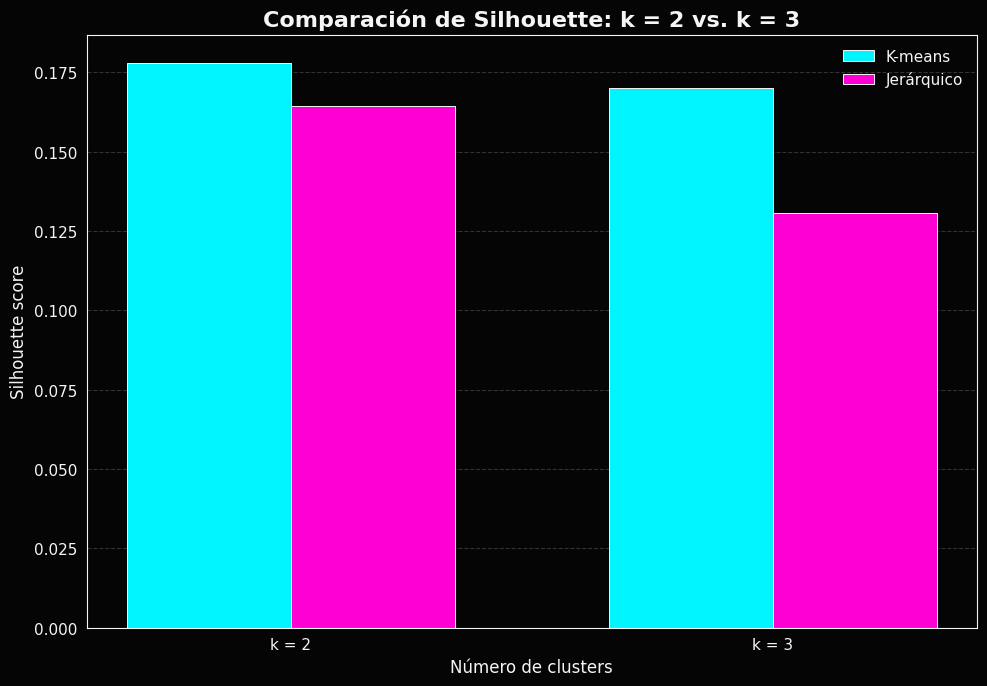


ARI para k = 2: 0.0220

ARI para k = 3: 0.2033


In [ ]:
# ============================================================
# 15. COMPARACIÓN GLOBAL
# ============================================================

comparison = pd.DataFrame({
    "Método": [
        "K-means",
        "K-means",
        "Jerárquico",
        "Jerárquico"
    ],
    "Número de clusters": [2, 3, 2, 3],
    "Silhouette": [
        kmeans_scores[2],
        kmeans_scores[3],
        hierarchical_scores[2],
        hierarchical_scores[3]
    ]
})

print("\nCOMPARACIÓN FINAL")
print(comparison.round(4).to_string(index=False))

# ============================================================
# 16. GRÁFICO COMPARATIVO DEL SILHOUETTE
# ============================================================

fig7, ax7 = plt.subplots(figsize=(10, 7))
fig7.patch.set_facecolor(BLACK)

x = np.arange(2)
width = 0.34

ax7.bar(
    x - width / 2,
    [kmeans_scores[2], kmeans_scores[3]],
    width,
    color=CYAN,
    edgecolor=WHITE,
    linewidth=0.7,
    label="K-means"
)

ax7.bar(
    x + width / 2,
    [hierarchical_scores[2], hierarchical_scores[3]],
    width,
    color=MAGENTA,
    edgecolor=WHITE,
    linewidth=0.7,
    label="Jerárquico"
)

ax7.set_title(
    "Comparación de Silhouette: k = 2 vs. k = 3",
    color=WHITE,
    fontsize=16
)
ax7.set_xlabel("Número de clusters", fontsize=12)
ax7.set_ylabel("Silhouette score", fontsize=12)
ax7.set_xticks(x)
ax7.set_xticklabels(["k = 2", "k = 3"])
ax7.grid(True, axis="y", linestyle="--", alpha=0.4)
ax7.set_axisbelow(True)
ax7.legend(frameon=False, labelcolor=WHITE)

for spine in ax7.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 17. ACUERDO ENTRE MÉTODOS PARA EL MISMO K
# ============================================================

for k in [2, 3]:

    ari = adjusted_rand_score(
        kmeans_labels[k],
        hierarchical_labels[k]
    )

    print(
        f"\nARI para k = {k}: {ari:.4f}"
    )

# ============================================================
# 18. RESTABLECER ESTILO
# ============================================================

plt.style.use("default")

### Valores a considerar

* Silhouette <0 -> Asignaciones posiblemente inadecuadas o grupos solapados.
*  0 < Silhouette <0.25 -> Separación debil
* 0.25 < Silhouette < 0.5 -> Estructura razonable
* 0.5 < Silhouette < 0.7 -> Buena separación.
* 0.7 < Silhouette -> Separación marcada.

* ARI cercano a 0 -> Acuerdo entre métodos similar al esperado por azar.
* ARI entre 0.5 a 0.75 -> Concordancia moderada a buena, como referencia orientativa.
* ARI > 0.75 -> Concordancia alta.
* ARI cercana a 1 -> Particiones identicas

### Respuestas

**1. ¿Cuántos clusters parecen razonables?**

Los resultados no proporcionan evidencia sólida de una estructura de clusters bien definida. Tanto para k-means como para el clustering jerárquico de Ward, los coeficientes de Silhouette son bajos, con valores máximos cercanos a 0,175 para las soluciones de dos y tres clusters. Esto indica una separación débil entre los grupos y un considerable solapamiento entre las observaciones.

Aunque el método del codo muestra posibles cambios de pendiente para k=2 y k=3, estos no parecen suficientemente pronunciados como para justificar una partición clara. Además, la representación de las observaciones en el espacio de los dos primeros componentes principales muestra una nube de puntos relativamente homogénea, sin agrupaciones visualmente evidentes.

Por tanto, aunque es posible obtener dos o tres clusters mediante ambos algoritmos, no existe evidencia suficiente para considerar que estas particiones representen grupos naturales bien definidos.

2. ¿Los clusters están claramente separados?

No. Los valores de Silhouette, inferiores a 0,25 y próximos a 0,175 en el mejor de los casos, indican una separación débil entre los grupos.

Además, las representaciones mediante PCA muestran que las asignaciones de los algoritmos no producen regiones claramente diferenciadas. K-means parece distribuir las observaciones principalmente a lo largo de PC1, mientras que Ward muestra una partición más relacionada con PC2 en la solución de dos clusters.

Estas diferencias sugieren que los algoritmos están identificando particiones distintas de la nube de datos, sin que se observe una estructura de separación consistente. El ARI cercano a cero respalda esta interpretación, ya que indica un bajo acuerdo entre ambos métodos para el mismo número de clusters.

3. ¿Qué características diferencian los grupos?

En la solución de Ward con k=2, la separación visual parece estar más relacionada con PC2. Sin embargo, esta diferenciación debe interpretarse con cautela, ya que la baja puntuación de Silhouette no respalda una separación clara entre los grupos.

Para determinar qué variables contribuyen a las diferencias observadas, sería necesario examinar los perfiles medios de las variables originales y estandarizadas de cada cluster. No obstante, incluso si se observan diferencias en algunas propiedades fisicoquímicas o geométricas, estas no implican necesariamente que existan grupos naturales diferenciados.

Por tanto, las diferencias entre los grupos deben considerarse descriptivas y exploratorias, no evidencia concluyente de estados estructurales distintos.

4. ¿Los clusters pueden interpretarse como diferentes estados estructurales?

Con los resultados obtenidos, no existe evidencia suficiente para afirmar que los clusters identificados correspondan a diferentes estados estructurales del túnel.

La representación PCA muestra una distribución relativamente continua de las observaciones, mientras que los bajos valores de Silhouette y el escaso acuerdo entre K-means y Ward sugieren que la partición depende considerablemente del algoritmo empleado.

Aunque PC1 y PC2 resumen dimensiones de variabilidad relacionadas con las propiedades geométricas y fisicoquímicas del sistema, sus loadings describen asociaciones entre variables y componentes, no la existencia de estados discretos. Por ello, la diferenciación de los clusters no puede atribuirse a una dimensión estructural específica sin evidencia adicional.

En conclusión, los resultados son más compatibles con una distribución continua de las características del túnel que con la existencia de dos o tres estados estructurales claramente diferenciados, al menos considerando las variables seleccionadas y los métodos de clustering empleados.

**NOTA** : ARI cercano a cero es evidencia de que K-means y Ward no recuperan particiones similares.

---

# PARTE X — CLUSTERS A LO LARGO DEL TIEMPO

## Actividad 11. Clustering + dinámica molecular

Una vez definidos los clusters, representar:

```text
cluster
  │
  │ ████
  │     █████
  │           ███
  │
  └──────────────── frame
```

### Preguntas

1. ¿Los clusters aparecen de manera persistente?
2. ¿Se producen transiciones entre estados?
3. ¿Hay períodos en los que el sistema permanece en un mismo cluster?
4. ¿Los cambios de cluster coinciden con cambios en `bottleneck_radius`?
5. ¿La clasificación obtenida por clustering parece representar estados estructurales reales o simplemente fluctuaciones?


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.stats import pearsonr, spearmanr, pointbiserialr

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})

# ============================================================
# 1. SELECCIÓN DE VARIABLES
# ============================================================

# Ajustar esta lista a las variables disponibles por frame.
cluster_vars = [
    "length",
    "dz",
    "tortuosity",
    "bottleneck_radius",
    "n_layers",
    "charge",
    "hydrophobicity",
    "polarity",
    "logd",
    "mutability"
]

# Comprobar que las columnas existen
required_cols = ["frame", "bottleneck_radius"] + cluster_vars

missing_cols = [
    col for col in set(required_cols)
    if col not in df_results.columns
]

if missing_cols:
    raise KeyError(
        "Faltan columnas en df_results: "
        f"{missing_cols}. Comprueba si los datos están "
        "realmente organizados por frame."
    )

# Copia de las variables utilizadas
df_time = df_results.copy()

# Conversión numérica
df_time["frame"] = pd.to_numeric(
    df_time["frame"], errors="coerce"
)

for col in cluster_vars:
    df_time[col] = pd.to_numeric(
        df_time[col], errors="coerce"
    )

# Eliminar infinitos y valores faltantes
df_time = df_time.replace(
    [np.inf, -np.inf], np.nan
)

df_time = df_time.dropna(
    subset=["frame"] + cluster_vars
)

# Orden cronológico
df_time = df_time.sort_values("frame").copy()

# Comprobar si hay varios registros por frame
if df_time["frame"].duplicated().any():
    raise ValueError(
        "Hay varios registros por frame. "
        "Debes identificar el túnel correspondiente o "
        "agrupar los registros por frame antes del clustering."
    )

# Eliminar variables constantes
constant_vars = [
    col for col in cluster_vars
    if df_time[col].nunique() <= 1
]

if constant_vars:
    print("Variables constantes eliminadas:", constant_vars)
    cluster_vars = [
        col for col in cluster_vars
        if col not in constant_vars
    ]

if len(cluster_vars) < 2:
    raise ValueError(
        "Se necesitan al menos dos variables "
        "no constantes para el clustering."
    )

if len(df_time) < 3:
    raise ValueError(
        "Se necesitan al menos 3 frames válidos."
    )

print("Número de frames:", len(df_time))
print("Variables utilizadas:", cluster_vars)
print(
    "Intervalo de frames:",
    df_time["frame"].min(),
    "-",
    df_time["frame"].max()
)

# ============================================================
# 2. ESTANDARIZACIÓN Y K-MEANS (K = 2)
# ============================================================

X_original = df_time[cluster_vars].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_original)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

df_time["cluster"] = kmeans.fit_predict(X_scaled)

# ============================================================
# 3. IDENTIFICAR LOS CLUSTERS POR BOTTLENECK RADIUS
# ============================================================

# Las etiquetas 0 y 1 son arbitrarias.
# Para facilitar la interpretación, asignamos:
# Cluster 0 = menor bottleneck_radius medio
# Cluster 1 = mayor bottleneck_radius medio

radius_means = df_time.groupby(
    "cluster"
)["bottleneck_radius"].mean()

cluster_order = radius_means.sort_values().index.tolist()

cluster_mapping = {
    cluster_order[0]: 0,
    cluster_order[1]: 1
}

df_time["cluster"] = df_time["cluster"].map(
    cluster_mapping
)

cluster_names = {
    0: "Radio medio menor",
    1: "Radio medio mayor"
}

print("\nTAMAÑO DE LOS CLUSTERS")
print(
    df_time["cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nRADIO MEDIO POR CLUSTER")
print(
    df_time.groupby("cluster")["bottleneck_radius"]
    .agg(["mean", "median", "std", "count"])
    .round(4)
    .to_string()
)

Número de frames: 1055
Variables utilizadas: ['length', 'dz', 'tortuosity', 'bottleneck_radius', 'n_layers', 'charge', 'hydrophobicity', 'polarity', 'logd', 'mutability']
Intervalo de frames: 0 - 1054

TAMAÑO DE LOS CLUSTERS
cluster
0    428
1    627

RADIO MEDIO POR CLUSTER
           mean  median     std  count
cluster                               
0        0.2716   0.257  0.2284    428
1        0.3346   0.309  0.2371    627


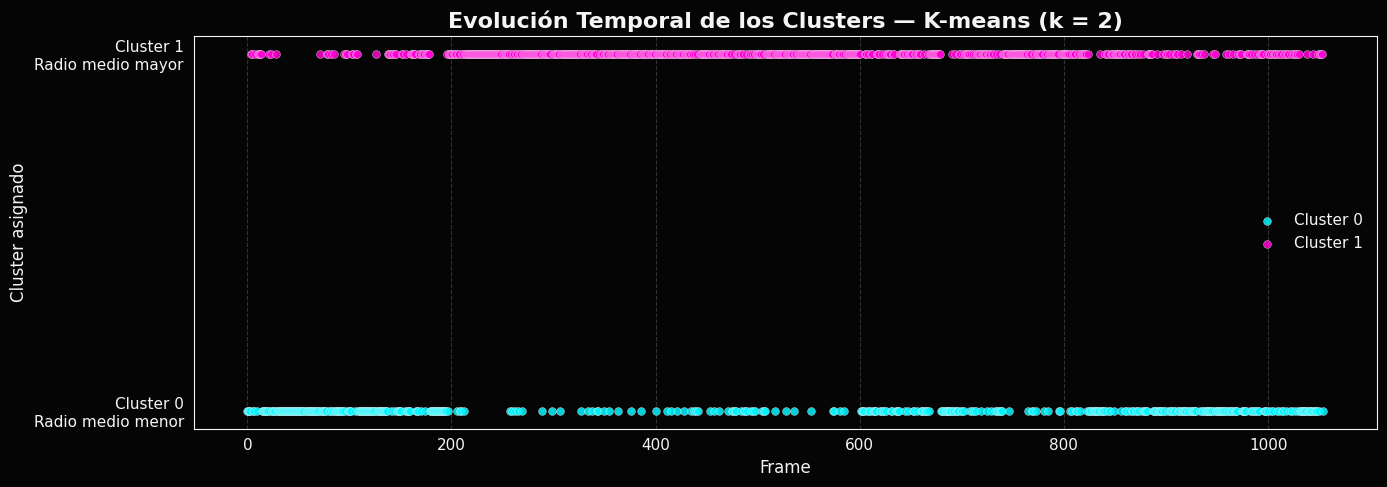

In [ ]:
# ============================================================
# 4. EVOLUCIÓN TEMPORAL DE LOS CLUSTERS
# ============================================================

fig1, ax1 = plt.subplots(figsize=(14, 5))
fig1.patch.set_facecolor(BLACK)

cluster_colors = {
    0: CYAN,
    1: MAGENTA
}

for cluster in [0, 1]:

    subset = df_time[df_time["cluster"] == cluster]

    ax1.scatter(
        subset["frame"],
        subset["cluster"],
        color=cluster_colors[cluster],
        label=f"Cluster {cluster}",
        s=32,
        alpha=0.85,
        edgecolor=WHITE,
        linewidth=0.3
    )

ax1.set_title(
    "Evolución Temporal de los Clusters — K-means (k = 2)",
    color=WHITE,
    fontsize=16
)
ax1.set_xlabel("Frame", fontsize=12)
ax1.set_ylabel("Cluster asignado", fontsize=12)

ax1.set_yticks([0, 1])
ax1.set_yticklabels([
    "Cluster 0\nRadio medio menor",
    "Cluster 1\nRadio medio mayor"
])

ax1.grid(True, axis="x", linestyle="--", alpha=0.4)
ax1.legend(frameon=False, labelcolor=WHITE)

for spine in ax1.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

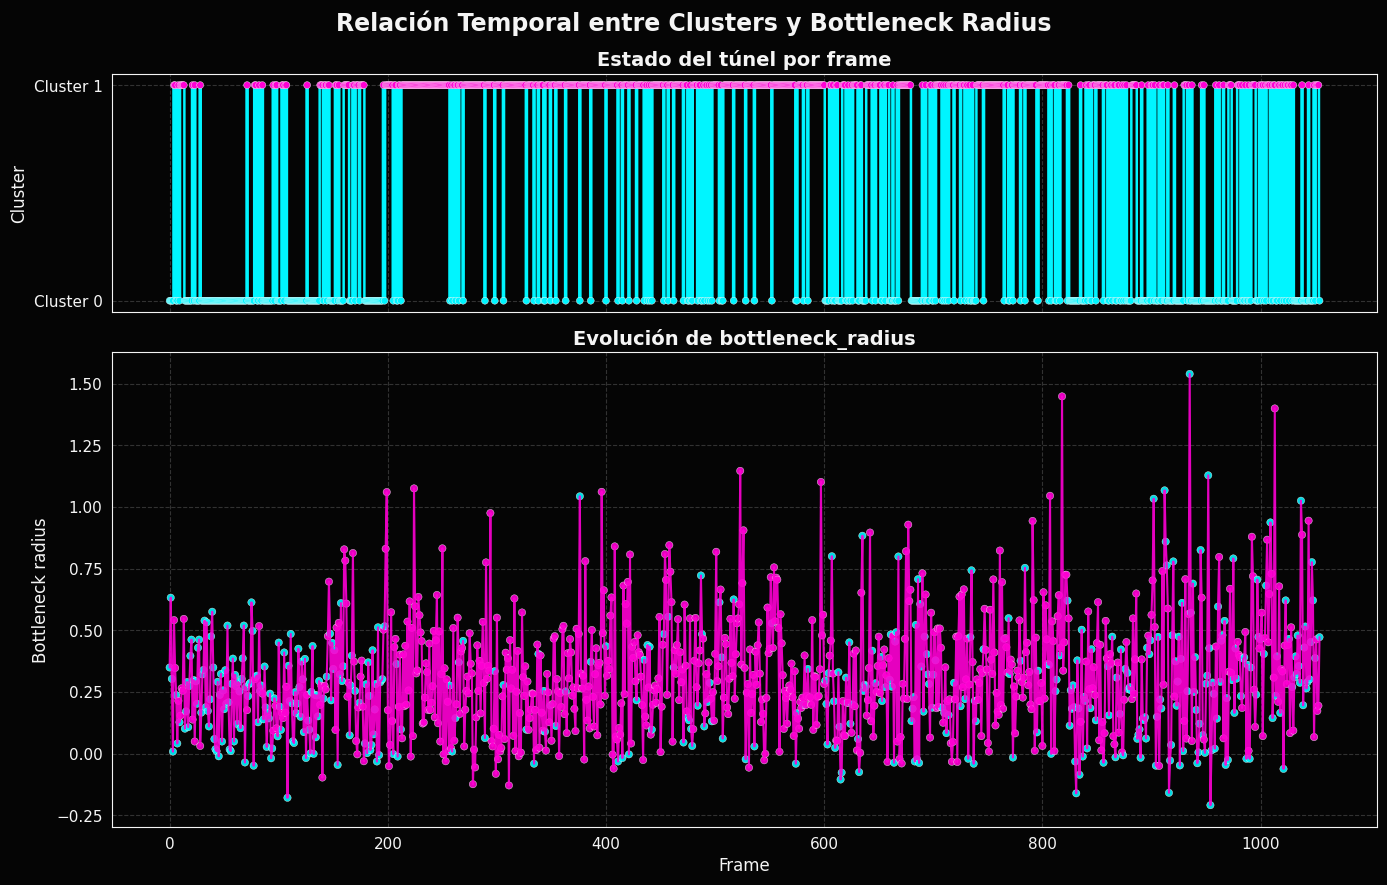

In [ ]:
# ============================================================
# 5. CLUSTER VS BOTTLENECK RADIUS
# ============================================================

fig2, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2]}
)

fig2.patch.set_facecolor(BLACK)

# ------------------------------------------------------------
# SUBPLOT 1: CLUSTER A LO LARGO DEL TIEMPO
# ------------------------------------------------------------

axes[0].step(
    df_time["frame"],
    df_time["cluster"],
    where="mid",
    color=CYAN,
    linewidth=1.8
)

axes[0].scatter(
    df_time["frame"],
    df_time["cluster"],
    c=df_time["cluster"].map(cluster_colors),
    s=25,
    edgecolor=WHITE,
    linewidth=0.3,
    zorder=3
)

axes[0].set_title(
    "Estado del túnel por frame",
    color=WHITE,
    fontsize=14
)

axes[0].set_ylabel("Cluster", fontsize=12)
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Cluster 0", "Cluster 1"])
axes[0].grid(True, linestyle="--", alpha=0.4)

# ------------------------------------------------------------
# SUBPLOT 2: BOTTLENECK RADIUS A LO LARGO DEL TIEMPO
# ------------------------------------------------------------

axes[1].plot(
    df_time["frame"],
    df_time["bottleneck_radius"],
    color=MAGENTA,
    linewidth=1.5,
    alpha=0.9
)

axes[1].scatter(
    df_time["frame"],
    df_time["bottleneck_radius"],
    c=df_time["cluster"].map(cluster_colors),
    s=28,
    edgecolor=WHITE,
    linewidth=0.3,
    alpha=0.9
)

axes[1].set_title(
    "Evolución de bottleneck_radius",
    color=WHITE,
    fontsize=14
)

axes[1].set_xlabel("Frame", fontsize=12)
axes[1].set_ylabel("Bottleneck radius", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.4)

for ax in axes:
    ax.set_facecolor(BLACK)

    for spine in ax.spines.values():
        spine.set_color(WHITE)

plt.suptitle(
    "Relación Temporal entre Clusters y Bottleneck Radius",
    color=WHITE,
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


CORRELACIÓN CLUSTER VS BOTTLENECK RADIUS
Punto-biserial: r = 0.1314, p = 1.8445e-05
Pearson:        r = 0.1314, p = 1.8445e-05
Spearman:       rho = 0.1347, p = 1.1256e-05

BOTTLENECK RADIUS POR CLUSTER
         count    mean  median     std
cluster                               
0          428  0.2716   0.257  0.2284
1          627  0.3346   0.309  0.2371

Diferencia de medias (Cluster 1 - Cluster 0): 0.0630


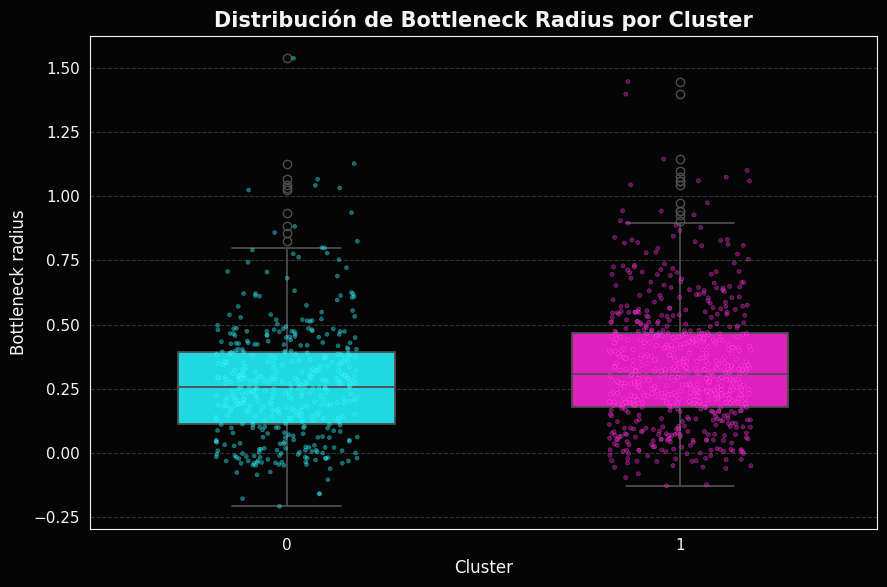

In [ ]:
# ============================================================
# 6. CORRELACIÓN ENTRE CLUSTER Y BOTTLENECK RADIUS
# ============================================================

cluster_binary = df_time["cluster"].to_numpy()
radius = df_time["bottleneck_radius"].to_numpy()

if len(np.unique(cluster_binary)) != 2:
    raise ValueError(
        "K-means no ha generado dos clusters no vacíos."
    )

# Correlación punto-biserial
r_pb, p_pb = pointbiserialr(
    cluster_binary,
    radius
)

# Pearson: equivalente para una variable binaria 0/1
r_pearson, p_pearson = pearsonr(
    cluster_binary,
    radius
)

# Spearman: asociación monotónica
rho_spearman, p_spearman = spearmanr(
    cluster_binary,
    radius
)

print("\nCORRELACIÓN CLUSTER VS BOTTLENECK RADIUS")
print(f"Punto-biserial: r = {r_pb:.4f}, p = {p_pb:.4e}")
print(f"Pearson:        r = {r_pearson:.4f}, p = {p_pearson:.4e}")
print(f"Spearman:       rho = {rho_spearman:.4f}, p = {p_spearman:.4e}")

# ============================================================
# 7. DIFERENCIAS DE BOTTLENECK RADIUS ENTRE CLUSTERS
# ============================================================

radius_profile = df_time.groupby(
    "cluster"
)["bottleneck_radius"].agg(
    ["count", "mean", "median", "std"]
)

print("\nBOTTLENECK RADIUS POR CLUSTER")
print(radius_profile.round(4).to_string())

mean_difference = (
    radius_profile.loc[1, "mean"]
    - radius_profile.loc[0, "mean"]
)

print(
    "\nDiferencia de medias (Cluster 1 - Cluster 0): "
    f"{mean_difference:.4f}"
)

# ============================================================
# 8. BOXPLOT POR CLUSTER
# ============================================================

fig3, ax3 = plt.subplots(figsize=(9, 6))
fig3.patch.set_facecolor(BLACK)

sns.boxplot(
    data=df_time,
    x="cluster",
    y="bottleneck_radius",
    hue="cluster",
    palette=cluster_colors,
    legend=False,
    width=0.55,
    linewidth=1.3,
    ax=ax3
)

sns.stripplot(
    data=df_time,
    x="cluster",
    y="bottleneck_radius",
    hue="cluster",
    palette=cluster_colors,
    legend=False,
    size=3,
    alpha=0.45,
    jitter=0.18,
    edgecolor=WHITE,
    linewidth=0.2,
    ax=ax3
)

ax3.set_title(
    "Distribución de Bottleneck Radius por Cluster",
    color=WHITE,
    fontsize=15
)

ax3.set_xlabel("Cluster", fontsize=12)
ax3.set_ylabel("Bottleneck radius", fontsize=12)
ax3.grid(True, axis="y", linestyle="--", alpha=0.4)

for spine in ax3.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 9. RESTABLECER ESTILO
# ============================================================

plt.style.use("default")

#### Respuestas

**1. ¿Los clusters aparecen de manera persistente?**

A simple vista del gráfico de evolución temporal de los clusters: El cluster 1 (radio menor) a parece discretamente y pocas veces comparado al cluster 0 (radio mayor) hasta aproximadamente el frame 200. Luego de eso, aparece más persistentemente el cluster 1 y menos veces el cluster 0, hasta el frame 800 donde ambos aparecen de forma persistente.
Esto se correlaciona con los gráficos de las variables anteriormente realizado respecto de los frames: En el frame 200 había un shift de la media de la tortuosidad y longitud. En este caso se hace evidente un aparente segundo shift en el frame 800.

2. ¿Se producen transiciones entre estados?

Aparentemente, hay un pasaje de estado dada la frecuencia de los cluster en el frame 200 donde predomina anteriormente el cluster 0 y luego el cluster 1.

3. ¿Hay períodos en los que el sistema permanece en un mismo cluster?

Luego del frame 200, el sistema permanece más en el cluster 1 hasta el frame 800.

4. ¿Los cambios de cluster coinciden con cambios en `bottleneck_radius`?

No, ambos cluster correlacionan con bottleneck_radius. Es decir, ninguno de los clusters parecen representar un cambio de estado debido a un cambio local del radio de cuello de botella de la proteina.

5. ¿La clasificación obtenida por clustering parece representar estados
estructurales reales o simplemente fluctuaciones?

Por lo menos, si se tiene en cuenta los cambios de tortuosidad y longitud en el frame 200 podría haber una asociación entre los dos clusters y un cambio estructural real.

---

# PARTE XI — BOOTSTRAP

## Actividad 12. Bootstrap de una correlación

Seleccionar una asociación de interés, por ejemplo:

```text
bottleneck_radius
```

vs.

```text
tortuosity
```

Calcular la correlación observada.

Luego realizar un **bootstrap con al menos 2000 réplicas**.

Para cada réplica:

1. remuestrear las observaciones;
2. calcular la correlación;
3. almacenar el resultado.

Representar la distribución bootstrap.

Calcular un intervalo de confianza del 95 %.

### Comparar

* intervalo de confianza paramétrico;
* intervalo bootstrap.

### Preguntas

1. ¿Los resultados son similares?
2. ¿La distribución bootstrap es aproximadamente simétrica?
3. ¿Qué información proporciona la distribución bootstrap?

#### Nota

El objetivo es comprobar cuánto varía la estimación de la correlación ante cambios en la muestra.

* Intervalos estrechos: mayor precisión de la estimación, bajo los supuestos del método.
* Intervalos amplios: mayor incertidumbre.
* Intervalos que contienen el cero: los datos no permiten descartar una correlación nula al nivel del 5 % mediante ese intervalo.
* Intervalos que no contienen el cero: evidencia de una asociación lineal distinta de cero bajo los supuestos correspondientes.

##### Nota 2

Para un análisis formal de la dinámica, sería preferible un bootstrap por bloques temporales, que remuestrea segmentos consecutivos de frames y conserva parte de la dependencia temporal. Si los datos son independientes entre sí, el bootstrap ordinario es más apropiado.
Por último, el intervalo paramétrico calculado aquí usa la transformación de Fisher, que es una aproximación habitual para la correlación de Pearson; no es un intervalo exacto para cualquier distribución de datos.

Número de observaciones: 1055
Variables: ['bottleneck_radius', 'tortuosity']

CORRELACIÓN OBSERVADA
Pearson r = -0.1535
p-valor   = 5.4349e-07

INTERVALO PARAMÉTRICO DEL 95 %
IC inferior: -0.2119
IC superior: -0.0940

BOOTSTRAP
Réplicas solicitadas: 2000
Réplicas válidas: 2000

INTERVALO BOOTSTRAP DEL 95 %
IC inferior: -0.2096
IC superior: -0.0965


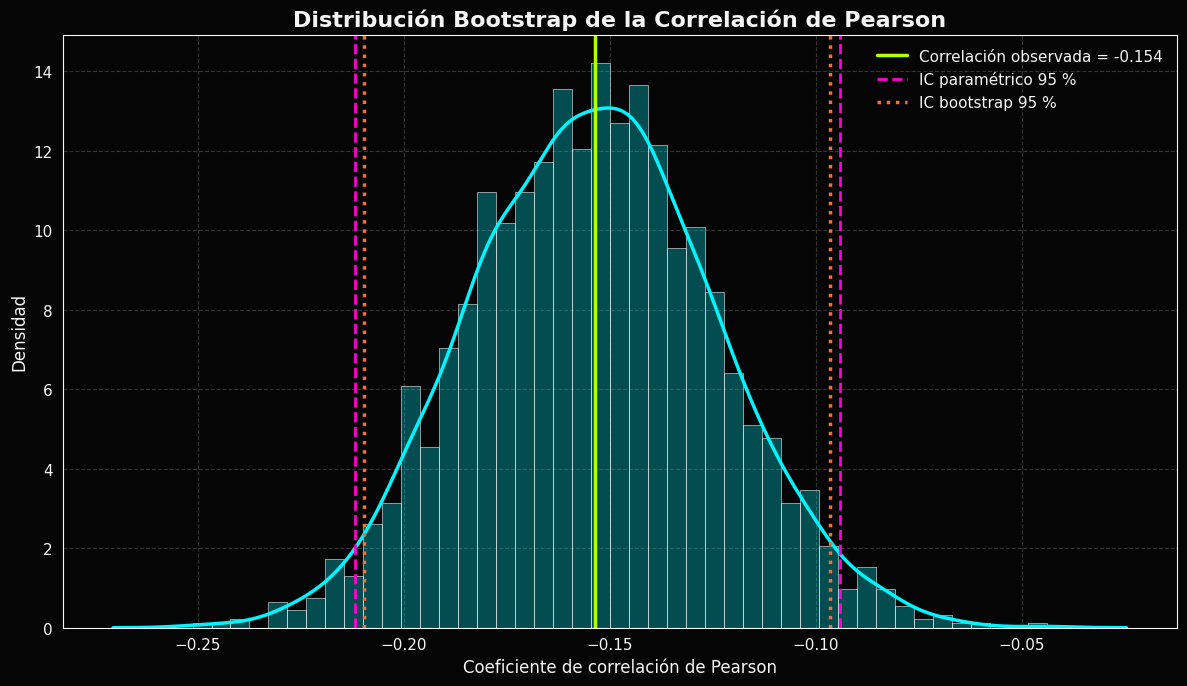


COMPARACIÓN DE RESULTADOS
               Método  Estimación  IC inferior 95 %  IC superior 95 %
Correlación observada     -0.1535               NaN               NaN
 Paramétrico (Fisher)     -0.1535           -0.2119           -0.0940
  Bootstrap percentil     -0.1539           -0.2096           -0.0965

ANCHURA DE LOS INTERVALOS
Paramétrico: 0.1179
Bootstrap:   0.1132

INTERPRETACIÓN PRELIMINAR
El IC paramétrico no contiene el cero.
El IC bootstrap no contiene el cero.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, norm

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})

# ============================================================
# 1. SELECCIÓN Y LIMPIEZA DE VARIABLES
# ============================================================

variables = [
    "bottleneck_radius",
    "tortuosity"
]

X_original = df_results[variables].copy()

X_original = X_original.apply(
    pd.to_numeric,
    errors="coerce"
)

X_original = X_original.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

if len(X_original) < 4:
    raise ValueError(
        "Se necesitan al menos 4 observaciones válidas."
    )

if any(X_original[col].nunique() < 2 for col in variables):
    raise ValueError(
        "Las variables deben presentar variabilidad "
        "para calcular la correlación."
    )

x = X_original["bottleneck_radius"].to_numpy()
y = X_original["tortuosity"].to_numpy()

n = len(x)

print("Número de observaciones:", n)
print("Variables:", variables)

# ============================================================
# 2. CORRELACIÓN OBSERVADA
# ============================================================

r_observado, p_observado = pearsonr(x, y)

print("\nCORRELACIÓN OBSERVADA")
print(f"Pearson r = {r_observado:.4f}")
print(f"p-valor   = {p_observado:.4e}")

# ============================================================
# 3. INTERVALO DE CONFIANZA PARAMÉTRICO DEL 95 %
#    TRANSFORMACIÓN Z DE FISHER
# ============================================================

alpha = 0.05

# La transformación de Fisher requiere |r| < 1
if abs(r_observado) >= 1:
    raise ValueError(
        "La correlación es exactamente -1 o 1. "
        "No se puede aplicar la transformación de Fisher "
        "de esta forma."
    )

z_observado = np.arctanh(r_observado)

se_z = 1 / np.sqrt(n - 3)

z_critico = norm.ppf(1 - alpha / 2)

z_inf = z_observado - z_critico * se_z
z_sup = z_observado + z_critico * se_z

ic_parametrico = (
    np.tanh(z_inf),
    np.tanh(z_sup)
)

print("\nINTERVALO PARAMÉTRICO DEL 95 %")
print(f"IC inferior: {ic_parametrico[0]:.4f}")
print(f"IC superior: {ic_parametrico[1]:.4f}")

# ============================================================
# 4. BOOTSTRAP: 2000 RÉPLICAS
# ============================================================

n_bootstrap = 2000
rng = np.random.default_rng(42)

correlaciones_bootstrap = np.empty(n_bootstrap)

for i in range(n_bootstrap):

    # Remuestrear índices con reemplazo.
    # Se mantienen juntas las parejas (x, y).
    indices = rng.integers(0, n, size=n)

    x_boot = x[indices]
    y_boot = y[indices]

    # Si alguna réplica presenta una variable constante,
    # su correlación no está definida.
    if (
        np.std(x_boot) == 0
        or np.std(y_boot) == 0
    ):
        correlaciones_bootstrap[i] = np.nan
        continue

    correlaciones_bootstrap[i] = np.corrcoef(
        x_boot,
        y_boot
    )[0, 1]

# Eliminar réplicas con correlación no definida
correlaciones_bootstrap = correlaciones_bootstrap[
    np.isfinite(correlaciones_bootstrap)
]

if len(correlaciones_bootstrap) < 0.95 * n_bootstrap:
    print(
        "\nAdvertencia: más del 5 % de las réplicas "
        "presentaron correlaciones no definidas."
    )

print("\nBOOTSTRAP")
print("Réplicas solicitadas:", n_bootstrap)
print("Réplicas válidas:", len(correlaciones_bootstrap))

# ============================================================
# 5. INTERVALO DE CONFIANZA BOOTSTRAP DEL 95 %
#    MÉTODO PERCENTIL
# ============================================================

ic_bootstrap = np.percentile(
    correlaciones_bootstrap,
    [2.5, 97.5]
)

print("\nINTERVALO BOOTSTRAP DEL 95 %")
print(f"IC inferior: {ic_bootstrap[0]:.4f}")
print(f"IC superior: {ic_bootstrap[1]:.4f}")

# ============================================================
# 6. DISTRIBUCIÓN BOOTSTRAP
# ============================================================

fig1, ax1 = plt.subplots(figsize=(12, 7))
fig1.patch.set_facecolor(BLACK)

sns.histplot(
    correlaciones_bootstrap,
    bins=45,
    stat="density",
    color=CYAN,
    alpha=0.30,
    edgecolor=WHITE,
    linewidth=0.4,
    ax=ax1
)

sns.kdeplot(
    correlaciones_bootstrap,
    color=CYAN,
    linewidth=2.5,
    ax=ax1
)

# Correlación observada
ax1.axvline(
    r_observado,
    color=LIME,
    linestyle="-",
    linewidth=2.5,
    label=f"Correlación observada = {r_observado:.3f}"
)

# IC paramétrico
ax1.axvline(
    ic_parametrico[0],
    color=MAGENTA,
    linestyle="--",
    linewidth=2,
    label="IC paramétrico 95 %"
)

ax1.axvline(
    ic_parametrico[1],
    color=MAGENTA,
    linestyle="--",
    linewidth=2
)

# IC bootstrap
ax1.axvline(
    ic_bootstrap[0],
    color=ORANGE,
    linestyle=":",
    linewidth=2.5,
    label="IC bootstrap 95 %"
)

ax1.axvline(
    ic_bootstrap[1],
    color=ORANGE,
    linestyle=":",
    linewidth=2.5
)

ax1.set_title(
    "Distribución Bootstrap de la Correlación de Pearson",
    color=WHITE,
    fontsize=16
)

ax1.set_xlabel(
    "Coeficiente de correlación de Pearson",
    fontsize=12
)

ax1.set_ylabel(
    "Densidad",
    fontsize=12
)

ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, labelcolor=WHITE)

for spine in ax1.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 7. COMPARACIÓN DE LOS INTERVALOS
# ============================================================

summary = pd.DataFrame({
    "Método": [
        "Correlación observada",
        "Paramétrico (Fisher)",
        "Bootstrap percentil"
    ],
    "Estimación": [
        r_observado,
        r_observado,
        np.mean(correlaciones_bootstrap)
    ],
    "IC inferior 95 %": [
        np.nan,
        ic_parametrico[0],
        ic_bootstrap[0]
    ],
    "IC superior 95 %": [
        np.nan,
        ic_parametrico[1],
        ic_bootstrap[1]
    ]
})

print("\nCOMPARACIÓN DE RESULTADOS")
print(summary.round(4).to_string(index=False))

# ============================================================
# 8. ANCHURA DE LOS INTERVALOS
# ============================================================

width_parametrico = (
    ic_parametrico[1] - ic_parametrico[0]
)

width_bootstrap = (
    ic_bootstrap[1] - ic_bootstrap[0]
)

print("\nANCHURA DE LOS INTERVALOS")
print(f"Paramétrico: {width_parametrico:.4f}")
print(f"Bootstrap:   {width_bootstrap:.4f}")

print("\nINTERPRETACIÓN PRELIMINAR")

if ic_parametrico[0] > 0 or ic_parametrico[1] < 0:
    print("El IC paramétrico no contiene el cero.")
else:
    print("El IC paramétrico contiene el cero.")

if ic_bootstrap[0] > 0 or ic_bootstrap[1] < 0:
    print("El IC bootstrap no contiene el cero.")
else:
    print("El IC bootstrap contiene el cero.")

# ============================================================
# 9. RESTABLECER ESTILO
# ============================================================

plt.style.use("default")

In [ ]:
# Determinar el skewness de la distribución bootstrap:
# ============================================================
# 5.1. SKEWNESS DE LA DISTRIBUCIÓN BOOTSTRAP
# ============================================================

from scipy.stats import skew

skewness_bootstrap = skew(
    correlaciones_bootstrap,
    bias=False
)

print("\nASIMETRÍA DE LA DISTRIBUCIÓN BOOTSTRAP")
print(f"Skewness = {skewness_bootstrap:.4f}")

# Interpretación
if skewness_bootstrap > 0.5:
    print("Distribución con asimetría positiva (cola derecha).")
elif skewness_bootstrap < -0.5:
    print("Distribución con asimetría negativa (cola izquierda).")
else:
    print("Distribución aproximadamente simétrica.")


ASIMETRÍA DE LA DISTRIBUCIÓN BOOTSTRAP
Skewness = 0.0645
Distribución aproximadamente simétrica.


#### Respuestas

**1. ¿Los resultados son similares?**

La correlación observada entre radio_cuello_botella y tortuosidad era de -0,1535 y el paramétrico (Fisher) dio igual. Mediante Boostrap se obtuvo -0,1539 como media en un IC 95% superponible con el paramétrico, así que son casi iguales.

**2. ¿La distribución bootstrap es aproximadamente simétrica?**

La distribución en el gráfico se observa como simétrica. Lo cual, fue confirmado por el calculo del skewness.

**3. ¿Qué información proporciona la distribución bootstrap?**

La simetría de la distribución bootstrap de la correlación permite evaluar cuánto varía la r_Pearson al cambiar las observaciones de la muestra mediante remuestreo, es decir, cuanto más estrecho, menos variabilidad. Al ser casi igual al de Fisher indica que ambas estimaciones producen incertidumbre compatibles.

---

# PARTE XII — BOOTSTRAP DE REGRESIÓN

## Actividad 13. Estabilidad de la pendiente

Realizar bootstrap de la pendiente del modelo:

```text
bottleneck_radius ~ tortuosity
```

Obtener una distribución de pendientes.

Calcular un intervalo de confianza del 95 %.

### Preguntas

1. ¿La pendiente es estable?
2. ¿El intervalo contiene el valor cero?
3. ¿El resultado coincide con la inferencia paramétrica?
4. ¿Qué interpretación biológica darían?

ACTIVIDAD 13. ESTABILIDAD DE LA PENDIENTE
Modelo: bottleneck_radius ~ tortuosity
Observaciones válidas: 1055

REGRESIÓN LINEAL ORIGINAL
                            OLS Regression Results                            
Dep. Variable:      bottleneck_radius   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     25.42
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           5.43e-07
Time:                        01:12:11   Log-Likelihood:                 41.559
No. Observations:                1055   AIC:                            -79.12
Df Residuals:                    1053   BIC:                            -69.20
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.

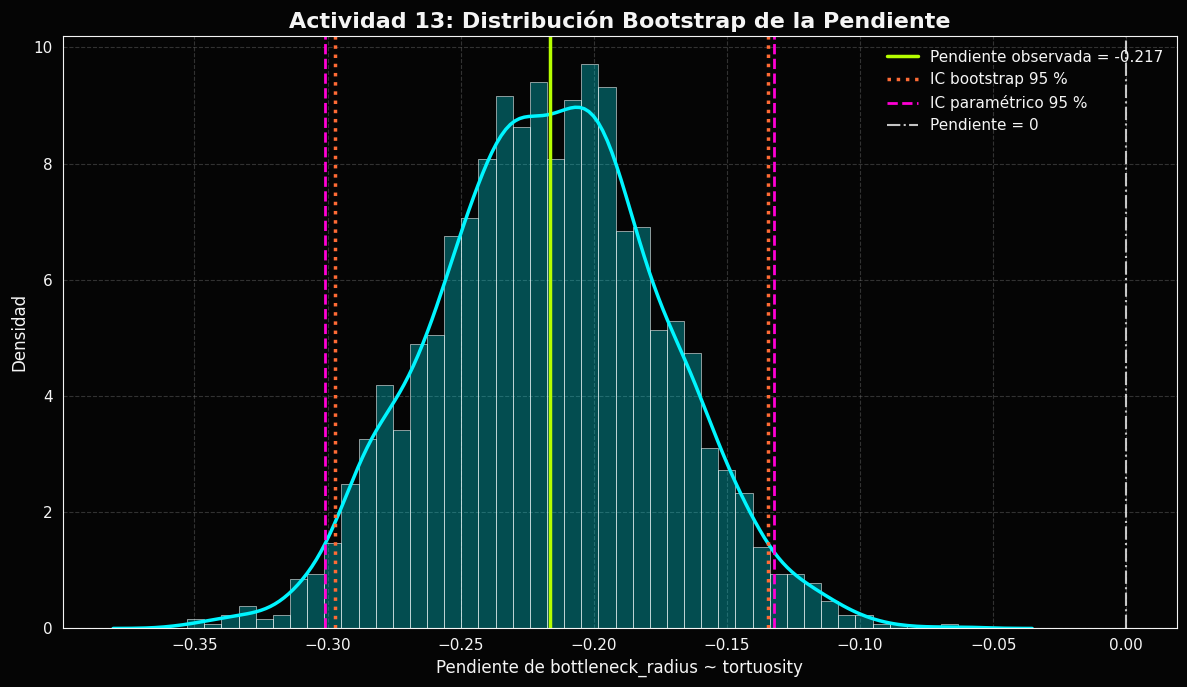


COMPARACIÓN DE LOS RESULTADOS
             Método  Estimación  IC inferior 95 %  IC superior 95 %
Pendiente observada   -0.216638               NaN               NaN
  Paramétrico (OLS)   -0.216638         -0.300956         -0.132320
Bootstrap percentil   -0.216978         -0.297124         -0.134629

EVALUACIÓN DE LA ESTABILIDAD
Anchura del IC bootstrap: 0.162495
Anchura del IC paramétrico: 0.168637
IC bootstrap contiene el cero: False
IC paramétrico contiene el cero: False
Proporción bootstrap con el mismo signo que la pendiente observada: 100.00%

Conclusión: la pendiente presenta estabilidad de signo en el bootstrap.
Concordancia: ambos métodos coinciden respecto a si el IC contiene el cero.


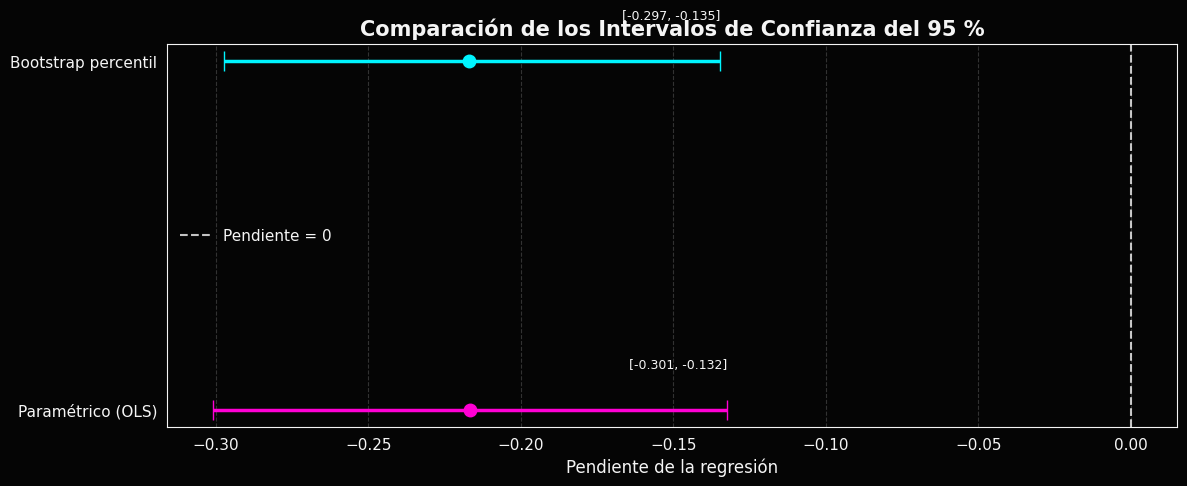

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from scipy.stats import norm

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})

# ============================================================
# 1. SELECCIÓN Y LIMPIEZA DE VARIABLES
# ============================================================

variables = [
    "bottleneck_radius",
    "tortuosity"
]

X_original = df_results[variables].copy()

X_original = X_original.apply(
    pd.to_numeric,
    errors="coerce"
)

X_original = X_original.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

if len(X_original) < 4:
    raise ValueError(
        "Se necesitan al menos 4 observaciones válidas."
    )

if any(
    X_original[col].nunique() < 2
    for col in variables
):
    raise ValueError(
        "Ambas variables deben presentar variabilidad."
    )

x = X_original["tortuosity"].to_numpy()
y = X_original["bottleneck_radius"].to_numpy()

n = len(X_original)

print("=" * 65)
print("ACTIVIDAD 13. ESTABILIDAD DE LA PENDIENTE")
print("=" * 65)

print("Modelo: bottleneck_radius ~ tortuosity")
print("Observaciones válidas:", n)

# ============================================================
# 2. MODELO DE REGRESIÓN ORIGINAL
# ============================================================

model_original = smf.ols(
    "bottleneck_radius ~ tortuosity",
    data=X_original
).fit()

pendiente_observada = model_original.params["tortuosity"]
intercepto_observado = model_original.params["Intercept"]

# Intervalo paramétrico de la pendiente
ic_parametrico = model_original.conf_int(alpha=0.05).loc[
    "tortuosity"
].to_numpy()

p_parametrico = model_original.pvalues["tortuosity"]
se_parametrico = model_original.bse["tortuosity"]

print("\n" + "=" * 65)
print("REGRESIÓN LINEAL ORIGINAL")
print("=" * 65)

print(model_original.summary())

print("\nPendiente observada:",
      f"{pendiente_observada:.6f}")

print("Error estándar paramétrico:",
      f"{se_parametrico:.6f}")

print("IC paramétrico del 95 %:",
      f"[{ic_parametrico[0]:.6f}, "
      f"{ic_parametrico[1]:.6f}]")

print("p-valor paramétrico:",
      f"{p_parametrico:.6e}")

# ============================================================
# 3. BOOTSTRAP DE LA PENDIENTE: 2000 RÉPLICAS
# ============================================================

n_bootstrap = 2000
rng = np.random.default_rng(42)

pendientes_bootstrap = np.full(
    n_bootstrap,
    np.nan
)

interceptos_bootstrap = np.full(
    n_bootstrap,
    np.nan
)

for i in range(n_bootstrap):

    # Remuestreo de filas completas con reemplazo.
    # Se conservan juntas las parejas (tortuosity, radius).
    indices = rng.integers(0, n, size=n)

    x_boot = x[indices]
    y_boot = y[indices]

    # La pendiente no está definida si tortuosity
    # es constante en la réplica.
    if np.var(x_boot) == 0:
        continue

    # Pendiente de regresión lineal:
    # b1 = Cov(x, y) / Var(x)
    pendiente_boot = np.sum(
        (x_boot - np.mean(x_boot)) *
        (y_boot - np.mean(y_boot))
    ) / np.sum(
        (x_boot - np.mean(x_boot)) ** 2
    )

    intercepto_boot = (
        np.mean(y_boot)
        - pendiente_boot * np.mean(x_boot)
    )

    pendientes_bootstrap[i] = pendiente_boot
    interceptos_bootstrap[i] = intercepto_boot

# Eliminar réplicas no válidas
pendientes_bootstrap = pendientes_bootstrap[
    np.isfinite(pendientes_bootstrap)
]

interceptos_bootstrap = interceptos_bootstrap[
    np.isfinite(interceptos_bootstrap)
]

if len(pendientes_bootstrap) < 0.95 * n_bootstrap:
    print(
        "\nAdvertencia: más del 5 % de las réplicas "
        "presentaron pendientes no definidas."
    )

if len(pendientes_bootstrap) < 100:
    raise ValueError(
        "Hay muy pocas réplicas válidas para estimar "
        "adecuadamente la distribución bootstrap."
    )

print("\n" + "=" * 65)
print("RESULTADOS DEL BOOTSTRAP")
print("=" * 65)

print("Réplicas solicitadas:", n_bootstrap)
print("Réplicas válidas:", len(pendientes_bootstrap))
print("Pendiente observada:",
      f"{pendiente_observada:.6f}")
print("Media bootstrap:",
      f"{np.mean(pendientes_bootstrap):.6f}")
print("Mediana bootstrap:",
      f"{np.median(pendientes_bootstrap):.6f}")
print("Desviación estándar bootstrap:",
      f"{np.std(pendientes_bootstrap, ddof=1):.6f}")

# ============================================================
# 4. INTERVALO DE CONFIANZA BOOTSTRAP DEL 95 %
#    MÉTODO PERCENTIL
# ============================================================

ic_bootstrap = np.percentile(
    pendientes_bootstrap,
    [2.5, 97.5]
)

print("\nIC bootstrap del 95 %:")
print(f"Inferior: {ic_bootstrap[0]:.6f}")
print(f"Superior: {ic_bootstrap[1]:.6f}")

# ============================================================
# 5. DISTRIBUCIÓN BOOTSTRAP DE LAS PENDIENTES
# ============================================================

fig1, ax1 = plt.subplots(figsize=(12, 7))
fig1.patch.set_facecolor(BLACK)

sns.histplot(
    pendientes_bootstrap,
    bins=45,
    stat="density",
    color=CYAN,
    alpha=0.30,
    edgecolor=WHITE,
    linewidth=0.4,
    ax=ax1
)

sns.kdeplot(
    pendientes_bootstrap,
    color=CYAN,
    linewidth=2.5,
    ax=ax1
)

# Pendiente observada
ax1.axvline(
    pendiente_observada,
    color=LIME,
    linestyle="-",
    linewidth=2.5,
    label=(
        f"Pendiente observada = "
        f"{pendiente_observada:.3f}"
    )
)

# Intervalo de confianza bootstrap
ax1.axvline(
    ic_bootstrap[0],
    color=ORANGE,
    linestyle=":",
    linewidth=2.5,
    label="IC bootstrap 95 %"
)

ax1.axvline(
    ic_bootstrap[1],
    color=ORANGE,
    linestyle=":",
    linewidth=2.5
)

# Intervalo de confianza paramétrico
ax1.axvline(
    ic_parametrico[0],
    color=MAGENTA,
    linestyle="--",
    linewidth=2,
    label="IC paramétrico 95 %"
)

ax1.axvline(
    ic_parametrico[1],
    color=MAGENTA,
    linestyle="--",
    linewidth=2
)

# Hipótesis de pendiente nula
ax1.axvline(
    0,
    color=WHITE,
    linestyle="-.",
    linewidth=1.5,
    alpha=0.8,
    label="Pendiente = 0"
)

ax1.set_title(
    "Actividad 13: Distribución Bootstrap de la Pendiente",
    color=WHITE,
    fontsize=16
)

ax1.set_xlabel(
    "Pendiente de bottleneck_radius ~ tortuosity",
    fontsize=12
)

ax1.set_ylabel(
    "Densidad",
    fontsize=12
)

ax1.tick_params(colors=WHITE, which="both")
ax1.set_facecolor(BLACK)
ax1.grid(True, linestyle="--", alpha=0.4)

ax1.legend(
    frameon=False,
    labelcolor=WHITE
)

for spine in ax1.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 6. COMPARACIÓN DE INTERVALOS DE CONFIANZA
# ============================================================

summary = pd.DataFrame({
    "Método": [
        "Pendiente observada",
        "Paramétrico (OLS)",
        "Bootstrap percentil"
    ],
    "Estimación": [
        pendiente_observada,
        pendiente_observada,
        np.mean(pendientes_bootstrap)
    ],
    "IC inferior 95 %": [
        np.nan,
        ic_parametrico[0],
        ic_bootstrap[0]
    ],
    "IC superior 95 %": [
        np.nan,
        ic_parametrico[1],
        ic_bootstrap[1]
    ]
})

print("\n" + "=" * 65)
print("COMPARACIÓN DE LOS RESULTADOS")
print("=" * 65)

print(summary.round(6).to_string(index=False))

# ============================================================
# 7. ESTABILIDAD Y PRESENCIA DEL CERO
# ============================================================

contiene_cero_bootstrap = (
    ic_bootstrap[0] <= 0 <= ic_bootstrap[1]
)

contiene_cero_parametrico = (
    ic_parametrico[0] <= 0 <= ic_parametrico[1]
)

width_bootstrap = (
    ic_bootstrap[1] - ic_bootstrap[0]
)

width_parametrico = (
    ic_parametrico[1] - ic_parametrico[0]
)

# Proporción de pendientes con el mismo signo
# que la pendiente observada.
if pendiente_observada > 0:
    proporcion_mismo_signo = np.mean(
        pendientes_bootstrap > 0
    )
elif pendiente_observada < 0:
    proporcion_mismo_signo = np.mean(
        pendientes_bootstrap < 0
    )
else:
    proporcion_mismo_signo = np.nan

print("\n" + "=" * 65)
print("EVALUACIÓN DE LA ESTABILIDAD")
print("=" * 65)

print("Anchura del IC bootstrap:",
      f"{width_bootstrap:.6f}")

print("Anchura del IC paramétrico:",
      f"{width_parametrico:.6f}")

print("IC bootstrap contiene el cero:",
      contiene_cero_bootstrap)

print("IC paramétrico contiene el cero:",
      contiene_cero_parametrico)

print(
    "Proporción bootstrap con el mismo signo "
    "que la pendiente observada:",
    f"{proporcion_mismo_signo:.2%}"
)

# Criterio operativo de estabilidad del signo.
# No equivale a demostrar estabilidad absoluta.
if (
    not contiene_cero_bootstrap
    and proporcion_mismo_signo >= 0.95
):
    print(
        "\nConclusión: la pendiente presenta "
        "estabilidad de signo en el bootstrap."
    )
elif (
    contiene_cero_bootstrap
    or proporcion_mismo_signo < 0.95
):
    print(
        "\nConclusión: la estabilidad del signo "
        "de la pendiente es limitada o incierta."
    )

# Comparación de inferencias
if (
    contiene_cero_bootstrap
    == contiene_cero_parametrico
):
    print(
        "Concordancia: ambos métodos coinciden "
        "respecto a si el IC contiene el cero."
    )
else:
    print(
        "Discordancia: los métodos difieren "
        "respecto a si el IC contiene el cero."
    )

# ============================================================
# 8. GRÁFICO DE COMPARACIÓN DE INTERVALOS
# ============================================================

fig2, ax2 = plt.subplots(figsize=(12, 5))
fig2.patch.set_facecolor(BLACK)

metodos = [
    "Bootstrap percentil",
    "Paramétrico (OLS)"
]

estimaciones = [
    np.mean(pendientes_bootstrap),
    pendiente_observada
]

intervalos = [
    ic_bootstrap,
    ic_parametrico
]

colores = [CYAN, MAGENTA]
posiciones = [1, 0]

for i in range(2):

    estimacion = estimaciones[i]
    inferior, superior = intervalos[i]

    ax2.errorbar(
        estimacion,
        posiciones[i],
        xerr=[[
            estimacion - inferior
        ], [
            superior - estimacion
        ]],
        fmt="o",
        color=colores[i],
        ecolor=colores[i],
        elinewidth=2.5,
        capsize=7,
        markersize=9
    )

    ax2.text(
        superior,
        posiciones[i] + 0.12,
        f"[{inferior:.3f}, {superior:.3f}]",
        color=WHITE,
        fontsize=9,
        ha="right"
    )

ax2.axvline(
    0,
    color=WHITE,
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="Pendiente = 0"
)

ax2.set_yticks(posiciones)
ax2.set_yticklabels(metodos, color=WHITE)

ax2.set_title(
    "Comparación de los Intervalos de Confianza del 95 %",
    color=WHITE,
    fontsize=15
)

ax2.set_xlabel(
    "Pendiente de la regresión",
    color=WHITE,
    fontsize=12
)

ax2.tick_params(colors=WHITE, which="both")
ax2.set_facecolor(BLACK)
ax2.grid(True, axis="x", linestyle="--", alpha=0.4)
ax2.legend(frameon=False, labelcolor=WHITE)

for spine in ax2.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 9. RESTABLECER ESTILO
# ============================================================

plt.style.use("default")

### Preguntas

**1. ¿La pendiente es estable?**

La pendiente observada entre las dos variables fue de -0,2166 con un IC 95% paramétrico de [-0,301, -0,132], mientras que por boostrap se obtuvo una media de -0,217 con un IC95% [-0,297, -0,135], lo que indica estabilidad del valor al tener la misma incertidumbre (con una distribución bootstrap simétrica y centrada por la media). Las anchuras del IC bootstrap y paramétrico fueron de 0,162 y 0,169 reforzando la idea de estabilidad en valor y signo.

**2. ¿El intervalo contiene el valor cero?**

Ningun intervalo contiene al valor 0. Existe evidencia estadística de una asociación lineal negativa entre la tortuosidad y el radio del cuello de botella al nivel de significación del 5 %.

**3. ¿El resultado coincide con la inferencia paramétrica?**

Sí, el resultado bootstrap coincide y se superpone con el IC 95% del paramétrico.

**4. ¿Qué interpretación biológica darían?**

Esto solo asegura la fiabilidad estadística de la pendiente de la regresión lineal entre radio_cuello_botella y tortuosidad, pero hay que recordar que el r_pearson es muy bajo entre estas dos variables y el R^2 ajustado de 0,023 indica que el modelo explica una proporción muy pequeña de la variabilidad observada en el radio del cuello de botella.

Por tanto, existe una asociación lineal negativa estadísticamente detectable, pero su capacidad para explicar o predecir las variaciones de bottleneck_radius a partir de tortuosity es limitada. Esto sugiere que la tortuosidad, considerada de forma aislada, no constituye un predictor suficientemente informativo del radio del cuello de botella en este conjunto de datos.

---

# PARTE XIII — EL PROBLEMA DEL BOOTSTRAP

## Actividad 14. ¿Podemos remuestrear frames libremente?

Hasta este momento hemos tratado los frames como observaciones.

Pero recordemos que:

> Los frames consecutivos pertenecen a una misma trayectoria temporal.

Por lo tanto, pueden estar correlacionados.

### Preguntas

**a.** ¿Qué supuesto del bootstrap convencional puede verse comprometido?

**b.** ¿Qué ocurre si los frames 100, 101, 102 y 103 contienen información muy similar?

**c.** ¿Estamos obteniendo realmente 1055 unidades independientes de información?

**d.** ¿Qué problema puede producir esto en los intervalos de confianza y p-values?

Investigar conceptualmente el **block bootstrap**.

No es necesario implementarlo si no se dispone de tiempo, pero deberán explicar:

> ¿Por qué podría ser más apropiado para este tipo de datos?


#### Respuestas

a - El supuesto de independencia entre las observaciones. El bootstrap convencional por pares remuestrea filas individuales con reemplazo, como si cada observación aportara información independiente. Sin embargo, en una trayectoria temporal, la estructura de una observación puede depender de los frames anteriores o posteriores.

b - Esos frames aportan información parcialmente redundante. Si representan una misma configuración estructural que cambia lentamente, no equivalen a cuatro observaciones independientes. Remuestrearlos por separado puede romper la dependencia temporal y hacer que el tamaño efectivo de la muestra sea menor que el número total de frames.

c - No necesariamente. Tener 1055 frames no significa disponer de 1055 unidades independientes de información. El número efectivo de observaciones depende de la intensidad y duración de la autocorrelación temporal, entre otros factores. Además, de que en ciertos intervalos de frames pueden ocurrir eventos atípicos biológicamente válidos que generen asimetrías si no se estudian correctamente y los cuales pueden observarse o no según el tiempo de simulación total : pueden concluirse que no hay dichos eventos en un diseño de simulación corta o con técnicas de simulación que no permiten observarlos con facilidad. Similarmente existen cambios estructurales que pueden ser periódicos y que dan lugar a intervalos que deberían de estudiarse por segmentación y no en conjunto.

d - Si existe dependencia temporal positiva y se ignora, los errores estándar pueden quedar subestimados, los intervalos de confianza pueden resultar demasiado estrechos y los p-values pueden ser demasiado pequeños. Esto aumenta el riesgo de detectar asociaciones estadísticamente significativas que no están respaldadas por tanta información independiente como aparenta el tamaño de la muestra. No obstante, la dirección y magnitud del error dependen de la estructura de dependencia y del estadístico analizado.


### Sobre el Block Bootstrap:

En lugar de seleccionar frames individuales, se seleccionan bloques de frames consecutivos. Así se conserva parte de la estructura temporal dentro de cada bloque : O sea, en vez de analizar todo, se trata de sectorizar que partes podrian dar algo diferente y autocorrelacionable.

El block bootstrap no elimina la autocorrelación, pero permite preservarla parcialmente. Su efectividad depende de elegir un tamaño de bloque apropiado: bloques demasiado pequeños pierden dependencia temporal y bloques demasiado grandes reducen la cantidad de bloques distintos disponibles.

ACTIVIDAD 14: BOOTSTRAP TEMPORAL POR BLOQUES
Número de frames: 1055
Modelo: bottleneck_radius ~ tortuosity

REGRESIÓN ORIGINAL
Pendiente: -0.216638
IC paramétrico 95 %: [-0.300956, -0.132320]
p-valor paramétrico: 5.434908e-07
R²: 0.023569

CONFIGURACIÓN
Réplicas: 2000
Longitud inicial del bloque: 10

COMPARACIÓN DE MÉTODOS
                Método  Pendiente media  IC inferior 95 %  IC superior 95 %  Anchura IC
    Pendiente original        -0.216638               NaN               NaN         NaN
Bootstrap convencional        -0.216978         -0.297124         -0.134629    0.162495
       Block bootstrap        -0.216815         -0.300630         -0.127870    0.172760

Réplicas convencionales: 2000
Réplicas por bloques: 2000

INFERENCIA
IC paramétrico contiene cero: False
IC convencional contiene cero: False
IC por bloques contiene cero: False

Anchura bootstrap convencional: 0.162495
Anchura block bootstrap: 0.172760
Ambos bootstraps coinciden respecto a la inclusión del cero.
El inte

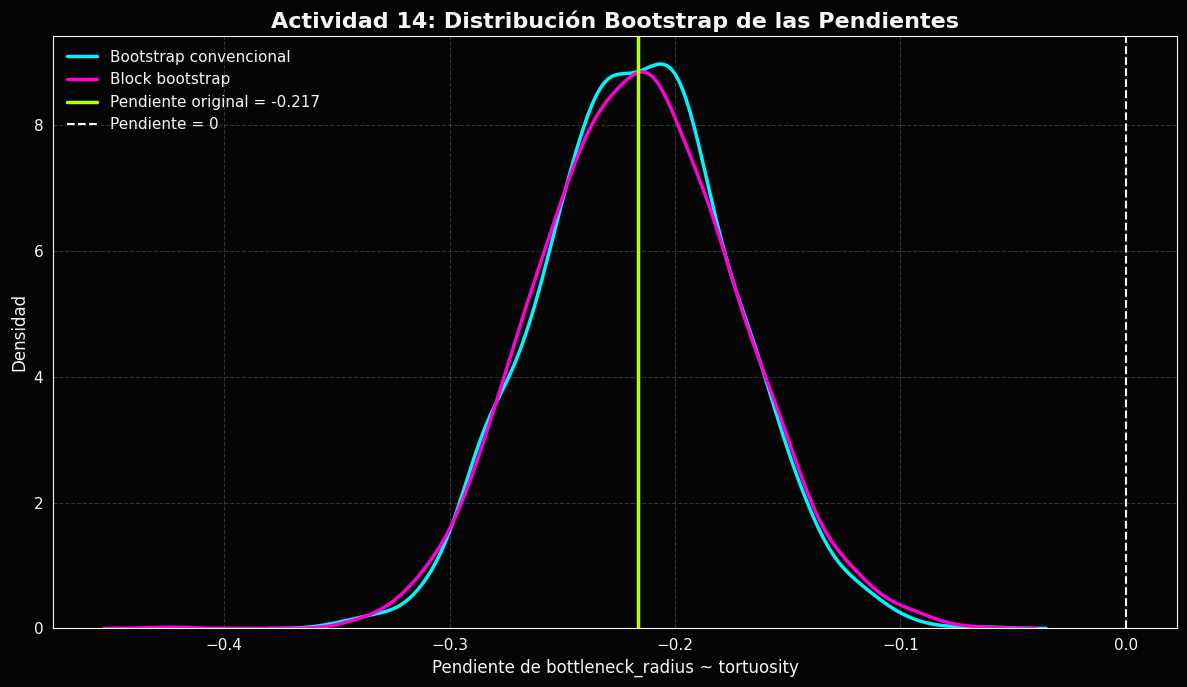

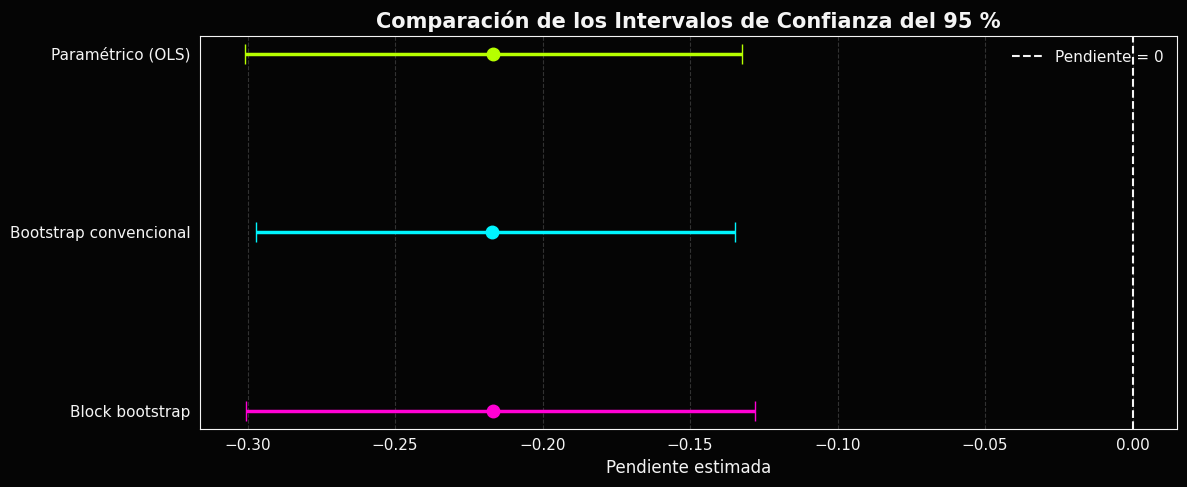


SENSIBILIDAD AL TAMAÑO DEL BLOQUE
 Longitud bloque  Pendiente media  IC inferior 95 %  IC superior 95 %  Anchura IC
               6        -0.217748         -0.301791         -0.126956    0.174835
              10        -0.218562         -0.303792         -0.133746    0.170045
              32        -0.216574         -0.289410         -0.146528    0.142881


In [ ]:
# Supuesto importante: el código considera que las filas de df_results están ordenadas cronológicamente y pertenecen a una misma trayectoria.
# Si corresponden a varias trayectorias, hay que adaptar el remuestreo para no crear bloques que crucen de una trayectoria a otra.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})

# ============================================================
# 1. SELECCIÓN Y VALIDACIÓN DE LOS DATOS
# ============================================================

variables = [
    "bottleneck_radius",
    "tortuosity"
]

X_original = df_results[variables].copy()

X_original = X_original.apply(
    pd.to_numeric,
    errors="coerce"
)

X_original = X_original.replace(
    [np.inf, -np.inf],
    np.nan
)

# No eliminar filas automáticamente: hacerlo podría unir
# frames que originalmente no eran consecutivos.
if X_original.isna().any().any():
    raise ValueError(
        "Hay valores ausentes o no válidos. Antes del "
        "bootstrap, revisa esos frames y conserva la "
        "estructura temporal original."
    )

if any(X_original[col].nunique() < 2 for col in variables):
    raise ValueError(
        "Ambas variables deben presentar variabilidad."
    )

# Se presupone que el orden actual de las filas es temporal.
x = X_original["tortuosity"].to_numpy()
y = X_original["bottleneck_radius"].to_numpy()

n = len(X_original)

print("=" * 70)
print("ACTIVIDAD 14: BOOTSTRAP TEMPORAL POR BLOQUES")
print("=" * 70)

print("Número de frames:", n)
print("Modelo: bottleneck_radius ~ tortuosity")

# ============================================================
# 2. MODELO ORIGINAL
# ============================================================

model_original = smf.ols(
    "bottleneck_radius ~ tortuosity",
    data=X_original
).fit()

pendiente_original = model_original.params["tortuosity"]

ic_parametrico = model_original.conf_int(
    alpha=0.05
).loc["tortuosity"].to_numpy()

p_parametrico = model_original.pvalues["tortuosity"]

print("\nREGRESIÓN ORIGINAL")
print(f"Pendiente: {pendiente_original:.6f}")
print(
    f"IC paramétrico 95 %: "
    f"[{ic_parametrico[0]:.6f}, "
    f"{ic_parametrico[1]:.6f}]"
)
print(f"p-valor paramétrico: {p_parametrico:.6e}")
print(f"R²: {model_original.rsquared:.6f}")

# ============================================================
# 3. CONFIGURACIÓN DE LOS BOOTSTRAPS
# ============================================================

n_bootstrap = 2000
rng = np.random.default_rng(42)

# Regla heurística inicial.
# Debe comprobarse la sensibilidad a otros tamaños.
block_length = max(2, round(n ** (1 / 3)))

if block_length >= n:
    raise ValueError(
        "El tamaño de bloque debe ser menor que n."
    )

print("\nCONFIGURACIÓN")
print("Réplicas:", n_bootstrap)
print("Longitud inicial del bloque:", block_length)

# ============================================================
# 4. FUNCIÓN PARA CALCULAR LA PENDIENTE
# ============================================================

def calcular_pendiente(x_sample, y_sample):

    x_centered = x_sample - np.mean(x_sample)
    y_centered = y_sample - np.mean(y_sample)

    denominador = np.sum(x_centered ** 2)

    if denominador <= 0:
        return np.nan

    return np.sum(
        x_centered * y_centered
    ) / denominador


# ============================================================
# 5. BOOTSTRAP CONVENCIONAL POR PARES
# ============================================================

pendientes_convencional = np.full(
    n_bootstrap,
    np.nan
)

for i in range(n_bootstrap):

    # Selección individual de frames con reemplazo.
    indices = rng.integers(0, n, size=n)

    x_boot = x[indices]
    y_boot = y[indices]

    pendientes_convencional[i] = calcular_pendiente(
        x_boot,
        y_boot
    )

pendientes_convencional = pendientes_convencional[
    np.isfinite(pendientes_convencional)
]

# ============================================================
# 6. BLOCK BOOTSTRAP: BLOQUES MÓVILES
# ============================================================

# Se construyen bloques solapados de frames consecutivos.
# Cada bloque contiene las parejas (tortuosity, radius).

bloques_x = np.array([
    x[i:i + block_length]
    for i in range(n - block_length + 1)
])

bloques_y = np.array([
    y[i:i + block_length]
    for i in range(n - block_length + 1)
])

n_bloques_necesarios = int(
    np.ceil(n / block_length)
)

pendientes_block = np.full(
    n_bootstrap,
    np.nan
)

for i in range(n_bootstrap):

    # Elegir bloques completos con reemplazo.
    indices_bloques = rng.integers(
        0,
        len(bloques_x),
        size=n_bloques_necesarios
    )

    x_boot = np.concatenate(
        bloques_x[indices_bloques]
    )[:n]

    y_boot = np.concatenate(
        bloques_y[indices_bloques]
    )[:n]

    pendientes_block[i] = calcular_pendiente(
        x_boot,
        y_boot
    )

pendientes_block = pendientes_block[
    np.isfinite(pendientes_block)
]

if (
    len(pendientes_convencional) < 0.95 * n_bootstrap
    or len(pendientes_block) < 0.95 * n_bootstrap
):
    print(
        "\nAdvertencia: más del 5 % de las réplicas "
        "de al menos un método no fueron válidas."
    )

# ============================================================
# 7. INTERVALOS DE CONFIANZA DEL 95 %
# ============================================================

ic_convencional = np.percentile(
    pendientes_convencional,
    [2.5, 97.5]
)

ic_block = np.percentile(
    pendientes_block,
    [2.5, 97.5]
)

# ============================================================
# 8. RESUMEN DE RESULTADOS
# ============================================================

summary = pd.DataFrame({
    "Método": [
        "Pendiente original",
        "Bootstrap convencional",
        "Block bootstrap"
    ],
    "Pendiente media": [
        pendiente_original,
        np.mean(pendientes_convencional),
        np.mean(pendientes_block)
    ],
    "IC inferior 95 %": [
        np.nan,
        ic_convencional[0],
        ic_block[0]
    ],
    "IC superior 95 %": [
        np.nan,
        ic_convencional[1],
        ic_block[1]
    ],
    "Anchura IC": [
        np.nan,
        ic_convencional[1] - ic_convencional[0],
        ic_block[1] - ic_block[0]
    ]
})

print("\n" + "=" * 70)
print("COMPARACIÓN DE MÉTODOS")
print("=" * 70)

print(summary.round(6).to_string(index=False))

print("\nRéplicas convencionales:", len(pendientes_convencional))
print("Réplicas por bloques:", len(pendientes_block))

# ============================================================
# 9. ¿LOS INTERVALOS CONTIENEN EL CERO?
# ============================================================

cero_convencional = (
    ic_convencional[0] <= 0 <= ic_convencional[1]
)

cero_block = (
    ic_block[0] <= 0 <= ic_block[1]
)

cero_parametrico = (
    ic_parametrico[0] <= 0 <= ic_parametrico[1]
)

print("\n" + "=" * 70)
print("INFERENCIA")
print("=" * 70)

print("IC paramétrico contiene cero:", cero_parametrico)
print("IC convencional contiene cero:", cero_convencional)
print("IC por bloques contiene cero:", cero_block)

print(
    "\nAnchura bootstrap convencional:",
    f"{ic_convencional[1] - ic_convencional[0]:.6f}"
)

print(
    "Anchura block bootstrap:",
    f"{ic_block[1] - ic_block[0]:.6f}"
)

if cero_convencional == cero_block:
    print(
        "Ambos bootstraps coinciden respecto a la "
        "inclusión del cero."
    )
else:
    print(
        "Los bootstraps difieren respecto a la "
        "inclusión del cero."
    )

if not cero_block:
    print(
        "El intervalo por bloques excluye cero: "
        "la pendiente es distinta de cero según "
        "el IC bootstrap utilizado."
    )
else:
    print(
        "El intervalo por bloques contiene cero: "
        "no se descarta una pendiente nula mediante "
        "este intervalo."
    )

# ============================================================
# 10. DISTRIBUCIÓN DE PENDIENTES
# ============================================================

fig1, ax1 = plt.subplots(figsize=(12, 7))
fig1.patch.set_facecolor(BLACK)

sns.kdeplot(
    pendientes_convencional,
    color=CYAN,
    linewidth=2.5,
    label="Bootstrap convencional",
    ax=ax1
)

sns.kdeplot(
    pendientes_block,
    color=MAGENTA,
    linewidth=2.5,
    label="Block bootstrap",
    ax=ax1
)

ax1.axvline(
    pendiente_original,
    color=LIME,
    linestyle="-",
    linewidth=2.5,
    label=f"Pendiente original = {pendiente_original:.3f}"
)

ax1.axvline(
    0,
    color=WHITE,
    linestyle="--",
    linewidth=1.5,
    label="Pendiente = 0"
)

ax1.set_title(
    "Actividad 14: Distribución Bootstrap de las Pendientes",
    color=WHITE,
    fontsize=16
)

ax1.set_xlabel(
    "Pendiente de bottleneck_radius ~ tortuosity",
    fontsize=12
)

ax1.set_ylabel("Densidad", fontsize=12)

ax1.set_facecolor(BLACK)
ax1.tick_params(colors=WHITE)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, labelcolor=WHITE)

for spine in ax1.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 11. COMPARACIÓN GRÁFICA DE LOS INTERVALOS
# ============================================================

fig2, ax2 = plt.subplots(figsize=(12, 5))
fig2.patch.set_facecolor(BLACK)

metodos = [
    "Paramétrico (OLS)",
    "Bootstrap convencional",
    "Block bootstrap"
]

estimaciones = [
    pendiente_original,
    np.mean(pendientes_convencional),
    np.mean(pendientes_block)
]

intervalos = [
    ic_parametrico,
    ic_convencional,
    ic_block
]

colores = [LIME, CYAN, MAGENTA]
posiciones = [2, 1, 0]

for i in range(3):

    estimacion = estimaciones[i]
    inferior, superior = intervalos[i]

    ax2.errorbar(
        estimacion,
        posiciones[i],
        xerr=[[
            estimacion - inferior
        ], [
            superior - estimacion
        ]],
        fmt="o",
        color=colores[i],
        ecolor=colores[i],
        elinewidth=2.5,
        capsize=7,
        markersize=9
    )

ax2.axvline(
    0,
    color=WHITE,
    linestyle="--",
    linewidth=1.5,
    label="Pendiente = 0"
)

ax2.set_yticks(posiciones)
ax2.set_yticklabels(metodos, color=WHITE)

ax2.set_title(
    "Comparación de los Intervalos de Confianza del 95 %",
    color=WHITE,
    fontsize=15
)

ax2.set_xlabel("Pendiente estimada", fontsize=12)
ax2.tick_params(colors=WHITE)
ax2.grid(True, axis="x", linestyle="--", alpha=0.4)
ax2.legend(frameon=False, labelcolor=WHITE)

for spine in ax2.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 12. SENSIBILIDAD AL TAMAÑO DEL BLOQUE
# ============================================================

# La longitud del bloque influye en la incertidumbre.
# Se comparan tamaños alternativos como diagnóstico.

longitudes = sorted(set([
    max(2, round(n ** (1 / 4))),
    max(2, round(n ** (1 / 3))),
    max(2, round(n ** (1 / 2)))
]))

longitudes = [
    L for L in longitudes if L < n
]

resultados_longitud = []

for L in longitudes:

    bx = np.array([
        x[j:j + L]
        for j in range(n - L + 1)
    ])

    by = np.array([
        y[j:j + L]
        for j in range(n - L + 1)
    ])

    n_blocks = int(np.ceil(n / L))
    pendientes_L = []

    for _ in range(n_bootstrap):

        idx = rng.integers(
            0,
            len(bx),
            size=n_blocks
        )

        xb = np.concatenate(bx[idx])[:n]
        yb = np.concatenate(by[idx])[:n]

        pendiente = calcular_pendiente(xb, yb)

        if np.isfinite(pendiente):
            pendientes_L.append(pendiente)

    pendientes_L = np.asarray(pendientes_L)

    if len(pendientes_L) > 0:

        ic_L = np.percentile(
            pendientes_L,
            [2.5, 97.5]
        )

        resultados_longitud.append({
            "Longitud bloque": L,
            "Pendiente media": np.mean(pendientes_L),
            "IC inferior 95 %": ic_L[0],
            "IC superior 95 %": ic_L[1],
            "Anchura IC": ic_L[1] - ic_L[0]
        })

print("\n" + "=" * 70)
print("SENSIBILIDAD AL TAMAÑO DEL BLOQUE")
print("=" * 70)

print(
    pd.DataFrame(resultados_longitud)
    .round(6)
    .to_string(index=False)
)

# ============================================================
# 13. RESTABLECER ESTILO
# ============================================================

plt.style.use("default")

Segmento 1: filas 0 a 199; n = 200; tortuosidad media = 2.0794
Segmento 2: filas 200 a 799; n = 600; tortuosidad media = 1.9628
Segmento 3: filas 800 a 1054; n = 255; tortuosidad media = 1.9260

Longitud inicial de bloque: 10

BLOCK BOOTSTRAP POR SEGMENTOS
Réplicas válidas: 2000
Pendiente original: -0.216638
Pendiente media bootstrap: -0.230875
IC bootstrap 95 %: [-0.314695, -0.146086]
Anchura del intervalo: 0.168609
El intervalo contiene cero: False


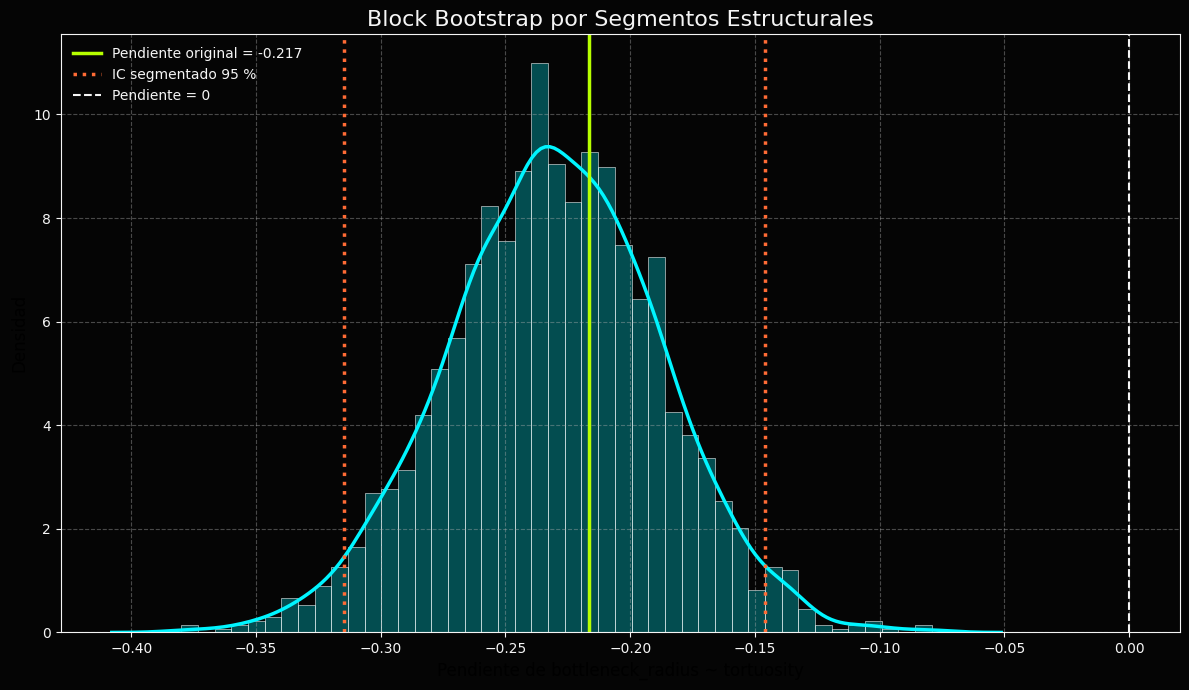


COMPARACIÓN FINAL
                    Método  IC inferior  IC superior  Anchura IC
           Paramétrico OLS    -0.300956    -0.132320    0.168637
    Bootstrap convencional    -0.297124    -0.134629    0.162495
    Block bootstrap global    -0.300630    -0.127870    0.172760
Block bootstrap segmentado    -0.314695    -0.146086    0.168609


In [ ]:
# ============================================================
# BLOCK BOOTSTRAP POR SEGMENTOS ESTRUCTURALES
# ============================================================

# IMPORTANTE:
# Se supone que las filas de df_results están ordenadas
# cronológicamente y que los cambios ocurren en las
# posiciones 200 y 800 (índices Python, base cero).
#
# Segmento 1: filas [0, 200)
# Segmento 2: filas [200, 800)
# Segmento 3: filas [800, n)
#
# Ajustar estos límites si los frames identifican números
# de frame reales y no posiciones de fila.

cortes = [0, 200, 800, n]

if n <= 800:
    raise ValueError(
        "Se necesitan más de 800 filas para utilizar "
        "los tres segmentos definidos. Ajusta los cortes "
        "a la longitud real de la trayectoria."
    )

segmentos = []

for i in range(len(cortes) - 1):

    inicio = cortes[i]
    fin = cortes[i + 1]

    segmento = X_original.iloc[inicio:fin].copy()

    if len(segmento) < 2:
        raise ValueError(
            f"El segmento {i + 1} tiene muy pocas filas."
        )

    segmentos.append(segmento)

    print(
        f"Segmento {i + 1}: filas {inicio} a {fin - 1}; "
        f"n = {len(segmento)}; "
        f"tortuosidad media = "
        f"{segmento['tortuosity'].mean():.4f}"
    )

# ============================================================
# LONGITUD DE BLOQUE
# ============================================================

# Elección inicial; evaluar también otras longitudes.
block_length = max(2, round(n ** (1 / 3)))

print("\nLongitud inicial de bloque:", block_length)

# Comprobar que cada segmento permita construir bloques
# móviles de la longitud elegida.
for i, segmento in enumerate(segmentos):

    if len(segmento) < block_length:
        raise ValueError(
            f"El segmento {i + 1} es más corto que el "
            "bloque elegido. Reduce block_length."
        )

# ============================================================
# FUNCIÓN DE REMUESTREO POR BLOQUES MÓVILES
# ============================================================

def remuestrear_segmento(segmento, L, rng):

    datos = segmento[
        ["tortuosity", "bottleneck_radius"]
    ].to_numpy()

    n_segmento = len(datos)

    # Todos los bloques consecutivos posibles.
    bloques = np.array([
        datos[j:j + L]
        for j in range(n_segmento - L + 1)
    ])

    # Elegir bloques con reemplazo hasta alcanzar
    # el tamaño original del segmento.
    numero_bloques = int(np.ceil(n_segmento / L))

    indices = rng.integers(
        0,
        len(bloques),
        size=numero_bloques
    )

    muestra = np.concatenate(
        bloques[indices],
        axis=0
    )[:n_segmento]

    return muestra

# ============================================================
# BOOTSTRAP POR SEGMENTOS
# ============================================================

n_bootstrap = 2000
rng = np.random.default_rng(42)

pendientes_segmentadas = np.full(
    n_bootstrap,
    np.nan
)

for b in range(n_bootstrap):

    muestras = []

    # Remuestrear dentro de cada segmento por separado.
    for segmento in segmentos:

        muestra_segmento = remuestrear_segmento(
            segmento,
            block_length,
            rng
        )

        muestras.append(muestra_segmento)

    # Combinar los tres segmentos manteniendo sus tamaños.
    muestra_total = np.vstack(muestras)

    x_boot = muestra_total[:, 0]
    y_boot = muestra_total[:, 1]

    var_x = np.sum(
        (x_boot - np.mean(x_boot)) ** 2
    )

    if var_x == 0:
        continue

    pendientes_segmentadas[b] = np.sum(
        (x_boot - np.mean(x_boot)) *
        (y_boot - np.mean(y_boot))
    ) / var_x

pendientes_segmentadas = pendientes_segmentadas[
    np.isfinite(pendientes_segmentadas)
]

if len(pendientes_segmentadas) < 0.95 * n_bootstrap:
    print(
        "Advertencia: más del 5 % de las réplicas "
        "no produjo una pendiente válida."
    )

# ============================================================
# INTERVALO DE CONFIANZA DEL 95 %
# ============================================================

ic_segmentado = np.percentile(
    pendientes_segmentadas,
    [2.5, 97.5]
)

pendiente_media_segmentada = np.mean(
    pendientes_segmentadas
)

anchura_ic_segmentado = (
    ic_segmentado[1] - ic_segmentado[0]
)

print("\n" + "=" * 65)
print("BLOCK BOOTSTRAP POR SEGMENTOS")
print("=" * 65)

print("Réplicas válidas:", len(pendientes_segmentadas))
print(
    f"Pendiente original: {pendiente_original:.6f}"
)
print(
    f"Pendiente media bootstrap: "
    f"{pendiente_media_segmentada:.6f}"
)
print(
    f"IC bootstrap 95 %: "
    f"[{ic_segmentado[0]:.6f}, "
    f"{ic_segmentado[1]:.6f}]"
)
print(
    f"Anchura del intervalo: "
    f"{anchura_ic_segmentado:.6f}"
)

contiene_cero_segmentado = (
    ic_segmentado[0] <= 0 <= ic_segmentado[1]
)

print(
    "El intervalo contiene cero:",
    contiene_cero_segmentado
)

# ============================================================
# DISTRIBUCIÓN BLACK NEON
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(BLACK)

sns.histplot(
    pendientes_segmentadas,
    bins=45,
    stat="density",
    color=CYAN,
    alpha=0.30,
    edgecolor=WHITE,
    linewidth=0.4,
    ax=ax
)

sns.kdeplot(
    pendientes_segmentadas,
    color=CYAN,
    linewidth=2.5,
    ax=ax
)

ax.axvline(
    pendiente_original,
    color=LIME,
    linewidth=2.5,
    label=f"Pendiente original = {pendiente_original:.3f}"
)

ax.axvline(
    ic_segmentado[0],
    color=ORANGE,
    linestyle=":",
    linewidth=2.5,
    label="IC segmentado 95 %"
)

ax.axvline(
    ic_segmentado[1],
    color=ORANGE,
    linestyle=":",
    linewidth=2.5
)

ax.axvline(
    0,
    color=WHITE,
    linestyle="--",
    linewidth=1.5,
    label="Pendiente = 0"
)

ax.set_title(
    "Block Bootstrap por Segmentos Estructurales",
    color=WHITE,
    fontsize=16
)

ax.set_xlabel(
    "Pendiente de bottleneck_radius ~ tortuosity",
    fontsize=12
)

ax.set_ylabel("Densidad", fontsize=12)
ax.set_facecolor(BLACK)
ax.tick_params(colors=WHITE)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(frameon=False, labelcolor=WHITE)

for spine in ax.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# COMPARACIÓN CON LOS MÉTODOS ANTERIORES
# ============================================================

# Se presupone que el código anterior ya calculó:
# ic_parametrico, ic_convencional e ic_block.

comparacion = pd.DataFrame({
    "Método": [
        "Paramétrico OLS",
        "Bootstrap convencional",
        "Block bootstrap global",
        "Block bootstrap segmentado"
    ],
    "IC inferior": [
        ic_parametrico[0],
        ic_convencional[0],
        ic_block[0],
        ic_segmentado[0]
    ],
    "IC superior": [
        ic_parametrico[1],
        ic_convencional[1],
        ic_block[1],
        ic_segmentado[1]
    ]
})

comparacion["Anchura IC"] = (
    comparacion["IC superior"]
    - comparacion["IC inferior"]
)

print("\nCOMPARACIÓN FINAL")
print(comparacion.round(6).to_string(index=False))

plt.style.use("default")

En todos los diferentes boostraps realizados se superponen al paramétrico realizado con sus IC 95%.

---

# PARTE XIV — PRUEBA DE PERMUTACIÓN

## Actividad 15. ¿Los estados presentan diferentes propiedades?

Seleccionar dos grupos o clusters obtenidos previamente.

Comparar el:

```text
bottleneck_radius
```

entre ambos grupos.

Utilizar una prueba de permutación.

Por ejemplo:

> diferencia de medias entre grupos.

### Procedimiento conceptual

1. Calcular la diferencia observada.
2. Permutar las etiquetas de los grupos.
3. Recalcular la diferencia.
4. Repetir muchas veces.
5. Construir la distribución nula.
6. Comparar el valor observado con la distribución.

### Preguntas

1. ¿Existe evidencia de diferencia entre los grupos?
2. ¿Qué supuesto permite realizar la permutación?
3. ¿La dependencia temporal vuelve problemática esta prueba?

### Notas:

El objetivo es determinar si dos estados o clusters identificados previamente presentan diferencias en el bottleneck_radius.

La hipótesis será:

* H0​: no existe diferencia entre las medias de bottleneck_radius de los dos grupos.
* H1​: existe una diferencia entre las medias de los dos grupos.


El resultado principal es el p-valor bilateral de la prueba de permutación:

* Si p<0,05, existe evidencia estadística de una diferencia entre las medias, si se cumplen los supuestos de la prueba.

* p≥0,05, no hay evidencia suficiente para rechazar la hipótesis nula.

La diferencia observada es:
Δobs=xˉA−xˉB

Si es positiva, el grupo A presenta un radio medio mayor. Si es negativa, el grupo B presenta un radio medio mayor.


ACTIVIDAD 15: PRUEBA DE PERMUTACIÓN
Grupo A: 0
Grupo B: 1
n(A) = 428
n(B) = 627

Media A: 0.271589
Media B: 0.334608
Diferencia observada (A - B): -0.063019

RESULTADOS: PERMUTACIÓN CONVENCIONAL
Permutaciones: 10000
p-valor bilateral: 0.000100
Resultado: existe evidencia estadística de una diferencia entre las medias bajo los supuestos de la prueba.


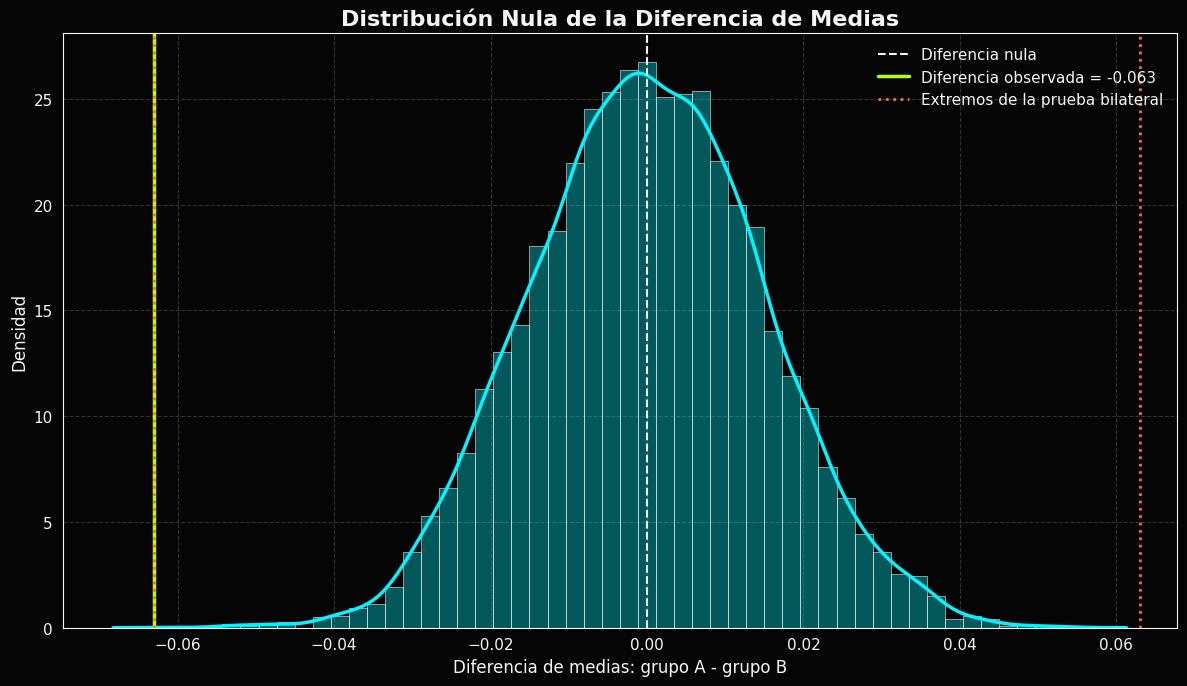

/tmp/ipykernel_2194/1905016541.py:282: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


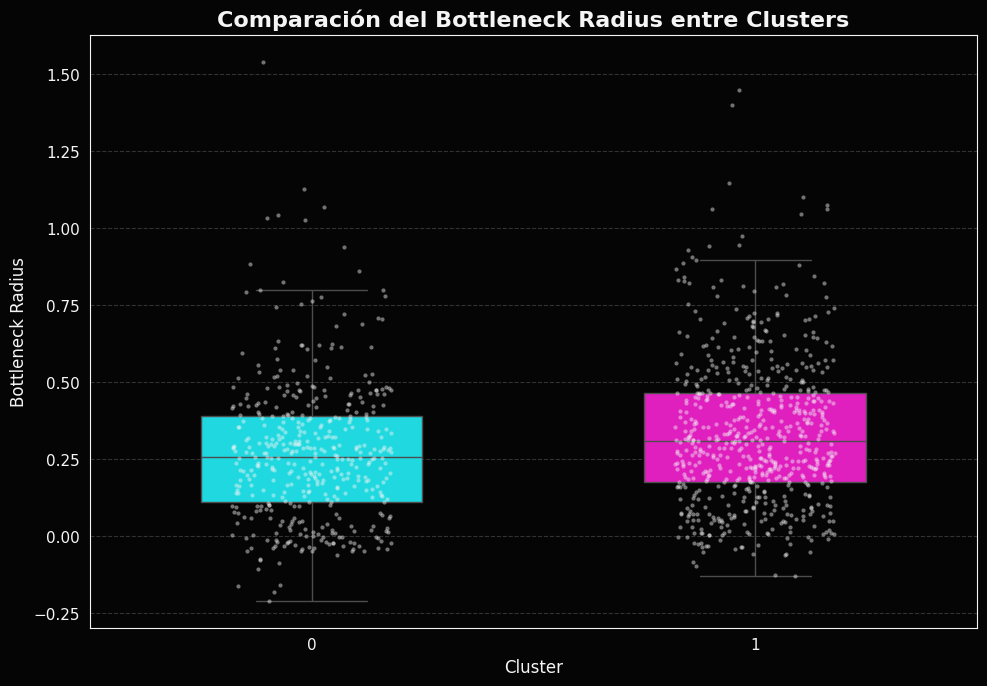


RESUMEN DESCRIPTIVO
 Grupo   n   Media  Desviación estándar  Mediana
     0 428 0.27159              0.22839    0.257
     1 627 0.33461              0.23708    0.309

Diferencia de medias A - B: -0.063019
p-valor de permutación: 0.000100


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# ESTÉTICA BLACK NEON
# ============================================================

plt.style.use("dark_background")

BLACK = "#050505"
WHITE = "#F5F5F5"
GRAY = "#777777"
CYAN = "#00F5FF"
MAGENTA = "#FF00D4"
LIME = "#B6FF00"
PURPLE = "#9D4EDD"
ORANGE = "#FF6B35"

neon_colors = [CYAN, MAGENTA, LIME, PURPLE, ORANGE]

sns.set_style("dark")

plt.rcParams.update({
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": WHITE,
    "ytick.color": WHITE,
    "grid.color": GRAY,
    "grid.alpha": 0.20,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
    "font.size": 11,
})



# ============================================================
# 1. CONFIGURACIÓN DE LOS GRUPOS
# ============================================================

cluster_col = "cluster"
variable = "bottleneck_radius"

grupo_a = 0
grupo_b = 1

n_permutaciones = 10000
rng = np.random.default_rng(42)

# ============================================================
# 2. SELECCIÓN Y LIMPIEZA
# ============================================================

if "cluster" not in df_results.columns and "df_time" in globals() and "cluster" in df_time.columns:
    df_results["cluster"] = df_time["cluster"]

if cluster_col not in df_results.columns:
    raise ValueError(
        f"No existe la columna '{cluster_col}'. "
        "Sustituye cluster_col por el nombre real "
        "de la columna que contiene los clusters."
    )

if variable not in df_results.columns:
    raise ValueError(
        f"No existe la variable '{variable}'."
    )

datos = df_results[[cluster_col, variable]].copy()

datos[variable] = pd.to_numeric(
    datos[variable],
    errors="coerce"
)

datos[variable] = datos[variable].replace(
    [np.inf, -np.inf],
    np.nan
)

datos = datos.dropna(
    subset=[cluster_col, variable]
)

datos = datos[
    datos[cluster_col].isin([grupo_a, grupo_b])
].copy()

if datos[cluster_col].nunique() != 2:
    raise ValueError(
        "Deben existir observaciones válidas "
        "en ambos grupos."
    )

valores_a = datos.loc[
    datos[cluster_col] == grupo_a,
    variable
].to_numpy()

valores_b = datos.loc[
    datos[cluster_col] == grupo_b,
    variable
].to_numpy()

if len(valores_a) < 2 or len(valores_b) < 2:
    raise ValueError(
        "Se necesitan al menos dos observaciones "
        "por grupo."
    )

# Diferencia observada: media A menos media B
diferencia_observada = (
    np.mean(valores_a) - np.mean(valores_b)
)

print("=" * 65)
print("ACTIVIDAD 15: PRUEBA DE PERMUTACIÓN")
print("=" * 65)

print(f"Grupo A: {grupo_a}")
print(f"Grupo B: {grupo_b}")
print(f"n(A) = {len(valores_a)}")
print(f"n(B) = {len(valores_b)}")

print(f"\nMedia A: {np.mean(valores_a):.6f}")
print(f"Media B: {np.mean(valores_b):.6f}")
print(
    f"Diferencia observada (A - B): "
    f"{diferencia_observada:.6f}"
)

# ============================================================
# 3. PRUEBA DE PERMUTACIÓN CONVENCIONAL
# ============================================================

valores = datos[variable].to_numpy()
etiquetas = datos[cluster_col].to_numpy()

n_a = np.sum(etiquetas == grupo_a)
n_total = len(datos)

diferencias_perm = np.empty(n_permutaciones)

for i in range(n_permutaciones):

    etiquetas_perm = rng.permutation(etiquetas)

    media_a_perm = valores[
        etiquetas_perm == grupo_a
    ].mean()

    media_b_perm = valores[
        etiquetas_perm == grupo_b
    ].mean()

    diferencias_perm[i] = (
        media_a_perm - media_b_perm
    )

# p-valor bilateral con corrección de Monte Carlo
p_permutacion = (
    1 + np.sum(
        np.abs(diferencias_perm)
        >= abs(diferencia_observada)
    )
) / (n_permutaciones + 1)

print("\n" + "=" * 65)
print("RESULTADOS: PERMUTACIÓN CONVENCIONAL")
print("=" * 65)

print("Permutaciones:", n_permutaciones)
print(
    f"p-valor bilateral: {p_permutacion:.6f}"
)

if p_permutacion < 0.05:
    print(
        "Resultado: existe evidencia estadística "
        "de una diferencia entre las medias "
        "bajo los supuestos de la prueba."
    )
else:
    print(
        "Resultado: no se obtiene evidencia "
        "suficiente de una diferencia entre las medias "
        "al nivel del 5 %."
    )

# ============================================================
# 4. DISTRIBUCIÓN NULA
# ============================================================

fig1, ax1 = plt.subplots(figsize=(12, 7))
fig1.patch.set_facecolor(BLACK)

sns.histplot(
    diferencias_perm,
    bins=50,
    stat="density",
    color=CYAN,
    alpha=0.35,
    edgecolor=WHITE,
    linewidth=0.4,
    ax=ax1
)

sns.kdeplot(
    diferencias_perm,
    color=CYAN,
    linewidth=2.5,
    ax=ax1
)

ax1.axvline(
    0,
    color=WHITE,
    linestyle="--",
    linewidth=1.5,
    label="Diferencia nula"
)

ax1.axvline(
    diferencia_observada,
    color=LIME,
    linewidth=2.5,
    label=(
        f"Diferencia observada = "
        f"{diferencia_observada:.3f}"
    )
)

ax1.axvline(
    -abs(diferencia_observada),
    color=ORANGE,
    linestyle=":",
    linewidth=2
)

ax1.axvline(
    abs(diferencia_observada),
    color=ORANGE,
    linestyle=":",
    linewidth=2,
    label="Extremos de la prueba bilateral"
)

ax1.set_title(
    "Distribución Nula de la Diferencia de Medias",
    color=WHITE,
    fontsize=16
)

ax1.set_xlabel(
    "Diferencia de medias: grupo A - grupo B",
    fontsize=12
)

ax1.set_ylabel("Densidad", fontsize=12)
ax1.tick_params(colors=WHITE)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, labelcolor=WHITE)

for spine in ax1.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 5. COMPARACIÓN VISUAL ENTRE LOS GRUPOS
# ============================================================

fig2, ax2 = plt.subplots(figsize=(10, 7))
fig2.patch.set_facecolor(BLACK)

sns.boxplot(
    data=datos,
    x=cluster_col,
    y=variable,
    order=[grupo_a, grupo_b],
    palette=[CYAN, MAGENTA],
    width=0.5,
    showfliers=False,
    ax=ax2
)

sns.stripplot(
    data=datos,
    x=cluster_col,
    y=variable,
    order=[grupo_a, grupo_b],
    color=WHITE,
    alpha=0.45,
    size=3,
    jitter=0.18,
    ax=ax2
)

ax2.set_title(
    "Comparación del Bottleneck Radius entre Clusters",
    color=WHITE,
    fontsize=16
)

ax2.set_xlabel("Cluster", fontsize=12)
ax2.set_ylabel("Bottleneck Radius", fontsize=12)
ax2.tick_params(colors=WHITE)
ax2.grid(True, axis="y", linestyle="--", alpha=0.4)

for spine in ax2.spines.values():
    spine.set_color(WHITE)

plt.tight_layout()
plt.show()

# ============================================================
# 6. RESUMEN FINAL
# ============================================================

resumen = pd.DataFrame({
    "Grupo": [grupo_a, grupo_b],
    "n": [len(valores_a), len(valores_b)],
    "Media": [
        np.mean(valores_a),
        np.mean(valores_b)
    ],
    "Desviación estándar": [
        np.std(valores_a, ddof=1),
        np.std(valores_b, ddof=1)
    ],
    "Mediana": [
        np.median(valores_a),
        np.median(valores_b)
    ]
})

print("\nRESUMEN DESCRIPTIVO")
print(resumen.round(5).to_string(index=False))

print("\nDiferencia de medias A - B:",
      f"{diferencia_observada:.6f}")

print("p-valor de permutación:",
      f"{p_permutacion:.6f}")

plt.style.use("default")

#### Respuestas :


**1. ¿Existe evidencia de diferencia entre los grupos?**

Con un a diferencia entre las medias de los clusters 0 y 1 de -0,063 con un p-valor de permutación de 0,0001 existe evidencia estadística de una diferencia entre las medias, si se cumplen los supuestos de la prueba.

**2. ¿Qué supuesto permite realizar la permutación?**

El supuesto fundamental es la intercambiabilidad de las etiquetas bajo la hipótesis nula: bajo las condiciones del contraste, las etiquetas podrían reasignarse sin alterar la distribución conjunta relevante de los datos. No basta con permutar etiquetas para garantizar la validez de la prueba.

**3. ¿La dependencia temporal vuelve problemática esta prueba?**

Sí, los frames consecutivos pueden estar correlacionados y existen cambios estructurales aparentes alrededor de los frames 200 y 800. La permutación convencional mezcla observaciones de diferentes momentos y destruye la estructura temporal. En consecuencia, su p-valor podría ser demasiado pequeño y la evidencia de diferencias entre clusters parecer más fuerte de lo que realmente es. Si los dos clusters corresponden esencialmente a dos estados temporales continuos, no es válido asumir que sus etiquetas se pueden intercambiar libremente.

---

# PARTE XV — VALIDACIÓN Y DATA LEAKAGE

## Actividad 16. Un modelo demasiado optimista

Considerar el siguiente procedimiento:

```text
Todos los datos
      ↓
Buscar variables con mayor correlación
      ↓
Seleccionar las mejores variables
      ↓
Construir modelo
      ↓
5-fold cross-validation
      ↓
Calcular RMSE
```

### Pregunta

¿Este procedimiento proporciona una estimación válida del rendimiento predictivo?

Justificar.



No, el procedimiento descrito no proporciona necesariamente una estimación válida del rendimiento predictivo. El problema es que se seleccionan las variables usando todos los datos antes de realizar la validación cruzada de cinco particiones (5-fold cross-validation). Aunque el modelo se entrene y evalúe en particiones diferentes, la selección previa de variables ya ha utilizado información de las futuras particiones de evaluación.

Por tanto, la validación cruzada deja de proporcionar una evaluación completamente independiente del proceso de selección. La solución consiste en repetir la selección de variables desde cero dentro de cada partición de entrenamiento.

---

## Actividad 17. Diseñar un pipeline correcto

Proponer un esquema de validación en el que:

1. los datos sean divididos;
2. la selección de variables se realice únicamente con los datos de entrenamiento;
3. el modelo sea ajustado con entrenamiento;
4. el modelo sea evaluado sobre datos no utilizados durante el entrenamiento.

Representar gráficamente el pipeline.

Explicar qué es **data leakage** y por qué puede producir una estimación artificialmente optimista del rendimiento.

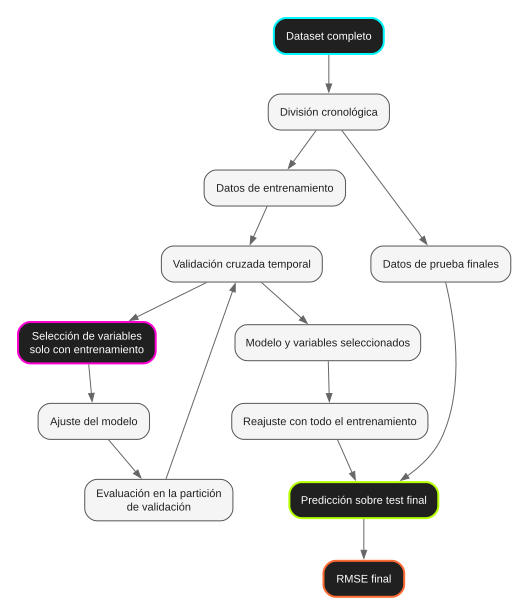

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import requests
from IPython.display import SVG, display

dot_code = r"""
digraph Workflow {
    rankdir=TB;
    graph [
        bgcolor="white",
        nodesep=0.35,
        ranksep=0.55,
        pad=0.25
    ];

    node [
        shape=box,
        style="rounded,filled",
        fillcolor="#F5F5F5",
        color="#555555",
        fontcolor="#202020",
        fontname="Arial",
        fontsize=11,
        margin="0.18,0.10"
    ];

    edge [
        color="#666666",
        arrowsize=0.8,
        fontname="Arial",
        fontsize=10
    ];

    A [label="Dataset completo",
       fillcolor="#202020", color="#00F5FF",
       fontcolor="white", penwidth=2];

    B [label="División cronológica"];
    C [label="Datos de entrenamiento"];
    H [label="Datos de prueba finales"];

    D [label="Validación cruzada temporal"];

    E [label="Selección de variables\nsolo con entrenamiento",
       fillcolor="#202020", color="#FF00D4",
       fontcolor="white", penwidth=2];

    F [label="Ajuste del modelo"];
    G [label="Evaluación en la partición\nde validación"];

    I [label="Modelo y variables seleccionados"];
    J [label="Reajuste con todo el entrenamiento"];

    K [label="Predicción sobre test final",
       fillcolor="#202020", color="#B6FF00",
       fontcolor="white", penwidth=2];

    L [label="RMSE final",
       fillcolor="#202020", color="#FF6B35",
       fontcolor="white", penwidth=2];

    A -> B;
    B -> C;
    B -> H;
    C -> D;
    D -> E;
    E -> F;
    F -> G;
    G -> D;
    D -> I;
    I -> J;
    J -> K;
    H -> K;
    K -> L;
}
"""

response = requests.post(
    "https://kroki.io/graphviz/svg",
    data=dot_code.encode("utf-8"),
    headers={"Content-Type": "text/plain"},
    timeout=60
)

response.raise_for_status()
display(SVG(response.content))

with open("flowchart.svg", "wb") as f:
    f.write(response.content)

from google.colab import files
files.download("flowchart.svg")


## Implementacion del modelo en Python:

Número de observaciones: 1055
Variables candidatas: ['recipe_id', 'length', 'dz', 'tortuosity', 'bottleneck_free_radius', 'bottleneck_bradius', 'n_layers', 'charge', 'ionizable', 'num_positives', 'num_negatives', 'hydrophobicity', 'hydropathy', 'polarity', 'logp', 'logd', 'logs', 'mutability']

Entrenamiento: 844
Test final: 211

RMSE EN VALIDACIÓN CRUZADA TEMPORAL
RMSE por partición: [0.15328 0.      0.      0.14486 0.     ]
RMSE medio: 0.05963
Desviación estándar: 0.08170

Variables seleccionadas:
['length', 'bottleneck_free_radius', 'bottleneck_bradius']

EVALUACIÓN FINAL
RMSE test: 0.00000


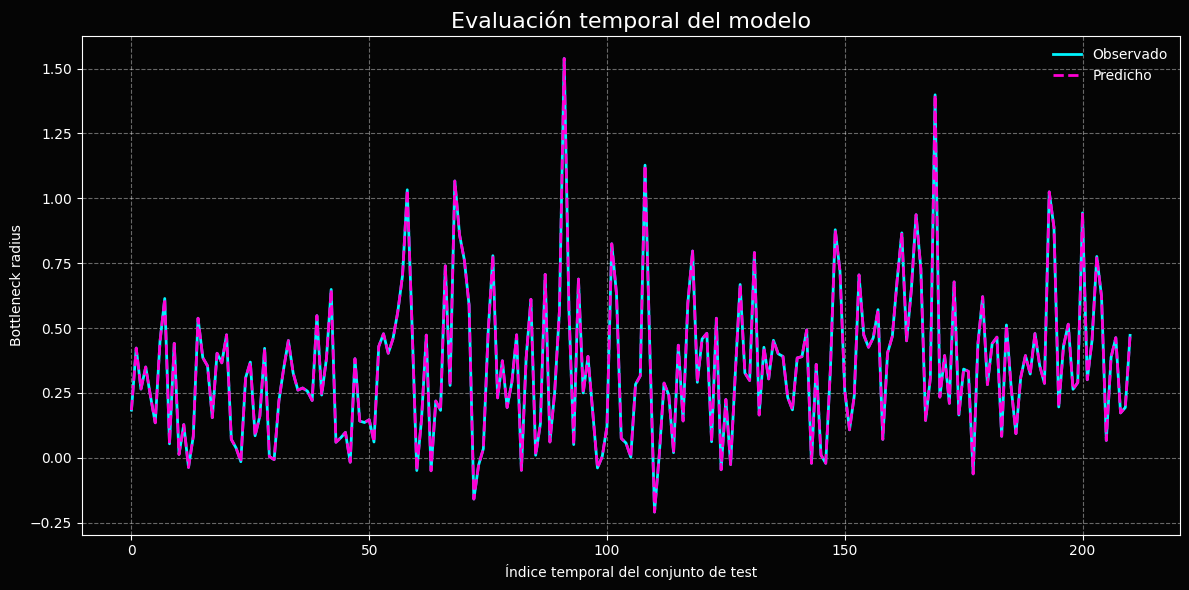

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import root_mean_squared_error

# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

target = "bottleneck_radius"

# df_results debe estar ordenado cronológicamente.
df = df_results.copy()

# Definir explícitamente las variables predictoras.
# Excluir la variable objetivo y columnas que no deban
# utilizarse como predictores.
columnas_excluir = [
    target,
    "frame",
    "cluster"
]

features = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in columnas_excluir
]

if len(features) < 2:
    raise ValueError(
        "Se necesitan al menos dos variables predictoras "
        "para realizar la selección de variables."
    )

data = df[[target] + features].replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

X = data[features]
y = data[target]

print("Número de observaciones:", len(data))
print("Variables candidatas:", features)

# ============================================================
# 2. DIVISIÓN CRONOLÓGICA: 80 % / 20 %
# ============================================================

split_idx = int(0.80 * len(data))

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

if len(X_train) < 10 or len(X_test) < 2:
    raise ValueError(
        "Hay muy pocas observaciones para esta división."
    )

print("\nEntrenamiento:", len(X_train))
print("Test final:", len(X_test))

# ============================================================
# 3. PIPELINE SIN DATA LEAKAGE EN LA SELECCIÓN
# ============================================================

# k debe ser menor o igual al número de predictores.
k = min(3, len(features))

pipeline = Pipeline([
    (
        "seleccion",
        SelectKBest(
            score_func=f_regression,
            k=k
        )
    ),
    (
        "modelo",
        LinearRegression()
    )
])

# ============================================================
# 4. VALIDACIÓN CRUZADA TEMPORAL
# ============================================================

cv = TimeSeriesSplit(n_splits=5)

rmse_cv = -cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print("\nRMSE EN VALIDACIÓN CRUZADA TEMPORAL")
print("RMSE por partición:", np.round(rmse_cv, 5))
print(f"RMSE medio: {rmse_cv.mean():.5f}")
print(f"Desviación estándar: {rmse_cv.std(ddof=1):.5f}")

# ============================================================
# 5. AJUSTE FINAL SOLO CON ENTRENAMIENTO
# ============================================================

pipeline.fit(X_train, y_train)

# Identificar las variables seleccionadas.
mascara = pipeline.named_steps[
    "seleccion"
].get_support()

variables_seleccionadas = np.array(features)[mascara]

print("\nVariables seleccionadas:")
print(variables_seleccionadas.tolist())

# ============================================================
# 6. EVALUACIÓN FINAL EN DATOS NO UTILIZADOS
# ============================================================

y_pred = pipeline.predict(X_test)

rmse_test = root_mean_squared_error(
    y_test,
    y_pred
)

print("\nEVALUACIÓN FINAL")
print(f"RMSE test: {rmse_test:.5f}")

# ============================================================
# 7. GRÁFICO DE VALORES OBSERVADOS Y PREDICHOS
# ============================================================

plt.style.use("dark_background")

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#050505")
ax.set_facecolor("#050505")

ax.plot(
    np.arange(len(y_test)),
    y_test.to_numpy(),
    color="#00F5FF",
    linewidth=2,
    label="Observado"
)

ax.plot(
    np.arange(len(y_pred)),
    y_pred,
    color="#FF00D4",
    linewidth=2,
    linestyle="--",
    label="Predicho"
)

ax.set_title(
    "Evaluación temporal del modelo",
    color="white",
    fontsize=16
)

ax.set_xlabel("Índice temporal del conjunto de test")
ax.set_ylabel("Bottleneck radius")

ax.grid(True, linestyle="--", alpha=0.4)
ax.tick_params(colors="white")
ax.legend(frameon=False)

for spine in ax.spines.values():
    spine.set_color("white")

plt.tight_layout()
plt.show()

plt.style.use("default")

### Data Leakage
El data leakage o fuga de información ocurre cuando el proceso de entrenamiento utiliza información que no estaría disponible legítimamente en el momento de realizar una predicción, o información de evaluación que contamina la construcción del modelo.

En el procedimiento de la actividad 16, la fuga se produce al calcular las correlaciones y seleccionar las mejores variables usando el dataset completo antes de la validación cruzada.

Esto puede generar una estimación artificialmente optimista porque el modelo se beneficia indirectamente de patrones específicos de las observaciones que después se utilizan para evaluarlo.

Para evitarlo:

* La selección de variables debe realizarse exclusivamente con los datos de entrenamiento de cada partición.

* Cualquier transformación o ajuste de hiperparámetros debe aprenderse dentro del entrenamiento.

* El test final debe permanecer intacto hasta la evaluación definitiva.

* En datos temporales, la separación debe respetar el orden temporal y la dependencia entre observaciones.



---

# PARTE XVI — INTEGRACIÓN

## Actividad 18. La investigación estadística

Integrar los resultados de al menos **tres métodos diferentes**.

Responder:

> **¿Qué características parecen estar asociadas con la variabilidad del túnel de TMEM63A a lo largo de la trayectoria?**

La respuesta deberá integrar, como mínimo:

* un resultado de asociación/regresión;
* un resultado multivariante;
* un resultado de remuestreo o análisis temporal.

No se espera simplemente una lista de resultados.

Deberán construir una interpretación coherente.

#### Respuesta:

El objetivo de esta investigación es identificar qué propiedades geométricas y fisicoquímicas parecen asociarse con la variabilidad del túnel de TMEM63A a lo largo de la trayectoria simulada. Para ello, se integran los resultados de los análisis de correlación y regresión, el análisis multivariante mediante PCA y clustering, y los procedimientos de remuestreo y análisis temporal.

Los resultados obtenidos no permiten identificar un único factor que explique satisfactoriamente las variaciones del radio del cuello de botella (bottleneck_radius). Sin embargo, sí muestran una estructura de dependencias entre variables geométricas, una evolución temporal no estacionaria en algunas propiedades y limitaciones importantes en la capacidad de los modelos para explicar la variabilidad observada. En particular, la longitud y la tortuosidad parecen estar relacionadas entre sí y con determinados cambios temporales, mientras que las variables fisicoquímicas muestran un comportamiento parcialmente diferenciado.

En primer lugar, los análisis de correlación y regresión apuntan a una asociación entre las características geométricas y el radio del cuello de botella, aunque con una capacidad explicativa limitada. La longitud y la tortuosidad presentan una correlación de Pearson de 0,67, mientras que la longitud y el desplazamiento en el eje Z (dz) alcanzan una correlación de 0,76. Estos resultados indican que determinadas características geométricas tienden a variar conjuntamente a lo largo de las observaciones. Sin embargo, también implican que las variables geométricas no son completamente independientes entre sí.

En cuanto al radio del cuello de botella (bottleneck radius), las regresiones lineales individuales muestran pendientes negativas tanto para la tortuosidad como para la longitud. En el primer caso, la pendiente es de −0,2166, con un R2 ajustado de 0,023; en el segundo, la pendiente es de −0,0017, con un R2 ajustado de 0,020. Aunque las pendientes presentan valores p pequeños, los coeficientes de determinación indican que cada modelo explica únicamente alrededor del 2 % de la variabilidad del radio. Por tanto, la significación estadística no debe confundirse con una capacidad explicativa elevada: existe evidencia de asociación lineal, pero su magnitud explicativa es reducida.

Esto sugiere que la longitud y la tortuosidad podrían describir aspectos relacionados de la geometría global del túnel, pero no son suficientes para predecir su radio local. Una trayectoria puede ser más larga o sinuosa sin que ello implique necesariamente que su cuello de botella se estreche de forma proporcional.

El modelo múltiple obtenido fue:
radius^=0,5376−0,1267 tortuosity−0,0008 length+0,0128 polarity+0,0961 hydrophobicity−0,0035 charge
radius
=​0,5376−0,1267tortuosity−0,0008length+0,0128polarity+0,0961hydrophobicity−0,0035charge​

En este modelo, la tortuosidad conservó una asociación negativa estadísticamente significativa con el radio (p=0,030
p=0,030), mientras que la longitud dejó de ser significativa al controlar por las demás variables (p=0,088
p=0,088). La pérdida de significación de la longitud podría indicar que parte de la información que aporta individualmente se solapa con la de la tortuosidad. Sin embargo, no demuestra por sí sola que la longitud carezca de relevancia estructural.  No obstante,Los valores del factor de inflación de la varianza (VIF) entre 1,15 y 1,88 no indican una multicolinealidad severa según los criterios habituales. Por ello, no sería correcto atribuir automáticamente la pérdida de significación de la longitud a un problema grave de colinealidad.

Por otra parte, ni la carga ni la hidrofobicidad presentan asociaciones estadísticamente significativas con el radio en el modelo múltiple. Aunque la hidrofobicidad y el logD muestran una correlación elevada entre sí (r=0,87), esta relación describe una asociación entre propiedades fisicoquímicas y no demuestra que estas determinen directamente la geometría del túnel. En conjunto, los resultados favorecen una interpretación en la que las características geométricas están más directamente asociadas con las variaciones observadas del radio que las variables fisicoquímicas incluidas en el modelo. No obstante, la presencia de heterocedasticidad (p=0,028), la desviación de la normalidad en las colas de los residuos y la existencia de observaciones potencialmente influyentes aconsejan interpretar con cautela los errores estándar y los valores p de las regresiones convencionales. Estas limitaciones afectan a la fiabilidad de la inferencia convencional de los coeficientes y aconsejan contrastar la robustez del modelo.

En segundo lugar, el análisis multivariante mediante componentes principales (PCA) respalda la existencia de una estructura de variabilidad en la que intervienen varias dimensiones, sin que una sola variable domine necesariamente el comportamiento del sistema. Los primeros componentes recogen una proporción importante de la varianza total, y con cinco componentes se alcanza aproximadamente entre el 80 % y el 90 % de la varianza acumulada. La distribución de las cargas factoriales sugiere que las variables geométricas, como la longitud, el desplazamiento en Z y la tortuosidad, contribuyen a una dimensión de variación relacionada con la geometría, mientras que propiedades como la carga, la polaridad, la hidrofobicidad y el logD contribuyen a otra dimensión predominantemente fisicoquímica.

Sin embargo, la presencia de cargas geométricas en más de un componente impide interpretar la variabilidad geométrica como un fenómeno unidimensional. El PCA sugiere, por tanto, que las observaciones pueden diferenciarse según varias combinaciones de características estructurales y fisicoquímicas. Esta interpretación debe mantenerse en el plano descriptivo: los componentes principales identifican patrones de covariación, pero no establecen qué propiedades causan los cambios del túnel.

Los análisis de clustering refuerzan esta cautela. Tanto k-means como el agrupamiento jerárquico de Ward presentan coeficientes de silhouette bajos, con máximos próximos a 0,175. Además, el índice de Rand ajustado (ARI) cercano a cero indica que ambos procedimientos no recuperan particiones similares. Por ello, aunque se observan diferencias entre grupos y cierta asociación con el segundo componente principal, no existe evidencia suficientemente sólida para afirmar que los grupos identificados representen estados estructurales claramente diferenciados. La variabilidad parece describirse mejor mediante cambios graduales y combinaciones de variables que mediante una separación inequívoca en categorías.

En tercer lugar, el análisis temporal y los procedimientos de remuestreo indican que la variabilidad no debe interpretarse como una sucesión de observaciones independientes. Se identifican cambios en la media de la longitud y la tortuosidad alrededor del frame 200, sin cambios equivalentes claramente observables en las variables fisicoquímicas analizadas. Además, la evolución temporal de los grupos obtenidos mediante clustering sugiere modificaciones en su frecuencia relativa alrededor de los frames 200 y 800. Estos patrones son compatibles con una evolución temporal de la geometría del túnel, aunque no permiten demostrar por sí solos la existencia de transiciones entre estados estructurales discretos.

El remuestreo bootstrap de la correlación entre el radio del cuello de botella y la tortuosidad proporciona un resultado complementario. La correlación observada es de −0,1535 y la media bootstrap de −0,1539, con un intervalo de confianza del 95 % compatible con la estimación paramétrica de Fisher. Esta concordancia indica que ambos procedimientos ofrecen estimaciones compatibles de la asociación y que el signo y la magnitud de la correlación no cambian sustancialmente bajo el esquema de remuestreo empleado. Sin embargo, la correlación sigue siendo débil: la estabilidad de una estimación no implica que la relación sea intensa ni que tenga una elevada capacidad explicativa.

De forma similar, la estabilidad observada mediante bootstrap en las regresiones del radio frente a la tortuosidad, tanto en el remuestreo convencional como en los análisis por bloques y segmentos temporales, aporta información sobre la sensibilidad de las estimaciones. No obstante, debe distinguirse la estabilidad de los coeficientes de la validez global del modelo. Un modelo puede producir pendientes relativamente estables y, al mismo tiempo, explicar una proporción muy pequeña de la variabilidad. Además, si existe dependencia entre frames consecutivos, los resultados de remuestreo deben interpretarse teniendo en cuenta que los métodos que preservan la estructura temporal son más apropiados que aquellos que consideran todas las observaciones intercambiables.

Esta limitación también afecta a la comparación entre los grupos de clustering. La prueba de permutación convencional detecta una diferencia entre las medias del radio del cuello de botella de aproximadamente −0,063, con un valor p de 0,0001. Sin embargo, si los frames consecutivos están correlacionados y las etiquetas de los grupos reflejan parcialmente la evolución temporal, la permutación aleatoria destruye esa dependencia. En consecuencia, el valor p podría ser demasiado pequeño y exagerar la evidencia de una diferencia entre grupos. Para evaluar con mayor rigor esta asociación sería preferible emplear permutaciones por bloques o procedimientos que preserven la estructura temporal de la trayectoria.

En conclusión, los distintos métodos convergen en una interpretación prudente: la variabilidad del túnel de TMEM63A parece estar asociada principalmente con la dinámica de sus características geométricas, aparentemente la longitud y la tortuosidad, dentro de una trayectoria que presenta cambios temporales y cuya variabilidad no queda bien resumida por un único predictor lineal. Las propiedades fisicoquímicas muestran patrones propios de covariación, pero los resultados disponibles no aportan evidencia suficiente para atribuirles una asociación independiente clara con el radio del cuello de botella. El PCA sugiere que intervienen varias dimensiones de variabilidad, mientras que el clustering no identifica grupos suficientemente separados como para justificar la existencia de estados estructurales discretos. Finalmente, el bootstrap respalda cierta estabilidad de las asociaciones estimadas, pero los bajos valores de R2, la heterocedasticidad y la posible autocorrelación temporal limitan la fuerza de las conclusiones. Por tanto, los resultados permiten identificar patrones de asociación y evolución temporal, pero no establecer causalidad ni determinar de manera concluyente el mecanismo estructural responsable de los cambios del túnel.

#### Notas importantes:

* Significación no equivale a importancia explicativa -> p-valores buenos, pero bajo R-cuadrado ajustado.
* Un bootstrap estable no demuestra que el modelo sea correcto -> Que la correlación bootstrap coincida con la de Fisher es una señal de concordancia entre estimaciones, no una prueba de causalidad ni de ausencia de sesgos. Además, el intervalo de confianza concreto importa para evaluar la precisión de la correlación.
* La dimensión temporal puede condicionar los demás resultados ->  Los cambios alrededor de los frames 200 y 800 podrían contribuir tanto a las asociaciones geométricas como a las diferencias entre clusters. Por eso, conviene evitar interpretar todas las observaciones como si fueran independientes y distinguir los cambios de la trayectoria de las relaciones entre variables.

Además:

* **Correlación y regresión** -> La geometría presenta asociaciones internas y la tortuosidad conserva una asociación negativa con el radio en el modelo múltiple -> **Pero NO permite afirmar que la tortuosidad explique una gran proporción de la variabilidad del radio.**
* **PCA y clustering** -> La variabilidad puede organizarse en varias dimensiones, pero no aparecen grupos claramente separados. -> **No permite afirmar que existan dos o tres estados estructurales bien definidos.**
* **Análisis temporal** -> Aparecen cambios geométricos en determinados momentos de la trayectoria. -> **No permite afrmar que los cambios temporales sean transiciones estructurales causales**
* **Bootstrap** -> Las estimaciones de algunas asociaciones son relativamente estables ->  **No permite afirmar que los valores p convencionales sean plenamente fiables.**

---

# PARTE XVII — ¿QUÉ NO PODEMOS CONCLUIR?

## Actividad 19. Estadística ≠ causalidad

Escribir:

### Tres conclusiones que los datos permiten sostener.

y

### Tres conclusiones que NO pueden sostenerse a partir del análisis.

Por ejemplo, una asociación estadística entre tortuosidad y radio del cuello de botella **no permite afirmar automáticamente que la tortuosidad cause cambios en el radio**.

Para cada conclusión deberán explicar por qué.


### Respuesta:

#### **Tres conclusiones que los datos permiten sostener**

1. La tortuosidad presenta una asociación negativa con el radio del cuello de botella del túnel de TMEM63A.

Las regresiones lineales muestran una pendiente negativa entre ambas variables (−0,2166), y en la regresión múltiple la tortuosidad mantiene una asociación estadísticamente significativa con el radio (p=0,030
p=0,030). Además, el bootstrap proporciona una correlación media de −0,1539, compatible con la estimación paramétrica. Estos resultados respaldan la existencia de una asociación negativa, aunque débil. El R2
R2 ajustado de 0,023 indica que la regresión simple explica una proporción muy reducida de la variabilidad del radio.

2. La longitud y la tortuosidad presentan una variación conjunta a lo largo de la trayectoria.

La correlación de Pearson entre ambas variables es de 0,67, lo que indica una asociación positiva relativamente marcada. Además, alrededor del frame 200 se observan cambios en sus medias. Estos resultados permiten afirmar que ambas características geométricas están relacionadas y que su comportamiento varía a lo largo de la trayectoria. Sin embargo, no demuestran que una variable determine los cambios de la otra.

3. La trayectoria presenta variaciones temporales y no se identifican grupos estructurales claramente diferenciados mediante clustering.

Los cambios observados en la longitud y la tortuosidad alrededor del frame 200, junto con las modificaciones en la frecuencia de los grupos de clustering alrededor de los frames 200 y 800, sugieren que la geometría evoluciona durante la trayectoria. Sin embargo, los coeficientes de silhouette, próximos a 0,175, indican una separación muy débil entre los grupos. Por tanto, los resultados permiten identificar patrones temporales, pero no establecer que existan estados estructurales discretos bien definidos.

#### **Tres conclusiones que NO pueden sostenerse a partir del análisis**

1. No se puede afirmar que un aumento de la tortuosidad cause una disminución del radio del cuello de botella.

Aunque la asociación observada es negativa y estadísticamente significativa en la regresión múltiple, el análisis es observacional y no demuestra una relación causal. Ambas variables podrían responder a otros cambios geométricos o estructurales que no se han incluido en el modelo. Además, la capacidad explicativa de la regresión simple es muy baja (R2
R2 ajustado de 0,023), por lo que la tortuosidad no explica por sí sola los cambios del radio.

2. No se puede afirmar que las propiedades fisicoquímicas sean irrelevantes para la variabilidad del túnel.

La carga y la hidrofobicidad no presentan asociaciones estadísticamente significativas con el radio en la regresión múltiple. Sin embargo, la ausencia de significación estadística no demuestra que no exista una relación. Su efecto podría ser débil, no lineal, dependiente de otras variables o difícil de detectar con los datos disponibles. Por tanto, solo puede concluirse que el análisis realizado no aporta evidencia suficiente de una asociación independiente significativa para esas variables.

3. No se puede afirmar que los grupos identificados mediante clustering representen estados estructurales distintos ni que sus diferencias sean necesariamente significativas en términos temporales.

Aunque la prueba de permutación convencional detecta una diferencia entre las medias del radio de los dos grupos (p=0,0001), los bajos coeficientes de silhouette y el ARI cercano a cero indican que la separación entre grupos es débil y que los dos métodos de clustering no recuperan particiones similares. Además, la permutación convencional puede generar valores p demasiado pequeños si destruye la dependencia entre frames consecutivos. Por ello, no puede concluirse que los grupos correspondan a estados estructurales reales ni que la diferencia observada sea independiente de la evolución temporal.
Conclusión general


### Conclusión final
La integración de los análisis estadísticos indica que la variabilidad del túnel de TMEM63A presenta una estructura compleja que no puede explicarse adecuadamente mediante una única variable. Los análisis de correlación y regresión muestran una asociación positiva relativamente fuerte entre longitud y tortuosidad, así como entre longitud y desplazamiento en z. Sin embargo, las relaciones del radio del cuello de botella con la longitud y la tortuosidad son débiles y presentan una capacidad explicativa muy reducida, con valores de R² ajustado próximos a 0,02. En el modelo múltiple, la tortuosidad conserva una asociación negativa estadísticamente significativa, aunque el diagnóstico revela heterocedasticidad, desviaciones de la normalidad en las colas y observaciones potencialmente influyentes, por lo que la inferencia requiere cautela.

El análisis multivariante mediante PCA sugiere que la variabilidad puede resumirse en dimensiones parcialmente geométricas y fisicoquímicas. No obstante, los resultados del clustering no respaldan una separación clara entre estados estructurales, dado que los valores de Silhouette son bajos y los algoritmos considerados no recuperan particiones similares. Por ello, no puede afirmarse que existan estados discretos bien definidos a partir de los clusters obtenidos.

El análisis temporal muestra cambios aparentes en las medias de longitud y tortuosidad alrededor de los frames 200 y 800, sin modificaciones equivalentes claramente observadas en las propiedades fisicoquímicas. Los análisis bootstrap indican que determinadas estimaciones, como la correlación entre radio del cuello de botella y tortuosidad, son relativamente estables frente a los esquemas de remuestreo utilizados. Sin embargo, la dependencia temporal de los frames exige especial precaución al estimar la incertidumbre.

En conjunto, los resultados sugieren que la geometría global del túnel presenta variaciones temporales coordinadas, mientras que las propiedades analizadas no explican suficientemente los cambios del radio local del cuello de botella. Es posible que intervengan relaciones no lineales, interacciones o características estructurales no incluidas en los modelos. Debido a las limitaciones explicativas, a la dependencia temporal y a la ausencia de una estructura de clusters bien definida, las conclusiones deben considerarse exploratorias. Para avanzar, sería conveniente realizar análisis temporales que respeten la autocorrelación, comprobar formalmente los puntos de cambio y evaluar modelos alternativos capaces de representar relaciones no lineales.

---

# 5. Informe final

El informe deberá tener la siguiente estructura:

## 1. Introducción

Presentar brevemente:

* problema biológico;
* características de los datos;
* pregunta estadística.

## 2. Materiales y métodos

Describir:

* dataset;
* variables utilizadas;
* métodos estadísticos;
* criterios utilizados para seleccionar variables;
* métodos de remuestreo;
* métodos de validación.

No es necesario copiar código completo en esta sección.

## 3. Resultados

Presentar los principales resultados de:

* exploración;
* correlación;
* regresión;
* diagnóstico;
* PCA;
* clustering;
* bootstrap;
* permutación;
* análisis temporal.

## 4. Discusión

Interpretar los resultados.

Discutir:

* magnitud de los efectos;
* incertidumbre;
* supuestos;
* dependencia temporal;
* posibles limitaciones;
* significado biológico.

## 5. Conclusiones

Responder brevemente a la pregunta central.

## 6. Código

Incluir el código utilizado para reproducir los análisis.

---

# 6. Requisitos mínimos de figuras

El informe deberá contener como mínimo:

1. **2 gráficos exploratorios**.
2. **1 gráfico temporal**.
3. **1 matriz de correlación**.
4. **2 gráficos de regresión**.
5. **2 gráficos de diagnóstico**.
6. **1 scree plot**.
7. **1 gráfico PCA**.
8. **1 visualización de clustering**.
9. **1 gráfico de clusters vs frame**.
10. **1 distribución bootstrap**.
11. **1 distribución de permutación**.

Las figuras deberán tener:

* título;
* ejes correctamente identificados;
* unidades cuando correspondan;
* leyenda cuando sea necesaria;
* una breve explicación en el texto.

---

# 7. Requisitos estadísticos mínimos

El informe deberá incluir obligatoriamente:

* estadísticos descriptivos;
* al menos tres correlaciones;
* una regresión lineal simple;
* una regresión múltiple;
* análisis de VIF;
* diagnóstico de residuos;
* PCA;
* clustering;
* bootstrap;
* una prueba de permutación;
* discusión de dependencia temporal;
* discusión de data leakage/cross-validation.



---

# 8. Preguntas conceptuales finales

Responder brevemente:

### 1. ¿Cuál es la diferencia entre asociación y causalidad?

### 2. ¿Por qué un p-value pequeño no implica necesariamente un efecto biológicamente importante?

### 3. ¿Por qué dos variables altamente correlacionadas pueden generar problemas en una regresión múltiple?

### 4. ¿Qué información aporta PCA que no aporta una matriz de correlación?

### 5. ¿Encontrar tres clusters implica necesariamente que existen tres estados biológicos reales?

### 6. ¿Por qué el bootstrap convencional puede ser problemático para una trayectoria de MD?

### 7. ¿Qué es data leakage?

### 8. ¿Por qué la validación debe realizarse sobre datos que no participaron en el entrenamiento?

### 9. ¿Los 1055 frames deben considerarse necesariamente como 1055 observaciones independientes?

### 10. Si tuvieran que repetir este análisis para otra proteína, ¿qué aspectos del pipeline estadístico mantendrían y cuáles modificarían?

### Respuestas


1. La asociación indica que dos variables están relacionadas estadísticamente, mientras que la causalidad implica que los cambios en una variable producen cambios en otra. Una asociación, por sí sola, no demuestra causalidad.

2. Porque el p-value mide la compatibilidad de los datos con una hipótesis nula, no la magnitud ni la relevancia biológica del efecto. Una asociación puede ser estadísticamente significativa y explicar una proporción muy pequeña de la variabilidad, como ocurre con las regresiones del radio del cuello de botella.

3. Porque pueden aportar información redundante, dificultando la estimación de sus efectos individuales y aumentando la incertidumbre de los coeficientes. Este fenómeno se denomina multicolinealidad y puede hacer que variables significativas por separado dejen de serlo al incluirlas simultáneamente en el modelo. Por ello siempre es importante medir la colinealidad (VIF) y la correlación antes de incluir variables a la construcción de un modelo.

4. La matriz de correlación muestra las relaciones entre pares de variables, mientras que el análisis de componentes principales (PCA) combina varias variables en componentes que resumen la variabilidad conjunta del sistema. Permite identificar dimensiones principales de variación y reducir la dimensionalidad, aunque no establece causalidad.

5. No. Los clusters son agrupaciones matemáticas cuya existencia depende de los datos, las variables y el algoritmo utilizado. Es necesario evaluar su separación, estabilidad y coherencia biológica antes de interpretarlos como estados estructurales reales.

6. Porque el bootstrap convencional remuestrea observaciones individuales como si fueran independientes, ignorando la autocorrelación entre frames consecutivos. Esto puede subestimar la incertidumbre. El bootstrap por bloques suele ser más apropiado porque conserva parcialmente la dependencia temporal, siempre que se elija una longitud de bloque adecuada.

7. Es la filtración de información del conjunto de prueba o de datos futuros hacia el entrenamiento de un modelo. Produce evaluaciones excesivamente optimistas de su rendimiento. Para evitarlo, el preprocesamiento, la selección de variables y el ajuste de hiperparámetros deben realizarse sin utilizar información del conjunto de prueba.

8. Porque permite evaluar la capacidad de generalización del modelo ante datos nuevos. Si se evalúa con los mismos datos utilizados para entrenarlo, el rendimiento puede parecer mejor de lo que realmente es. En trayectorias de MD, además, conviene separar los datos respetando su dependencia temporal.

9. No. Los frames consecutivos de una trayectoria de dinámica molecular (MD) suelen presentar autocorrelación, porque las configuraciones estructurales evolucionan de manera continua. Por tanto, 1055 frames no equivalen necesariamente a 1055 observaciones independientes, y el tamaño muestral efectivo puede ser menor.

10. Mantendría la estructura general del pipeline: análisis exploratorio, evaluación de distribuciones, correlaciones, regresiones, diagnóstico de modelos, análisis multivariante y validación mediante remuestreo. Sin embargo, adaptaría las variables, los métodos y los criterios de evaluación a la pregunta biológica concreta. Por ejemplo, no utilizaría necesariamente el mismo enfoque para una proteína con regiones intrínsecamente desordenadas que para otra con una estructura estable y poca movilidad. También distinguiría entre estudios de plegamiento, interacciones proteína-proteína o cambios conformacionales relacionados con la función biológica. Según el objetivo, podrían ser más relevantes los análisis de flexibilidad local, las correlaciones temporales, las transiciones conformacionales o las interacciones entre residuos.



---

# 9. Producto final

El objetivo del trabajo no es obtener un determinado resultado estadístico.

Se evaluará la capacidad para:

> **formular una pregunta, seleccionar métodos apropiados, evaluar sus supuestos, cuantificar la incertidumbre e interpretar los resultados dentro de un contexto bioinformático.**

Una respuesta estadísticamente correcta pero biológicamente injustificada no será considerada una interpretación completa.

Del mismo modo, una conclusión negativa o inconclusa puede ser completamente válida si está correctamente sustentada por los análisis.

---

## Criterio transversal de evaluación

Durante todo el trabajo se valorará especialmente la capacidad de responder:

> **¿Este método estadístico es apropiado para estos datos y qué supuestos estoy haciendo al utilizarlo?**

No se evaluará únicamente la obtención de números o gráficos.

Se evaluará la capacidad de **razonar estadísticamente** a partir de ellos.